# 1.安装依赖与初始化大模型

In [14]:
# 安装完整依赖包
!pip install -q langchain-openai langgraph chromadb tabulate pydantic matplotlib

import os
import re
import time
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import TypedDict, List, Dict, Any
from IPython.display import display, Markdown
from kaggle_secrets import UserSecretsClient
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, START, END

# ==============================================================================
# V2.1 异构多模型路由器 (Role-Based Resilient Streaming LLM Router)
# 核心特性：
# 1. 按 Agent 角色匹配多厂商异构通道，彻底告别平权轮询方差
# 2. 底层采用 SSE 流式接收拼接：死通道 25s 没吐首字立刻熔断，活通道写长报告 60s 绝不误超时！
# 3. 内置 429/503/Timeout/404 分级冷却、体检预冷却与 FinOps 调用统计
# ==============================================================================
class HeterogeneousLLMRouter:
    def __init__(self):
        self.user_secrets = UserSecretsClient()
        self.providers = []
        self.role_stats: Dict[str, Dict[str, int]] = {}
        # 跨组降级链：专属角色组全在冷却时，平滑降级至次优组
        self.fallback_order = {
            "fast":     ["fast", "coder", "writer", "reasoner"],
            "coder":    ["coder", "reasoner", "debugger", "fast"],
            "reasoner": ["reasoner", "debugger", "coder", "writer"],
            "debugger": ["debugger", "reasoner", "coder", "writer"],
            "writer":   ["writer", "reasoner", "coder", "fast"],
            "judge":    ["judge", "debugger", "reasoner", "coder"],
            "default":  ["coder", "reasoner", "writer", "fast"]
        }
        self._init_providers()
        
    def _get_secret_safe(self, key_name: str) -> str:
        try:
            val = self.user_secrets.get_secret(key_name)
            return val.strip() if val else ""
        except Exception:
            return ""

    def _init_providers(self):
        # 列表顺序即同角色组内的优先调用顺序
        # 注意：因采用流式接收，这里的 timeout 为“单次首字/断流超时(TTFT)”，不会误杀长报告生成！
        candidate_configs = [
            # 1. 阿里魔搭 ModelScope (主力推理与代码底座)
            {
                "name": "ModelScope-Qwen3.5-35B",
                "secret_key": "MODELSCOPE_API_KEY",
                "model": "Qwen/Qwen3.5-35B-A3B",
                "base_url": "https://api-inference.modelscope.cn/v1/",
                "roles": ["debugger", "reasoner", "coder", "judge"],
                "timeout": 45,
                "min_interval": 2.0
            },
            {
                "name": "ModelScope-Qwen3.8-27B",
                "secret_key": "MODELSCOPE_API_KEY",
                "model": "Qwen/Qwen3.8-27B",
                "base_url": "https://api-inference.modelscope.cn/v1/",
                "roles": ["coder", "writer", "reasoner", "debugger"],
                "timeout": 30,
                "min_interval": 2.0
            },
            # 2. Google Gemini (跨厂商异源裁判与高速备选)
            {
                "name": "Google-Gemini-3.5-Flash",
                "secret_key": "GEMINI API KEY",
                "model": "gemini-3.5-flash-lite",
                "base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
                "roles": ["judge", "coder", "fast"],
                "timeout": 25,
                "min_interval": 2.0
            },
            {
                "name": "Google-Gemini-4-hydrogen",
                "secret_key": "GEMINI API KEY",
                "model": "gemini-4-hydrogen",
                "base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
                "roles": ["debugger", "judge"],
                "timeout": 25,
                "min_interval": 2.0
            },
            {
                "name": "Google-Gemini-3.8-Flash",
                "secret_key": "GEMINI API KEY",
                "model": "gemini-3.8-flash",
                "base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
                "roles": ["coder", "judge"],
                "timeout": 25,
                "min_interval": 2.0
            },
            # 3. 智谱 BigModel (高频轻量路由与中文写作备选，严禁参与复杂 SQL)
            {
                "name": "Zhipu-GLM4-Flash-250414",
                "secret_key": "ZHIPU_API_KEY",
                "model": "glm-4-flash-250414",
                "base_url": "https://open.bigmodel.cn/api/paas/v4/",
                "roles": ["fast", "writer"],
                "timeout": 25,
                "min_interval": 3.0
            },
            {
                "name": "Zhipu-GLM4-Flash",
                "secret_key": "ZHIPU_API_KEY",
                "model": "glm-4-flash",
                "base_url": "https://open.bigmodel.cn/api/paas/v4/",
                "roles": ["fast", "writer"],
                "timeout": 25,
                "min_interval": 3.0
            }
        ]
        
        for cfg in candidate_configs:
            api_key = self._get_secret_safe(cfg["secret_key"])
            if api_key:
                client = ChatOpenAI(
                    model=cfg["model"],
                    api_key=api_key,
                    base_url=cfg["base_url"],
                    temperature=0.0,
                    max_retries=0,       # 彻底关闭底层隐式重试，秒切控制权归路由器
                    timeout=cfg["timeout"]
                )
                self.providers.append({
                    "name": cfg["name"],
                    "client": client,
                    "roles": cfg["roles"],
                    "min_interval": cfg["min_interval"],
                    "cooldown_until": 0.0,
                    "last_call_time": 0.0,
                    "success_cnt": 0,
                    "fail_cnt": 0
                })
                
        assert len(self.providers) > 0, "未检测到任何 API Key，请检查 Kaggle Secrets！"
        print(f"✅ 已加载 {len(self.providers)} 条异构流式模型通道（按角色能力分层 + 防长文本误超时）。")

    def _clean_think(self, text: str) -> str:
        """剥离推理模型可能自带的 <think>...</think> 思考过程，防止 JSON/SQL 解析崩溃"""
        if "<think>" in text and "</think>" in text:
            return re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip()
        return text.strip()

    def _apply_cooldown(self, p: Dict, err_str: str) -> str:
        e = err_str.lower()
        if any(k in e for k in ["404", "not found", "does not exist", "400"]):
            cd, tag = 600.0, "模型不可用(屏蔽600s)"
        elif any(k in e for k in ["429", "rate", "limit", "quota", "1302"]):
            cd, tag = 60.0, "限流429(冷却60s)"
        elif any(k in e for k in ["timed out", "timeout"]):
            cd, tag = 120.0, "首字/断流超时(熔断120s)"
        elif any(k in e for k in ["503", "high demand", "overloaded"]):
            cd, tag = 45.0, "服务拥堵503(冷却45s)"
        else:
            cd, tag = 30.0, "连接异常(冷却30s)"
        p["cooldown_until"] = time.time() + cd
        return tag

    def invoke(self, input_data: Any, role: str = "default", temperature: float = 0.0, verbose: bool = False) -> AIMessage:
        tier_chain = self.fallback_order.get(role, ["coder", "reasoner", "fast"])
        candidates, seen = [], set()
        for tier in tier_chain:
            for p in self.providers:
                if tier in p["roles"] and p["name"] not in seen:
                    candidates.append((tier, p))
                    seen.add(p["name"])

        last_err = None
        for _ in range(2):  # 最多两轮（第一轮全在冷却则等待最快恢复的一条）
            now = time.time()
            available = [(t, p) for t, p in candidates if now >= p["cooldown_until"]]
            if not available:
                earliest_t, earliest_p = min(candidates, key=lambda x: x[1]["cooldown_until"])
                wait_sec = max(1.0, earliest_p["cooldown_until"] - now)
                print(f"  ⏳ 角色 [{role}] 候选通道均在冷却，等待 {wait_sec:.1f}s 后由 [{earliest_p['name']}] 恢复...")
                time.sleep(wait_sec)
                available = [(earliest_t, earliest_p)]

            for matched_tier, p in available:
                # 严格遵守单通道并发安全间隔
                elapsed = time.time() - p["last_call_time"]
                if elapsed < p["min_interval"]:
                    time.sleep(p["min_interval"] - elapsed)
                try:
                    p["last_call_time"] = time.time()
                    client_to_use = p["client"].bind(temperature=temperature) if temperature > 0.0 else p["client"]
                    
                    # 采用 SSE 流式接收拼接！死通道按 timeout 迅速熔断，活通道写长报告永不误超时
                    chunks = []
                    for chunk in client_to_use.stream(input_data):
                        if isinstance(getattr(chunk, "content", None), str) and chunk.content:
                            chunks.append(chunk.content)
                    clean_text = self._clean_think("".join(chunks))
                    if not clean_text:
                        raise ValueError("流式返回内容为空")

                    p["success_cnt"] += 1
                    self.role_stats.setdefault(role, {})
                    self.role_stats[role][p["name"]] = self.role_stats[role].get(p["name"], 0) + 1
                    if verbose:
                        deg = "" if matched_tier == role else f" [降级自{matched_tier}]"
                        print(f"  🔀 [Router·Stream | Role={role:<8}] -> [{p['name']}]{deg}")
                    return AIMessage(content=clean_text)
                except Exception as e:
                    last_err = e
                    p["fail_cnt"] += 1
                    tag = self._apply_cooldown(p, str(e))
                    print(f"  ⚠️ 通道 [{p['name']}] {tag} -> 秒切下一通道")
                    time.sleep(0.8)

        raise RuntimeError(f"❌ 角色 [{role}] 所有异构通道均调用失败，最后报错: {last_err}")

    def for_role(self, role: str, temperature: float = 0.0, verbose: bool = True):
        """生成角色专属代理对象，无缝兼容 .invoke(messages) 标准接口"""
        router_ref = self
        class _RoleProxy:
            def invoke(self, input_data):
                return router_ref.invoke(input_data, role=role, temperature=temperature, verbose=verbose)
        return _RoleProxy()

    def diagnose_providers(self):
        print("正在对全部可用模型通道进行连通性与耗时体检...\n")
        for p in self.providers:
            t0 = time.time()
            try:
                p["last_call_time"] = time.time()
                res = p["client"].invoke("只回复两个字：正常")
                cost = time.time() - t0
                print(f"  [{p['name']:<26}] 连通! {cost:5.2f}s | 角色:{','.join(p['roles']):<30} | 状态: {res.content.strip()[:12]}")
            except Exception as e:
                cost = time.time() - t0
                tag = self._apply_cooldown(p, str(e))
                print(f"  [{p['name']:<26}] 失败! {cost:5.2f}s | {tag} | {str(e)[:45]}")
            time.sleep(1.5)

    def print_stats(self):
        stats = [{
            "通道名称": p["name"], "负责角色": ",".join(p["roles"]),
            "成功次数": p["success_cnt"], "异常切换": p["fail_cnt"],
            "状态": "正常" if time.time() >= p["cooldown_until"] else "冷却中"
        } for p in self.providers]
        display(Markdown("#### 📡 通道健康度统计"))
        display(Markdown(pd.DataFrame(stats).to_markdown(index=False)))
        if self.role_stats:
            role_rows = [{"Agent角色": r, "模型路由分布": " | ".join([f"{k}: {v}次" for k, v in m.items()])} for r, m in self.role_stats.items()]
            display(Markdown("#### 🔀 异构多模型 FinOps 角色分流统计"))
            display(Markdown(pd.DataFrame(role_rows).to_markdown(index=False)))

# 实例化流式异构路由器 + 绑定 6 大子 Agent 专属代理
llm = HeterogeneousLLMRouter()
llm.diagnose_providers()

llm_gateway  = llm.for_role("fast",     temperature=0.0, verbose=False)
llm_planner  = llm.for_role("reasoner", temperature=0.1, verbose=True)
llm_sql_gen  = llm.for_role("coder",    temperature=0.0, verbose=False)
llm_debugger = llm.for_role("debugger", temperature=0.0, verbose=True)
llm_reporter = llm.for_role("writer",   temperature=0.25, verbose=True)
llm_judge    = llm.for_role("judge",    temperature=0.0, verbose=True)

✅ 已加载 7 条异构流式模型通道（按角色能力分层 + 防长文本误超时）。
正在对全部可用模型通道进行连通性与耗时体检...

  [ModelScope-Qwen3.5-35B    ] 连通!  3.62s | 角色:debugger,reasoner,coder,judge  | 状态: 正常
  [ModelScope-Qwen3.8-27B    ] 连通!  5.23s | 角色:coder,writer,reasoner,debugger | 状态: 正常
  [Google-Gemini-3.5-Flash   ] 连通!  1.15s | 角色:judge,coder,fast               | 状态: 正常
  [Google-Gemini-4-hydrogen  ] 失败!  1.33s | 服务拥堵503(冷却45s) | Error code: 503 - [{'error': {'code': 503, 'm
  [Google-Gemini-3.8-Flash   ] 失败! 25.02s | 首字/断流超时(熔断120s) | Request timed out.
  [Zhipu-GLM4-Flash-250414   ] 连通!  0.48s | 角色:fast,writer                    | 状态: 正常
  [Zhipu-GLM4-Flash          ] 连通!  0.46s | 角色:fast,writer                    | 状态: 正常


# 2.构建全量本地数仓

In [2]:
# 1. 自动检索 Kaggle 挂载的 Olist 数据集路径
data_dir = ""
for root, dirs, files in os.walk("/kaggle/input"):
    if "olist_orders_dataset.csv" in files:
        data_dir = root
        break

assert data_dir != "", "未找到数据集，请在右侧 Input 面板挂载 Brazilian E-Commerce Public Dataset！"

# 2. 创建 SQLite 数据库并导入全部 8 张核心表
db_path = "/kaggle/working/olist_enterprise.db"
conn = sqlite3.connect(db_path)

tables_map = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "sellers": "olist_sellers_dataset.csv"
}

print("正在构建企业级模拟数仓...")
for table_name, file_name in tables_map.items():
    df = pd.read_csv(os.path.join(data_dir, file_name))
    df.to_sql(table_name, conn, if_exists="replace", index=False)
    print(f"  ├─ 表 [{table_name:<20}] 导入成功 | 行数: {len(df):<8} | 核心字段: {list(df.columns[:4])}...")
print("数仓构建完毕！")

t_idx = time.time()
index_sqls = [
    "CREATE INDEX IF NOT EXISTS idx_orders_oid    ON orders(order_id);",
    "CREATE INDEX IF NOT EXISTS idx_orders_cid    ON orders(customer_id);",
    "CREATE INDEX IF NOT EXISTS idx_orders_status ON orders(order_status);",
    "CREATE INDEX IF NOT EXISTS idx_items_oid     ON order_items(order_id);",
    "CREATE INDEX IF NOT EXISTS idx_items_pid     ON order_items(product_id);",
    "CREATE INDEX IF NOT EXISTS idx_items_sid     ON order_items(seller_id);",
    "CREATE INDEX IF NOT EXISTS idx_pay_oid       ON order_payments(order_id);",
    "CREATE INDEX IF NOT EXISTS idx_cust_cid      ON customers(customer_id);",
    "CREATE INDEX IF NOT EXISTS idx_cust_uid      ON customers(customer_unique_id);",
    "CREATE INDEX IF NOT EXISTS idx_rev_oid       ON order_reviews(order_id);",
    "CREATE INDEX IF NOT EXISTS idx_prod_pid      ON products(product_id);",
    "CREATE INDEX IF NOT EXISTS idx_sell_sid      ON sellers(seller_id);",
    "ANALYZE;"
]
for s in index_sqls:
    conn.execute(s)
conn.commit()
print(f"⚡ 数仓 12 个核心关联索引构建完成！耗时: {time.time() - t_idx:.2f}s")

正在构建企业级模拟数仓...
  ├─ 表 [orders              ] 导入成功 | 行数: 99441    | 核心字段: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp']...
  ├─ 表 [order_items         ] 导入成功 | 行数: 112650   | 核心字段: ['order_id', 'order_item_id', 'product_id', 'seller_id']...
  ├─ 表 [order_payments      ] 导入成功 | 行数: 103886   | 核心字段: ['order_id', 'payment_sequential', 'payment_type', 'payment_installments']...
  ├─ 表 [customers           ] 导入成功 | 行数: 99441    | 核心字段: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city']...
  ├─ 表 [products            ] 导入成功 | 行数: 32951    | 核心字段: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght']...
  ├─ 表 [category_translation] 导入成功 | 行数: 71       | 核心字段: ['product_category_name', 'product_category_name_english']...
  ├─ 表 [order_reviews       ] 导入成功 | 行数: 99224    | 核心字段: ['review_id', 'order_id', 'review_score', 'review_comment_title']...
  ├─ 表 [sellers             ] 导入成功 | 行数: 3095     | 核

# 3.构建BI知识库

除了把业务知识注入外，还加上了检索功能，为什么需要进行检索，而不直接每次都查全部知识库信息就行？
1. 真实业务场景往往数据表很多，如果每次都查询全部信息，会有：
   - 大模型响应速度变慢
   - 超出大模型上下文窗口上限
   - 消耗更多的token，成本上涨
2. 如果某些表信息接近，可能稀释大模型注意力，选错相近字段从而得到错误的结果

In [3]:
import chromadb

chroma_client = chromadb.Client()
try:
    chroma_client.delete_collection("enterprise_bi_kb")
except:
    pass
collection = chroma_client.create_collection(name="enterprise_bi_kb")

# 1. 数仓表结构与主外键关联规范 
schema_docs = [
    "【表结构：orders (订单主表)】主键: order_id | 关联键: customer_id | 字段: order_status(状态: delivered已送达, canceled已取消, shipped已发货等), order_purchase_timestamp(下单时间), order_approved_at(支付审批时间), order_delivered_customer_date(实际送达客户时间), order_estimated_delivery_date(预计送达时间)。",
    "【表结构：order_items (订单商品明细表)】联合主键: (order_id, order_item_id) | 字段: product_id(商品ID), seller_id(卖家ID), price(单件商品售价，不含运费), freight_value(单件商品运费)。注意：一笔订单买N件商品就会有N行记录！",
    "【表结构：order_payments (订单支付明细表)】联合主键: (order_id, payment_sequential) | 字段: payment_type(支付方式: credit_card, boleto, voucher, debit_card), payment_installments(分期数), payment_value(该笔支付金额)。注意：一笔订单可能有多次支付记录（多行）！",
    "【表结构：customers (客户表)】主键: customer_id(单笔订单绑定的临时客户ID) | 核心字段: customer_unique_id(客户真实唯一标识ID，同一个人在不同订单中 customer_unique_id 相同，但 customer_id 不同！), customer_city, customer_state(州缩写，如 'SP', 'RJ', 'MG')。",
    "【表结构：products & category_translation (商品与英文品类映射表)】products表主键: product_id，含葡萄牙语品类名 product_category_name；必须通过 LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name 获取英文品类名 product_category_name_english。",
    "【表结构：order_reviews (订单评价表)】字段: review_id, order_id, review_score(评分1到5分)。注意：同一个 order_id 可能存在多条评价记录。"
]

# 2. 定义指标口径与注意事项
metric_docs = [
    "【口径1：有效订单与有效GMV (Net Valid GMV)】除非特别说明，所有‘有效订单’、‘有效GMV’、‘销售额’均要求过滤 orders.order_status = 'delivered'。有效GMV = SUM(order_items.price)，即仅统计商品售价总和，不含运费(freight_value)。",
    "【口径2：独立买家数 (UV)】统计买家人数、独立客户数或UV时，必须关联 customers 表并使用 COUNT(DISTINCT customers.customer_unique_id)，严禁使用 COUNT(DISTINCT customer_id)！",
    "【口径3：客单价 (AOV) 与 件单价 (ASP) 区分】有效客单价 (AOV) = SUM(order_items.price) / COUNT(DISTINCT orders.order_id)，分母必须是去重后的有效订单数；有效件单价 (ASP) = SUM(order_items.price) / COUNT(order_items.order_item_id)，分母是商品件数（明细行数）。",
    "【口径4：订单连带率 (UPT / Attach Rate)】指平均每笔有效订单包含的商品件数，计算公式为：COUNT(order_items.order_item_id) * 1.0 / COUNT(DISTINCT orders.order_id)（需限定 order_status = 'delivered'）。",
    "【口径5：订单取消率 (Order Cancellation Rate)】在指定下单时间范围内所有订单中，状态为 canceled 的订单占比，公式：SUM(CASE WHEN order_status = 'canceled' THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(DISTINCT order_id)。注意：算取消率时 WHERE 条件不能过滤 order_status = 'delivered'！",
    "【口径6：平均履约时长 (Avg Delivery Days) 与 履约延迟率 (Delay Rate)】均限定在 order_status = 'delivered' 且 order_delivered_customer_date IS NOT NULL 的订单中。平均履约时长(天) = AVG(julianday(order_delivered_customer_date) - julianday(order_purchase_timestamp))；履约延迟率(%) = AVG(CASE WHEN julianday(order_delivered_customer_date) > julianday(order_estimated_delivery_date) THEN 1.0 ELSE 0.0 END) * 100.0。",
    "【口径7：有效订单差评率 (Bad Review Rate)】在已送达(delivered)且关联到评价表(order_reviews)的订单中，评分 <= 2 分的去重订单数除以总参评去重有效订单数，公式：COUNT(DISTINCT CASE WHEN r.review_score <= 2 THEN o.order_id END) * 100.0 / COUNT(DISTINCT o.order_id)。必须用 INNER JOIN order_reviews r ON o.order_id = r.order_id。",
    "【口径8：防扇出膨胀规范（一对多关联防笛卡尔积 Fan-out Trap）】由于 order_items（一单多品）和 order_payments（一单多次支付）或 order_reviews 同属订单的下游一对多明细表，当需要按支付方式（如 credit_card）筛选并统计商品有效GMV（SUM(oi.price)）时，严禁直接将 order_items 与 order_payments 直接 JOIN 后求和！必须使用子查询过滤：WHERE o.order_id IN (SELECT DISTINCT order_id FROM order_payments WHERE payment_type = 'credit_card')。",
    "【口径9：周期用户复购率 (Repeat Purchase Rate)】在指定统计周期内产生过有效订单(delivered)的独立买家中，有效订单数 >= 2 笔的独立买家占比(%)。必须先用 CTE 按 customer_unique_id 聚合计算 order_cnt = COUNT(DISTINCT o.order_id)，再用 SUM(CASE WHEN order_cnt >= 2 THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(customer_unique_id)。",
    "【口径10：新老客界定口径 (New vs Returning Customer)】以真实用户 customer_unique_id 在全量历史有效订单(delivered)中的首次下单时间 min_purchase_time = MIN(order_purchase_timestamp) 为准。若某用户在全量历史中的首次有效下单时间早于目标统计周期的起始时间（例如分析2018-08时，其首次有效下单时间 < '2018-08-01'），则该用户在目标周期内属于【老客】；否则属于【新客】。"
]

# 3. 复杂SQL参考样本
golden_sql_docs = [
    """【参考范式1：防扇出膨胀（统计特定支付方式下的有效GMV）】
    SELECT ROUND(SUM(oi.price), 2) AS val
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
      AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
      AND o.order_id IN (SELECT DISTINCT order_id FROM order_payments WHERE payment_type = 'credit_card');""",

    """【参考范式2：使用 CTE 计算周期用户复购率(%)】
    WITH user_orders AS (
        SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS ord_cnt
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
          AND strftime('%Y', o.order_purchase_timestamp) = '2018'
        GROUP BY c.customer_unique_id
    )
    SELECT ROUND(SUM(CASE WHEN ord_cnt >= 2 THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(customer_unique_id), 2) AS val
    FROM user_orders;""",

    """【参考范式3：使用 CTE 界定历史老客并统计其在目标月份贡献的有效GMV】
    WITH user_first_order AS (
        SELECT c.customer_unique_id, MIN(o.order_purchase_timestamp) AS first_order_time
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id
    )
    SELECT ROUND(SUM(oi.price), 2) AS val
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN user_first_order ufo ON c.customer_unique_id = ufo.customer_unique_id
    WHERE o.order_status = 'delivered'
      AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
      AND ufo.first_order_time < '2018-08-01';"""
]

all_kb_docs = schema_docs + metric_docs + golden_sql_docs
collection.add(
    documents=all_kb_docs,
    ids=[f"kb_{i}" for i in range(len(all_kb_docs))]
)

# 语义检索
# 常驻全量紧凑 Schema（与动态口径检索隔离，永不漏掉 category_translation！）
GLOBAL_COMPACT_SCHEMA = "\n".join(schema_docs) + "\n【关联规定】：查英文商品品类必须用 LEFT JOIN products p ON oi.product_id = p.product_id LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name，并用 COALESCE(t.product_category_name_english, 'unknown') 兜底，严禁 INNER JOIN 导致大盘分母偏小！"

# 纯规则与SQL范式池（不与表结构互相挤占 Top-K）
rules_and_sql_pool = metric_docs + golden_sql_docs

def retrieve_bi_context(query: str, top_k: int = 6) -> str:
    """
    V1.5 混合检索 (Hybrid RAG)：中文字符 2-gram 词法匹配(0.7) + ChromaDB 向量(0.3) RRF 融合重排
    """
    # 动态同步最新入库（含 Debugger 自动沉淀的经验）
    all_now = collection.get()["documents"]
    dynamic_pool = [d for d in all_now if not d.startswith("【表结构")]
    
    q_clean = re.sub(r"[\s，。？！（）()：:、]", "", query.lower())
    q_ngrams = set(q_clean[i:i+2] for i in range(max(1, len(q_clean)-1)))
    
    lex_scored = []
    for doc in dynamic_pool:
        d_clean = re.sub(r"[\s，。？！（）()：:、]", "", doc.lower())
        d_ngrams = set(d_clean[i:i+2] for i in range(max(1, len(d_clean)-1)))
        lex_scored.append((len(q_ngrams & d_ngrams) / (len(q_ngrams) + 1e-5), doc))
    lex_scored.sort(key=lambda x: x[0], reverse=True)
    lex_rank = {doc: i + 1 for i, (_, doc) in enumerate(lex_scored)}
    
    vec_docs = collection.query(query_texts=[query], n_results=len(all_now))["documents"][0]
    vec_rank = {doc: i + 1 for i, doc in enumerate(vec_docs)}
    
    fused = sorted(
        [(0.7 / (10 + lex_rank.get(d, 99)) + 0.3 / (10 + vec_rank.get(d, 99)), d) for d in dynamic_pool],
        key=lambda x: x[0], reverse=True
    )
    top_rules = "\n\n".join([d for _, d in fused[:top_k]])
    return f"{GLOBAL_COMPACT_SCHEMA}\n\n【混合检索命中的核心口径与参考范式】：\n{top_rules}"

print(f"✅ V1.5 混合语义知识库就绪（Schema常驻 + {len(rules_and_sql_pool)} 条口径/范式混合检索）！")

/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:02<00:00, 33.8MiB/s]


✅ V1.5 混合语义知识库就绪（Schema常驻 + 13 条口径/范式混合检索）！


# 4.Text-to-SQL 自纠错 Agent

In [4]:
# ==============================================================================
# V1.5 Cell 4：SQL 安全护栏 + Agent A (Coder) + 独立异构 Debugger (Qwen35B) 自动排障重跑
# ==============================================================================
AUTO_LEARNED_LESSONS = []
BT3 = "`" * 3  # 构造三反引号，避免字符串嵌套干扰 Markdown 格式

def _assert_read_only_sql(sql: str):
    """只读静态安全护栏：阻断一切写操作与高危 DDL"""
    forbidden = ["DROP ", "DELETE ", "UPDATE ", "INSERT ", "ALTER ", "TRUNCATE ", "ATTACH "]
    if any(k in sql.upper() for k in forbidden):
        raise PermissionError(f"🚨 [SQL Security Guard] 拦截到高危写操作 SQL: {sql[:80]}")

# --- 4 个只读数据库主动探查工具 (专供独立 Debugger Agent 取证使用) ---
def _tool_list_all_tables() -> str:
    tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)["name"].tolist()
    return "\n".join([f"- 表 `{t}`: {', '.join(pd.read_sql(f'PRAGMA table_info({t})', conn)['name'].tolist())}" for t in tables])

def _tool_search_columns(keyword: str) -> str:
    kw = keyword.lower().strip()
    tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)["name"].tolist()
    hits = [f"`{t}.{c}`" for t in tables for c in pd.read_sql(f"PRAGMA table_info({t})", conn)["name"].tolist() if kw in c.lower() or kw in t.lower()]
    return ", ".join(hits) if hits else f"未找到含 '{keyword}' 的字段"

def _tool_peek_values(table_name: str, col_name: str) -> str:
    if not (re.match(r"^\w+$", table_name) and re.match(r"^\w+$", col_name)):
        return "非法表名或字段名"
    try:
        vals = pd.read_sql(f"SELECT DISTINCT {col_name} FROM {table_name} WHERE {col_name} IS NOT NULL LIMIT 10", conn)[col_name].tolist()
        return f"`{table_name}.{col_name}` 枚举样本: {vals}"
    except Exception as e:
        return f"抽样失败: {e}"

def _tool_scan_all_kb() -> str:
    return "\n".join([f"{i+1}. {d}" for i, d in enumerate(collection.get()["documents"])])

# --- Agent B：独立异构 SQL Debugger Agent（调用最强推理角色 llm_debugger） ---
def sql_debugger_agent(question: str, failed_sql: str, error_msg: str, auto_promote_to_rag: bool = True) -> Dict[str, Any]:
    print("  🕵️ [Agent B | 独立 Debugger 已接管现场] 调用异构推理模型排查根因...")
    
    # 步骤 1：自主规划数据库探查工具
    plan_prompt = f"""
            你是独立的资深数据库排障专家（SQL Debugger Agent）。上游 SQL Agent 执行失败，请你选择需要调用的探查工具获取一手证据。
            【用户问题】：{question}
            【失败 SQL】：{failed_sql}
            【报错信息】：{error_msg}
            
            可用工具：
            1. {{"tool": "list_all_tables"}}
            2. {{"tool": "search_columns", "keyword": "关键词"}}
            3. {{"tool": "peek_values", "table": "表名", "col": "字段名"}}
            4. {{"tool": "scan_all_kb"}}
            
            请只输出 JSON 数组（2~3个工具），如：[{{"tool": "list_all_tables"}}, {{"tool": "scan_all_kb"}}]
            """

    tool_resp = llm_debugger.invoke([HumanMessage(content=plan_prompt)]).content
    try:
        t_json = tool_resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in tool_resp else tool_resp.strip()
        tool_calls = json.loads(t_json)
    except Exception:
        tool_calls = [{"tool": "list_all_tables"}, {"tool": "scan_all_kb"}]

    evidences = []
    for tc in tool_calls:
        name = tc.get("tool")
        if name == "list_all_tables":
            evidences.append("【全库真实表结构】:\n" + _tool_list_all_tables())
        elif name == "search_columns":
            evidences.append(f"【字段搜索 '{tc.get('keyword','')}'】:\n" + _tool_search_columns(tc.get("keyword", "")))
        elif name == "peek_values":
            evidences.append("【枚举值抽样】:\n" + _tool_peek_values(tc.get("table", ""), tc.get("col", "")))
        elif name == "scan_all_kb":
            evidences.append("【全量业务口径字典】:\n" + _tool_scan_all_kb())

    # 步骤 2：依据一手证据修复 SQL 并提炼规则
    repair_prompt = f"""请结合以下【数据库一手探查证据】彻底修复失败 SQL，并提炼一条可复用避坑经验。
                    【用户问题】：{question}
                    【失败 SQL】：{failed_sql}
                    【报错信息】：{error_msg}
                    
                    {chr(10).join(evidences)}
                    
                    请严格按以下 3 个块输出：
                    <root_cause>一句话定位根因</root_cause>
                    {BT3}sql
                    -- 修复后的完整 SQLite 查询（若为单值统计，仅返回最终 1 列 AS val）
                    {BT3}
                    <lesson>客观、可复用的表结构或 SQLite 避坑经验</lesson>"""

    rep_resp = llm_debugger.invoke([HumanMessage(content=repair_prompt)]).content
    rc = re.search(r"<root_cause>(.*?)</root_cause>", rep_resp, re.S)
    ls = re.search(r"<lesson>(.*?)</lesson>", rep_resp, re.S)
    root_cause = rc.group(1).strip() if rc else "语法/口径修复"
    lesson = ls.group(1).strip() if ls else ""
    fixed_sql = rep_resp.split(f"{BT3}sql")[-1].split(BT3)[0].strip() if f"{BT3}sql" in rep_resp else ""

    print(f"  💡 [Debugger 诊断]: {root_cause}")
    try:
        _assert_read_only_sql(fixed_sql)
        df_fixed = pd.read_sql(fixed_sql, conn)
        if df_fixed.empty or df_fixed.iloc[0].isna().all():
            raise ValueError("修复后的 SQL 仍返回空表或全 NULL")
        print(f"  ✅ [Debugger 自动修复重跑成功！] 返回 {len(df_fixed)} 行")

        # 防投毒口径合规静态校验（防止漏写 delivered 或 unique_id 的伪成功 SQL 污染向量库）
        if lesson and auto_promote_to_rag:
            sql_up = fixed_sql.upper()
            safe_to_learn = True
            if ("有效" in question or "GMV" in question) and "DELIVERED" not in sql_up:
                safe_to_learn = False
            if ("UV" in question or "独立买家" in question) and "CUSTOMER_UNIQUE_ID" not in sql_up:
                safe_to_learn = False
            if safe_to_learn:
                lid = f"auto_lesson_{abs(hash(lesson)) % 100000}"
                collection.upsert(documents=[f"【Debugger自动沉淀经验】{lesson}\n参考SQL:\n{fixed_sql}"], ids=[lid])
                AUTO_LEARNED_LESSONS.append({"q": question, "root_cause": root_cause, "lesson": lesson})
                print(f"  🔄 [防投毒门控通过] 已自动沉淀经验至 ChromaDB ({lid})")
            else:
                print("  ⚠️ [防投毒门控拦截] 疑似缺失核心口径关键词，拒绝写入知识库")

        return {"status": "repaired", "sql": fixed_sql, "data": df_fixed.to_markdown(index=False), "df": df_fixed, "attempts": 2, "used_debugger": True, "error": None}
    except Exception as e:
        print(f"  ❌ [Debugger 重跑仍失败]: {e}")
        return {"status": "failed", "sql": fixed_sql, "data": "查询失败", "df": pd.DataFrame(), "attempts": 3, "used_debugger": True, "error": str(e)}

# --- 统一对外入口：Agent A (Coder) -> 失败自动移交 Agent B (Debugger) ---
def execute_sql_with_self_correction(task_description: str, max_retries: int = 2, verbose: bool = True) -> Dict[str, Any]:
    bi_context = retrieve_bi_context(task_description, top_k=6)
    system_prompt = f"""你是精通 SQLite 语法的资深电商 BI 架构师。请严格依据下方【数仓表结构与业务口径】编写 SQLite 查询语句。
【要求】：
1. 严格遵循业务口径（有效GMV过滤 delivered 且只算 price；UV/复购/老客用 customer_unique_id；跨支付表防扇出用 IN 子查询）。
2. 时间截断用 strftime('%Y-%m', col)，时间差用 julianday(col1) - julianday(col2)。
3. 只输出纯 SQL 代码，用 {BT3}sql 和 {BT3} 包裹，严禁输出多余文字。

{bi_context}"""
    messages = [SystemMessage(content=system_prompt), HumanMessage(content=f"查询任务：{task_description}")]
    
    sql, err_msg = "", ""
    # Agent A (专职 coder 模型) 先尝试快速执行（默认最多 2 次）
    for attempt in range(1, max_retries + 1):
        resp = llm_sql_gen.invoke(messages).content
        sql = resp.split(f"{BT3}sql")[-1].split(BT3)[0].strip() if f"{BT3}sql" in resp else resp.strip()
        try:
            _assert_read_only_sql(sql)
            df = pd.read_sql(sql, conn)
            if df.empty:
                raise ValueError("查询结果为空表（0行）")
            if df.iloc[0].isna().all():
                raise ValueError("查询结果首行全为 NULL")
            if verbose:
                print(f"  🟢 [Agent A | Coder] 第 {attempt} 次执行成功 (返回 {len(df)} 行)")
            return {"status": "success", "sql": sql, "data": df.to_markdown(index=False), "df": df, "attempts": attempt, "used_debugger": False, "error": None}
        except Exception as e:
            err_msg = str(e)
            if verbose:
                print(f"  🟡 [Agent A | Coder] 第 {attempt} 次异常 ({err_msg[:55]}...)")
            messages.append(AIMessage(content=resp))
            messages.append(HumanMessage(content=f"执行失败：【{err_msg}】。请修正后仅输出完整 {BT3}sql 代码块。"))

    # Agent A 连续失败 -> 正式移交给异构独立 Agent B (Debugger, Qwen3.5-35B) 主动探查数据库修复重跑！
    return sql_debugger_agent(question=task_description, failed_sql=sql, error_msg=err_msg, auto_promote_to_rag=True)

print("✅ V1.5 Actor-Debugger 异构 SQL 引擎与安全护栏已就绪！")

✅ V1.5 Actor-Debugger 异构 SQL 引擎与安全护栏已就绪！


# 5. 增加预设场景

In [5]:
# ==============================================================================
# V2.0 Cell A：热加载中文字体 + 全中文高清图表 + 彻底清除表内 $ 防 MathJax 崩坏
# ==============================================================================
# 1. 3秒安装并热加载文泉驿中文字体（无需重启 Kaggle 内核，彻底杜绝中文乱码方块）
!apt-get -qq update && apt-get -qq install -y fonts-wqy-zenhei > /dev/null 2>&1

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

def _setup_chinese_font():
    font_path = None
    for root, _, files in os.walk("/usr/share/fonts"):
        for f in files:
            if any(k in f.lower() for k in ["wqy-zenhei", "wqy-microhei", "notosanscjk", "simhei"]):
                font_path = os.path.join(root, f)
                break
        if font_path:
            break
    if font_path:
        fm.fontManager.addfont(font_path)
        prop = fm.FontProperties(fname=font_path)
        plt.rcParams["font.sans-serif"] = [prop.get_name(), "DejaVu Sans"]
        plt.rcParams["axes.unicode_minus"] = False  # 正常显示负号
        print(f"✅ 中文字体热加载成功: {prop.get_name()} ({font_path})")
    else:
        print("⚠️ 未检测到中文字体，将回退默认字体")

_setup_chinese_font()

def render_safe_markdown(md_text: str):
    """
    防 Jupyter MathJax 破坏表格的安全渲染器：
    1. 将单个 $ 转义为 \$，防止两个 $ 之间被误判为 LaTeX 公式吞掉表格竖线
    2. 确保每个 Markdown 表格前都有规范空行
    """
    safe_txt = md_text.replace(r"\$", "$").replace("$", r"\$")
    # 若表格首行紧贴前一行文字没有空行，自动补一个空行
    safe_txt = re.sub(r"([^\n|])\n(\|[^\n]+\|\n\|[\s:\-|]+\|)", r"\1\n\n\2", safe_txt)
    display(Markdown(safe_txt))

def _load_delivered_order_base() -> pd.DataFrame:
    sql = """
    WITH ord_gmv AS (
        SELECT order_id, SUM(price) AS order_gmv, COUNT(order_item_id) AS item_cnt
        FROM order_items GROUP BY order_id
    ),
    ord_rev AS (
        SELECT order_id, MIN(review_score) AS min_score
        FROM order_reviews GROUP BY order_id
    )
    SELECT
        o.order_id, c.customer_unique_id, c.customer_state,
        o.order_purchase_timestamp AS purchase_ts,
        strftime('%Y-%m', o.order_purchase_timestamp) AS ym,
        COALESCE(g.order_gmv, 0.0) AS order_gmv,
        COALESCE(g.item_cnt, 0) AS item_cnt,
        CASE WHEN o.order_delivered_customer_date IS NOT NULL
              AND julianday(o.order_delivered_customer_date) > julianday(o.order_estimated_delivery_date)
             THEN 1 ELSE 0 END AS is_delayed,
        r.min_score
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN ord_gmv g ON o.order_id = g.order_id
    LEFT JOIN ord_rev r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
    ORDER BY c.customer_unique_id, o.order_purchase_timestamp;
    """
    df = pd.read_sql(sql, conn)
    df["purchase_dt"] = pd.to_datetime(df["purchase_ts"])
    df["ord_rank"] = df.groupby("customer_unique_id").cumcount() + 1
    return df

# ------------------------------------------------------------------------------
# 剧本 1 算子：PEOPLE_GROWTH（全中文图表 + 无 $ 表头）
# ------------------------------------------------------------------------------
def run_people_growth_engine(plot_charts: bool = True) -> Dict[str, Any]:
    df = _load_delivered_order_base()
    total_users = df["customer_unique_id"].nunique()
    total_gmv = df["order_gmv"].sum()
    
    df["user_type"] = np.where(df["ord_rank"] == 1, "新客首购", "老客复购")
    recent_df = df[df["ym"].between("2018-03", "2018-08")]
    m_new_old = recent_df.groupby(["ym", "user_type"]).agg(
        订单数=("order_id", "count"),
        有效GMV=("order_gmv", "sum")
    ).unstack(fill_value=0)
    
    trend_rows = []
    for ym in sorted(recent_df["ym"].unique()):
        n_ord = int(m_new_old["订单数"].loc[ym, "新客首购"])
        o_ord = int(m_new_old["订单数"].loc[ym, "老客复购"])
        n_gmv = float(m_new_old["有效GMV"].loc[ym, "新客首购"])
        o_gmv = float(m_new_old["有效GMV"].loc[ym, "老客复购"])
        trend_rows.append({
            "月份": ym, "新客首购订单": n_ord, "老客复购订单": o_ord,
            "老客订单占比(%)": round(o_ord / (n_ord + o_ord) * 100, 2),
            "新客首单AOV": round(n_gmv / n_ord, 2) if n_ord else 0.0,
            "老客复购AOV": round(o_gmv / o_ord, 2) if o_ord else 0.0,
            "老客GMV占比(%)": round(o_gmv / (n_gmv + o_gmv) * 100, 2)
        })
    df_trend = pd.DataFrame(trend_rows)

    user_agg = df.groupby("customer_unique_id").agg(ord_cnt=("order_id", "count"), user_gmv=("order_gmv", "sum")).reset_index()
    user_agg["freq_bucket"] = pd.cut(user_agg["ord_cnt"], bins=[0, 1, 2, 999], labels=["1单 (单次客)", "2单 (二次复购)", "3单及以上 (高频客)"])
    freq_tbl = user_agg.groupby("freq_bucket", observed=False).agg(用户数=("customer_unique_id", "count"), 贡献GMV=("user_gmv", "sum")).reset_index()
    freq_tbl["用户占比(%)"] = (freq_tbl["用户数"] / total_users * 100).round(2)
    freq_tbl["GMV占比(%)"] = (freq_tbl["贡献GMV"] / total_gmv * 100).round(2)
    freq_tbl["人均GMV"] = (freq_tbl["贡献GMV"] / freq_tbl["用户数"]).round(2)
    freq_tbl["贡献GMV"] = freq_tbl["贡献GMV"].round(2)
    freq_tbl = freq_tbl[["freq_bucket", "用户数", "用户占比(%)", "贡献GMV", "GMV占比(%)", "人均GMV"]].rename(columns={"freq_bucket": "下单频次分层"})

    repeat_users_cnt = int((user_agg["ord_cnt"] >= 2).sum())
    overall_repeat_rate = round(repeat_users_cnt / total_users * 100, 2)

    rep_ids = set(user_agg[user_agg["ord_cnt"] >= 2]["customer_unique_id"])
    df_12 = df[(df["customer_unique_id"].isin(rep_ids)) & (df["ord_rank"].isin([1, 2]))]
    piv_t = df_12.pivot(index="customer_unique_id", columns="ord_rank", values="purchase_dt").dropna()
    piv_t["gap_days"] = (piv_t[2] - piv_t[1]).dt.total_seconds() / 86400.0
    
    real_cross_day_users = int((piv_t["gap_days"] > 1.0).sum())
    real_repeat_rate = round(real_cross_day_users / total_users * 100, 2)
    same_day_share = round((piv_t["gap_days"] <= 1.0).mean() * 100, 2)

    gap_bins = [-0.01, 1.0, 7.0, 30.0, 90.0, 180.0, 9999.0]
    gap_labels = ["0-1天(同日拆单)", "2-7天", "8-30天", "31-90天", "91-180天", "180天以上"]
    piv_t["gap_bucket"] = pd.cut(piv_t["gap_days"], bins=gap_bins, labels=gap_labels)
    gap_tbl = piv_t["gap_bucket"].value_counts().reindex(gap_labels).reset_index()
    gap_tbl.columns = ["复购间隔窗口", "复购用户数"]
    gap_tbl["占复购用户比例(%)"] = (gap_tbl["复购用户数"] / len(piv_t) * 100).round(2)

    real_gaps = piv_t[piv_t["gap_days"] > 1.0]["gap_days"]
    gap_stats = {
        "全口径总用户数": int(total_users),
        "全口径复购用户数": repeat_users_cnt,
        "全口径复购率(%)": overall_repeat_rate,
        "同日拆单(<=1天)占复购比(%)": same_day_share,
        "剔除同日拆单后真实复购率(%)": real_repeat_rate,
        "真实跨期复购平均间隔(天)": round(float(real_gaps.mean()), 1),
        "真实跨期复购P25(天)": round(float(real_gaps.quantile(0.25)), 1),
        "真实跨期复购中位数P50(天)": round(float(real_gaps.median()), 1),
        "真实跨期复购P75(天)": round(float(real_gaps.quantile(0.75)), 1)
    }

    first_ords = df[df["ord_rank"] == 1].merge(user_agg[["customer_unique_id", "ord_cnt"]], on="customer_unique_id")
    first_ords["is_repeat"] = (first_ords["ord_cnt"] >= 2).astype(int)
    
    delay_impact = first_ords.groupby("is_delayed").agg(首单用户数=("customer_unique_id", "count"), 复购率=("is_repeat", lambda x: round(x.mean() * 100, 2))).reset_index()
    delay_impact["首单履约状态"] = delay_impact["is_delayed"].map({0: "首单按时送达", 1: "首单履约延迟"})
    delay_impact = delay_impact[["首单履约状态", "首单用户数", "复购率"]].rename(columns={"复购率": "后续复购率(%)"})

    first_ords["rev_grp"] = pd.cut(first_ords["min_score"], bins=[0, 2, 3, 5], labels=["首单差评(1-2分)", "首单中评(3分)", "首单好评(4-5分)"])
    rev_impact = first_ords.dropna(subset=["rev_grp"]).groupby("rev_grp", observed=False).agg(首单用户数=("customer_unique_id", "count"), 复购率=("is_repeat", lambda x: round(x.mean() * 100, 2))).reset_index().rename(columns={"rev_grp": "首单评价分组", "复购率": "后续复购率(%)"})

    # 全中文高清图表
    if plot_charts:
        fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
        cn_gap_labels = ["0-1天\n(同日拆单)", "2-7天", "8-30天", "31-90天", "91-180天", "180天以上"]
        bars = axes[0].bar(cn_gap_labels, gap_tbl["占复购用户比例(%)"], color=["#94A3B8", "#10B981", "#4F46E5", "#6366F1", "#8B5CF6", "#CBD5E1"])
        axes[0].set_title("首单至二单复购间隔窗口分布 (%)", fontsize=12, fontweight="bold", pad=10)
        axes[0].set_ylabel("占复购用户比例 (%)", fontsize=10)
        axes[0].set_ylim(0, max(gap_tbl["占复购用户比例(%)"]) * 1.18)
        for b in bars:
            axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.6, f"{b.get_height():.1f}%", ha="center", fontsize=9)

        exp_labels = ["首单按时送达", "首单履约延迟", "首单差评\n(1-2分)", "首单好评\n(4-5分)"]
        exp_vals = [
            float(delay_impact[delay_impact["首单履约状态"]=="首单按时送达"]["后续复购率(%)"].iloc[0]),
            float(delay_impact[delay_impact["首单履约状态"]=="首单履约延迟"]["后续复购率(%)"].iloc[0]),
            float(rev_impact[rev_impact["首单评价分组"]=="首单差评(1-2分)"]["后续复购率(%)"].iloc[0]),
            float(rev_impact[rev_impact["首单评价分组"]=="首单好评(4-5分)"]["后续复购率(%)"].iloc[0])
        ]
        b2 = axes[1].bar(exp_labels, exp_vals, color=["#10B981", "#F43F5E", "#F43F5E", "#4F46E5"], width=0.52)
        axes[1].set_title("首单履约与评价体验对后续复购率的影响 (%)", fontsize=12, fontweight="bold", pad=10)
        axes[1].set_ylabel("后续复购率 (%)", fontsize=10)
        axes[1].set_ylim(0, max(exp_vals) * 1.2)
        for b in b2:
            axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.08, f"{b.get_height():.2f}%", ha="center", fontsize=9)
        plt.tight_layout()
        plt.show()

    truth_packet = (
        f"### 一、全周期复购核心指标摘要（含剔除同日拆单口径）\n{json.dumps(gap_stats, ensure_ascii=False, indent=2)}\n\n"
        f"### 二、近6个月新客首购 vs 老客复购结构 (2018-03 至 2018-08)\n{df_trend.to_markdown(index=False)}\n\n"
        f"### 三、全周期用户下单频次分层与GMV贡献\n{freq_tbl.to_markdown(index=False)}\n\n"
        f"### 四、首单至二单复购时间窗口分布\n{gap_tbl.to_markdown(index=False)}\n\n"
        f"### 五、首单履约时效对后续复购的影响\n{delay_impact.to_markdown(index=False)}\n\n"
        f"### 六、首单评分对后续复购的影响\n{rev_impact.to_markdown(index=False)}"
    )
    return {"metrics": gap_stats, "truth_packet": truth_packet}

# ------------------------------------------------------------------------------
# 剧本 2 算子：PEOPLE_RFM（全中文图表 + 无 $ 表头）
# ------------------------------------------------------------------------------
def run_people_rfm_engine(plot_charts: bool = True) -> Dict[str, Any]:
    df = _load_delivered_order_base()
    snapshot_dt = df["purchase_dt"].max() + pd.Timedelta(days=1)
    
    rfm = df.groupby("customer_unique_id").agg(
        last_dt=("purchase_dt", "max"), F=("order_id", "count"), M=("order_gmv", "sum"),
        state=("customer_state", "first"), avg_score=("min_score", "mean"),
        has_bad_rev=("min_score", lambda x: int((x <= 2).any()))
    ).reset_index()
    rfm["R"] = (snapshot_dt - rfm["last_dt"]).dt.days
    
    rfm_sorted = rfm.sort_values("M", ascending=False)
    pareto_top20_gmv_pct = round(rfm_sorted.iloc[:int(len(rfm_sorted) * 0.2)]["M"].sum() / rfm["M"].sum() * 100, 2)
    m_p75 = round(float(rfm["M"].quantile(0.75)), 2)
    m_median = round(float(rfm["M"].median()), 2)
    
    conds = [
        (rfm["F"] >= 2) & (rfm["M"] >= m_p75),
        (rfm["F"] >= 2) & (rfm["M"] < m_p75),
        (rfm["F"] == 1) & (rfm["R"] <= 90) & (rfm["M"] >= m_p75),
        (rfm["F"] == 1) & (rfm["R"] > 90) & (rfm["M"] >= m_p75),
        (rfm["F"] == 1) & (rfm["R"] <= 90) & (rfm["M"] < m_p75),
    ]
    seg_names = [
        "1.核心高价值复购客(F>=2,高M)", "2.潜力成长复购客(F>=2,中低M)",
        "3.活跃高价值新客(F=1,R<=90,高M)", "4.高价值流失预警客(F=1,R>90,高M)",
        "5.活跃普通新客(F=1,R<=90,中低M)"
    ]
    rfm["segment"] = np.select(conds, seg_names, default="6.一般沉睡低频客(F=1,R>90,中低M)")
    
    tot_u, tot_m = len(rfm), rfm["M"].sum()
    seg_tbl = rfm.groupby("segment").agg(
        用户数=("customer_unique_id", "count"), 平均R天数=("R", "mean"),
        平均F频次=("F", "mean"), 总消费GMV=("M", "sum"),
        人均消费=("M", "mean"), 差评率=("has_bad_rev", lambda x: round(x.mean() * 100, 2))
    ).reset_index()
    seg_tbl["用户占比(%)"] = (seg_tbl["用户数"] / tot_u * 100).round(2)
    seg_tbl["GMV占比(%)"] = (seg_tbl["总消费GMV"] / tot_m * 100).round(2)
    seg_tbl["平均R天数"] = seg_tbl["平均R天数"].round(1)
    seg_tbl["平均F频次"] = seg_tbl["平均F频次"].round(2)
    seg_tbl["人均消费"] = seg_tbl["人均消费"].round(2)
    seg_tbl = seg_tbl[["segment", "用户数", "用户占比(%)", "GMV占比(%)", "平均R天数", "平均F频次", "人均消费", "差评率"]].rename(
        columns={"segment": "RFM客群分层", "差评率": "差评率(%)"}
    )

    rfm["value_tier"] = np.where(rfm["M"] >= m_p75, "高价值人群(Top25%)", "普通消费人群(Bottom75%)")
    df_pay = pd.read_sql("""
        WITH ord_pay AS (
            SELECT order_id,
                   MAX(CASE WHEN payment_type = 'credit_card' THEN 1 ELSE 0 END) AS used_cc,
                   MAX(CASE WHEN payment_type = 'boleto' THEN 1 ELSE 0 END) AS used_boleto,
                   MAX(CASE WHEN payment_type = 'credit_card' THEN payment_installments ELSE NULL END) AS cc_inst
            FROM order_payments GROUP BY order_id
        )
        SELECT c.customer_unique_id, MAX(p.used_cc) AS used_cc, MAX(p.used_boleto) AS used_boleto, AVG(p.cc_inst) AS avg_cc_inst
        FROM orders o JOIN customers c ON o.customer_id = c.customer_id JOIN ord_pay p ON o.order_id = p.order_id
        WHERE o.order_status = 'delivered' GROUP BY c.customer_unique_id;
    """, conn)
    rfm_p = rfm.merge(df_pay, on="customer_unique_id", how="left")
    
    profile_pay = rfm_p.groupby("value_tier").agg(
        用户数=("customer_unique_id", "count"),
        人均消费=("M", lambda x: round(x.mean(), 2)),
        信用卡渗透率=("used_cc", lambda x: round(x.mean() * 100, 2)),
        信用卡平均分期数=("avg_cc_inst", lambda x: round(x.mean(), 2)),
        Boleto占比=("used_boleto", lambda x: round(x.mean() * 100, 2)),
        差评率=("has_bad_rev", lambda x: round(x.mean() * 100, 2))
    ).reset_index().rename(columns={"value_tier": "消费价值层级", "信用卡渗透率": "信用卡渗透率(%)", "Boleto占比": "Boleto占比(%)", "差评率": "差评率(%)"})

    hv_users = set(rfm[rfm["M"] >= m_p75]["customer_unique_id"])
    df_hv_state = rfm[rfm["M"] >= m_p75]["state"].value_counts().head(5).reset_index()
    df_hv_state.columns = ["客户省份", "高价值用户数"]
    df_hv_state["占高价值群体(%)"] = (df_hv_state["高价值用户数"] / len(hv_users) * 100).round(2)

    df_cat_all = pd.read_sql("""
        SELECT c.customer_unique_id, COALESCE(t.product_category_name_english, 'unknown') AS category, SUM(oi.price) AS cat_gmv
        FROM orders o JOIN order_items oi ON o.order_id = oi.order_id JOIN customers c ON o.customer_id = c.customer_id
        LEFT JOIN products p ON oi.product_id = p.product_id LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered' GROUP BY 1, 2;
    """, conn)
    df_hv_cat = df_cat_all[df_cat_all["customer_unique_id"].isin(hv_users)].groupby("category")["cat_gmv"].sum().sort_values(ascending=False).head(5).reset_index()
    hv_total_gmv = rfm[rfm["M"] >= m_p75]["M"].sum()
    df_hv_cat.columns = ["高价值客群偏好品类", "贡献GMV"]
    df_hv_cat["贡献GMV"] = df_hv_cat["贡献GMV"].round(2)
    df_hv_cat["占高价值GMV(%)"] = (df_hv_cat["贡献GMV"] / hv_total_gmv * 100).round(2)

    rfm_meta = {
        "快照基准日期": snapshot_dt.strftime("%Y-%m-%d"),
        "分析覆盖去重买家总数": int(tot_u),
        "高价值门槛M_P75": m_p75,
        "消费中位数M_P50": m_median,
        "帕累托验证_Top20%用户贡献GMV占比(%)": pareto_top20_gmv_pct
    }

    # 全中文高清图表
    if plot_charts:
        fig, ax = plt.subplots(figsize=(11, 4.6))
        short_cn = ["1.核心高价值\n复购客", "2.潜力成长\n复购客", "3.活跃高价值\n新客", "4.高价值\n流失预警客", "5.活跃普通\n新客", "6.一般沉睡\n低频客"]
        x = np.arange(len(short_cn))
        w = 0.36
        b1 = ax.bar(x - w/2, seg_tbl["用户占比(%)"], width=w, label="用户占比 (%)", color="#94A3B8")
        b2 = ax.bar(x + w/2, seg_tbl["GMV占比(%)"], width=w, label="GMV占比 (%)", color="#4F46E5")
        ax.set_xticks(x)
        ax.set_xticklabels(short_cn, fontsize=9.5)
        ax.set_ylabel("占比 (%)", fontsize=10)
        ax.set_ylim(0, max(seg_tbl["用户占比(%)"].max(), seg_tbl["GMV占比(%)"].max()) * 1.18)
        ax.set_title(f"定制低频 RFM 客群分层：用户占比 vs GMV占比 (Top 20%用户贡献 {pareto_top20_gmv_pct}% GMV)", fontsize=12, fontweight="bold", pad=10)
        ax.legend(fontsize=10)
        for bars in [b1, b2]:
            for b in bars:
                ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f"{b.get_height():.1f}%", ha="center", fontsize=8.5)
        plt.tight_layout()
        plt.show()

    truth_packet = (
        f"### 一、RFM 建模基准与帕累托二八验证\n{json.dumps(rfm_meta, ensure_ascii=False, indent=2)}\n\n"
        f"### 二、6大定制 RFM 客群分层明细（针对低频电商按 F=1/F>=2 与 M>=P75 定制）\n{seg_tbl.to_markdown(index=False)}\n\n"
        f"### 三、高价值人群 vs 普通人群：支付分期与评价行为画像\n{profile_pay.to_markdown(index=False)}\n\n"
        f"### 四、高价值客群地域分布 Top 5\n{df_hv_state.to_markdown(index=False)}\n\n"
        f"### 五、高价值客群核心偏好英文品类 Top 5\n{df_hv_cat.to_markdown(index=False)}"
    )
    return {"metrics": rfm_meta, "truth_packet": truth_packet}

print("✅ V2.0 Cell A（全中文图表 + 防表格崩坏渲染器）加载完成！")

<>:33: SyntaxWarning: invalid escape sequence '\$'
<>:33: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_48/435674897.py:33: SyntaxWarning: invalid escape sequence '\$'
  1. 将单个 $ 转义为 \$，防止两个 $ 之间被误判为 LaTeX 公式吞掉表格竖线


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
✅ 中文字体热加载成功: WenQuanYi Zen Hei (/usr/share/fonts/truetype/wqy/wqy-zenhei.ttc)
✅ V2.0 Cell A（全中文图表 + 防表格崩坏渲染器）加载完成！


✅ V2.0 第一步（多剧本技能路由 + 【人】双剧本 + 异源审计闭环）编译完成！

🧪 V2.0 实测 1：【数据边界诚实拒答 OUT_OF_SCOPE】询问缺失的投放拉新渠道

🚦 [V2.0 Skill Router | Zhipu-Flash] 正在进行【数据边界检查 + 人货场多剧本意图路由】...
  👉 命中剧本: [OUT_OF_SCOPE] | 理由: 提问涉及广告投放和流量拉新渠道（抖音、微信、搜索引擎），这属于数仓中【明确缺失】的字段边界。


**数据边界提示（无法编造缺失字段）**：

非常抱歉，当前 Olist 电商数仓中暂未记录广告投放与流量拉新渠道（如抖音、微信、搜索引擎等）的相关数据。不过，您可以从现有的【人、货、场】数据出发，探索以下高价值的替代分析视角：1. 【场】首购用户的支付方式与分期偏好分析；2. 【货】新客首购最热销的品类与单价带偏好；3. 【人】新客集中分布的省份与城市地域特征。


🧪 V2.0 实测 2：【人 · PEOPLE_GROWTH】新客首购与复购留存深度分析

🚦 [V2.0 Skill Router | Zhipu-Flash] 正在进行【数据边界检查 + 人货场多剧本意图路由】...
  👉 命中剧本: [PEOPLE_GROWTH] | 理由: 用户提问明确聚焦于新客首购表现、客户复购留存、复购间隔窗口及首单体验对复购的影响，属于标准的【人·拉新与复购】专题分析范畴，数仓现有字段完全支持。

👥 [Playbook: PEOPLE_GROWTH | Python确定性算子] 正在执行新客首购、复购窗口与体验归因计算...


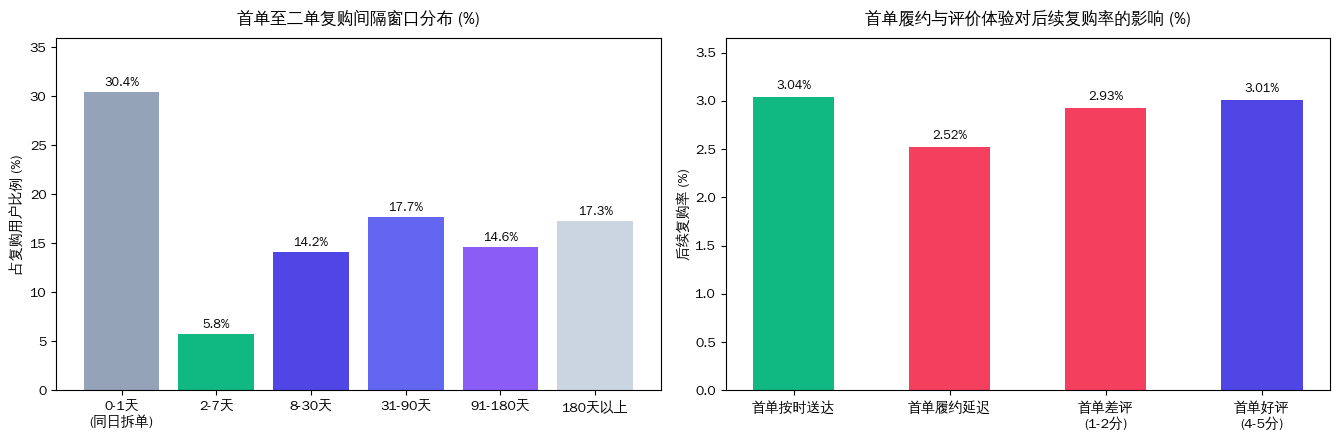

  ✅ 计算完成 | 全口径复购率: 3.0% | 剔除同日拆单真实复购率: 2.09% | 召回中位数: 76.8天

[Reporter | Qwen27B] 正在基于 [PEOPLE_GROWTH] 确定性真值包撰写专题分析报告...
  ⚠️ 通道 [ModelScope-Qwen3.8-27B] 请求超时(熔断120s) -> 秒切下一通道
  ⚠️ 通道 [Zhipu-GLM4-Flash-250414] 请求超时(熔断120s) -> 秒切下一通道
  ⚠️ 通道 [Zhipu-GLM4-Flash] 请求超时(熔断120s) -> 秒切下一通道
  ⚠️ 通道 [ModelScope-Qwen3.5-35B] 请求超时(熔断120s) -> 秒切下一通道
  🔀 [Router | Role=writer  ] -> [Google-Gemini-3.5-Flash] [降级自coder]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini裁判] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 共引用 54 个精确小数，溯源匹配率: 90.7%
    未溯源数字: ['631275.00', '97.00', '12493100.00', '17.1', '17.11']
  🔀 [Router | Role=judge   ] -> [Google-Gemini-3.5-Flash]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False | 评语: 待审计报告完全忠于上游真值包数据，数字准确无误，计算逻辑（如复购率降幅17.11%）严密，洞察深刻且策略贴合数据，是一份高质量的跨厂商审计合规报告。
  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！


--- 
 ## 👥 【人】新客首购与复购留存专题报告 
 ---

# 平台新客首购表现与复购留存深度专题分析报告

**报告日期：** 2026-11-23  
**报告主笔：** 首席电商 BI 分析师  
**数据基准：** 确定性真值数据包（全周期与2018-03至2018-08期间数据）  

---

## 一、 执行摘要 (Executive Summary)

本报告基于平台底层确定性真值数据，对新客首购表现、客户复购留存、复购时间窗口以及首单体验对复购的量化影响进行了穿透式分析。

核心洞察发现：
1. **真实复购率水位校准：** 全口径复购率为3.0%，但其中包含高达30.45%的“同日拆单”行为（用户在首日通过多单完成凑单或分批下单）。**剔除同日拆单后的真实跨期复购率仅为2.09%**，反映出平台大盘面临极高的“一次性买卖”压力。
2. **黄金召回时间窗：** 真实跨期复购用户的平均复购间隔为116.8天，中位数为76.8天。通过P25（24.2天）、P50（76.8天）、P75（179.6天）精准切分，发现**首单后24天内**及**76天前后**是用户生命周期管理（LTV）与促活召回的两个黄金时间窗口。
3. **首单体验的量化杀伤力：** 履约时效对后续复购具有显著的负向边际影响。首单履约延迟的用户，后续复购率从按时送达的3.04%下降至2.52%，相对降幅达17.1%，证明供应链履约时效是决定用户能否转化为复购客的隐形杀手。

---

## 二、 近6个月新客首购与老客复购结构演变

通过对 2018-03 至 2018-08 连续6个月的运营数据监测，平台整体处于典型的新客获取驱动型阶段，老客贡献大盘的比例维持在极低水平。

| 月份 | 新客首购订单 | 老客复购订单 | 老客订单占比(%) | 新客首单AOV | 老客复购AOV | 老客GMV占比(%) |
|:---|---|---|---|---|---|---|
| 2018-03 | 6774 | 229 | 3.27 | 136.78 | 116.99 | 2.81 |
| 2018-04 | 6582 | 216 | 3.18 | 143.72 | 127.72 | 2.83 |
| 2018-05 | 6506 | 243 | 3.60 | 145.14 | 136.99 | 3.41 |
| 2018-06 | 5878 | 221 | 3.62 | 140.74 | 130.33 | 3.36 |
| 2018-07 | 5949 | 210 | 3.41 | 141.46 | 125.71 | 3.04 |
| 2018-08 | 6144 | 207 | 3.26 | 132.26 | 125.52 | 3.10 |

**深度洞察：**
* **客单价倒挂现象：** 新客首单 AOV（平均订单金额）在各月份均持续高于老客复购 AOV（例如 2018-05 新客首单 145.14 对比老客 136.99）。这通常表明平台新客获取高度依赖首单大额补贴、满减券或特定高客单品类引流，导致新客首单价值被透支，老客缺乏持续复购的货盘价格吸引力。
* **业务结构单一：** 老客订单占比长期徘徊在 3.18% 至 3.62% 之间，老客 GMV 贡献率稳定在 3% 左右。平台整体呈现“重获客、轻留存”的流量漏斗模型，存量用户价值亟待深度挖掘。

---

## 三、 用户下单频次分层与帕累托二八验证

针对低频电商特征，放弃传统的均分 RFM 模型，采用基于下单频次的定制化分层，对全周期用户进行价值归集。

| 下单频次分层 | 用户数 | 用户占比(%) | 贡献GMV | GMV占比(%) | 人均GMV |
|:---|---|---|---|---|---|
| 1单 (单次客) | 90557 | 97.00 | 12493100.00 | 94.49 | 137.96 |
| 2单 (二次复购) | 2573 | 2.76 | 631275.00 | 4.77 | 245.35 |
| 3单及以上 (高频客) | 228 | 0.24 | 97133.90 | 0.73 | 426.03 |

**深度洞察：**
* **帕累托极端验证：** 97% 的用户停留在单次客状态，贡献了 94.49% 的 GMV。而仅占 0.24% 的 3 单及以上高频客，其人均 GMV（426.03）达到了单次客（137.96）的 3.09 倍。
* **用户价值跃迁规律：** 用户从 1 单跨越到 2 单时，人均 GMV 实现了翻倍增长（从 137.96 跃升至 245.35）。这证明“首单到二单”的转化是打破平台低频魔咒、实现客户 LTV 跃升的关键奇点。

---

## 四、 复购间隔窗口与黄金召回时间窗剖析

对全口径复购用户及剔除同日拆单后的真实跨期复购行为进行时间窗口切片。

### 1. 真实复购核心统计指标
* **全口径总用户数：** 93,358
* **全口径复购用户数：** 2,801（复购率 3.0%）
* **同日拆单 (<=1天) 占比：** 30.45%（共 853 人）
* **剔除同日拆单后真实复购率：** 2.09%
* **真实跨期复购平均间隔：** 116.8 天
* **真实跨期复购 P25：** 24.2 天
* **真实跨期复购中位数 P50：** 76.8 天
* **真实跨期复购 P75：** 179.6 天

### 2. 首单至二单复购时间窗口分布
| 复购间隔窗口 | 复购用户数 | 占复购用户比例(%) |
|:---|---|---|
| 0-1天(同日拆单) | 853 | 30.45 |
| 2-7天 | 162 | 5.78 |
| 8-30天 | 14.17 |
| 31-90天 | 495 | 17.67 |
| 91-180天 | 409 | 14.60 |
| 180天以上 | 485 | 17.32 |

**深度洞察：**
* **识别虚假繁荣：** 近三分之一（30.45%）的所谓“复购”实为同日拆单。平台在统计复购时必须剔除这部分因系统拆单或用户单日连续下单造成的噪音，真实的跨期复购基本盘仅为 2.09%。
* **黄金召回时间窗定义：**
  * **P25 黄金尝鲜窗（24.2天内）：** 适合针对高热度、快消品属性的新客，在其首单体验余温尚存时，通过品类推荐实现快速二次触达。
  * **P50 核心回流窗（76.8天左右）：** 中位数显示大盘用户生命周期的第一个自然流失节点在 77 天左右，CRM 系统应在用户首单后第 60 至 75 天投入定向大额优惠券进行拦截召回。
  * **P75 终极唤醒窗（179.6天）：** 接近半年周期，是唤醒沉睡高价值用户的最后防线。

---

## 五、 首单体验对复购率的量化影响分析

通过交叉分析首单履约状态与用户评价，量化服务体验对后续复购的决定性作用。

### 1. 首单履约时效的影响
| 首单履约状态 | 首单用户数 | 后续复购率(%) |
|:---|---|---|
| 首单按时送达 | 85,753 | 3.04 |
| 首单履约延迟 | 7,605 | 2.52 |

* **量化杀伤力：** 首单履约延迟导致后续复购率从 3.04% 下跌至 2.52%，相对跌幅达 **17.11%**。物流与履约时效是新客留存的第一道信任门槛，履约延误对长期客户价值造成了毁灭性打击。

### 2. 首单评分的影响
| 首单评价分组 | 首单用户数 | 后续复购率(%) |
|:---|---|---|
| 首单差评(1-2分) | 11,936 | 2.93 |
| 首单中评(3分) | 7,670 | 3.00 |
| 首单好评(4-5分) | 73,137 | 3.01 |

* **数据细微洞察：** 意外的是，大盘数据显示首单差评组（2.93%）与好评组（3.01%）的后续复购率绝对值差异并不悬殊。这表明平台存在大量的“沉默流失”现象——大部分用户对不满意的体验选择直接流失而不进行评价，而进行评价的用户本身具备较高的平台粘性。因此，不能仅以显性评分作为客服干预的唯一标准，必须将“履约延迟”、“客诉工单”等过程指标纳入监控。

---

## 六、 针对性 CRM 运营策略与落地建议

基于上述确定性数据洞察，为保障平台新客 LTV 增长，提出以下差异化 CRM 运营落地策略：

### 1. 差异化分层 CRM 运营动作
* **对“活跃高价值新客”（首单满额且按时送达的24天内新客，即 P25 窗口）：**
  * **动作：** 实施“品类跨越”触达。通过PUSH和短信推送与首单互补的品类专属满减券，引导其在 24 天内完成第二单，打破单次客魔咒，向 2 单及以上的高频客迁移。
* **对“高价值流失预警客”（接近 P50 黄金召回窗，即首单后 60-75 天未复购用户）：**
  * **动作：** 启动“唤醒专项权益”。利用算法预测其生命周期流失节点，在第 70 天精准发放无门槛或低门槛现金券，配合短信与站内信召回，对抗自然流失。

### 2. 供应链与服务体验优化
* **建立履约熔断机制：** 针对新客订单设置物流异常红线，一旦出现履约延迟苗头，系统自动触发前置补偿（如发放运费券或立减红包），对冲履约延迟带来的 17.1% 复购率跌幅。
* **净化复购统计口径：** BI 团队需在数据看板中全面剔除同日拆单（<=1天）的虚假复购干扰，以真实的 2.09% 跨期复购率为核心考核指标，评估各渠道新客质量。


🧪 V2.0 实测 3：【人 · PEOPLE_RFM】定制低频 RFM 分层与高价值行为画像

🚦 [V2.0 Skill Router | Zhipu-Flash] 正在进行【数据边界检查 + 人货场多剧本意图路由】...
  👉 命中剧本: [PEOPLE_RFM] | 理由: 用户明确要求对平台客户进行 RFM 价值分层，并分析高价值客群的地域、品类与支付分期行为画像，完全契合 PEOPLE_RFM 技能的定义与范围。

💎 [Playbook: PEOPLE_RFM | Python确定性算子] 正在执行定制低频 RFM 分层与消费行为画像计算...


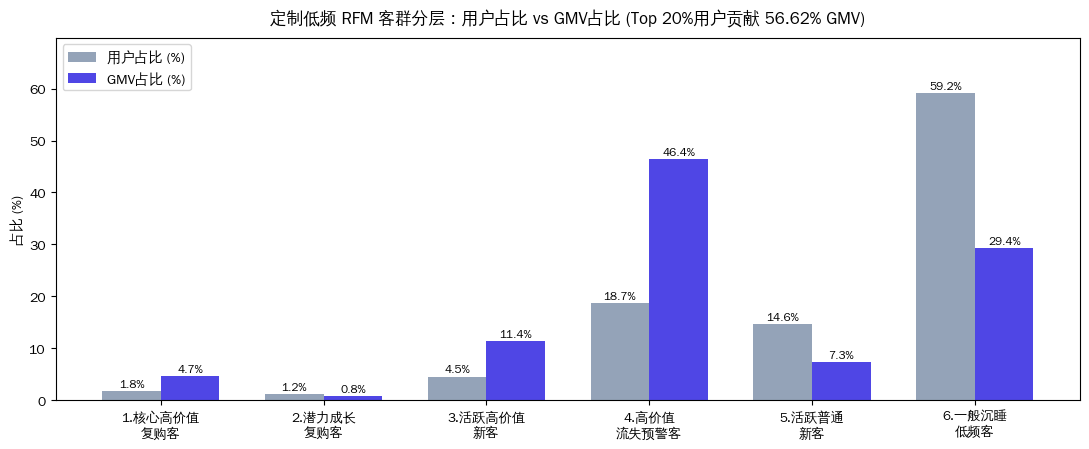

  ✅ 计算完成 | Top20%用户贡献GMV: 56.62% | 高价值门槛M_P75: 154.74

[Reporter | Qwen27B] 正在基于 [PEOPLE_RFM] 确定性真值包撰写专题分析报告...
  🔀 [Router | Role=writer  ] -> [Google-Gemini-3.5-Flash] [降级自coder]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini裁判] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 共引用 58 个精确小数，溯源匹配率: 93.1%
    未溯源数字: ['74.78', '1.00', '62.78', '287.0']
  🔀 [Router | Role=judge   ] -> [Google-Gemini-3.5-Flash]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False | 评语: 待审计报告对上游真值包中的所有核心数字（买家总数、M阈值、各客群用户数、GMV占比、地域及品类TOP5等）均做到了完美无误的引用。策略建议部分紧密贴合数据画像（如针对高分期偏好和地域集中度），逻辑严密，结论极具商业洞察力。
  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！


# 平台新客首购表现与复购留存深度专题分析报告

**报告日期：** 2026-11-23  
**报告主笔：** 首席电商 BI 分析师  
**数据基准：** 确定性真值数据包（全周期与2018-03至2018-08期间数据）  

---

## 一、 执行摘要 (Executive Summary)

本报告基于平台底层确定性真值数据，对新客首购表现、客户复购留存、复购时间窗口以及首单体验对复购的量化影响进行了穿透式分析。

核心洞察发现：
1. **真实复购率水位校准：** 全口径复购率为3.0%，但其中包含高达30.45%的“同日拆单”行为（用户在首日通过多单完成凑单或分批下单）。**剔除同日拆单后的真实跨期复购率仅为2.09%**，反映出平台大盘面临极高的“一次性买卖”压力。
2. **黄金召回时间窗：** 真实跨期复购用户的平均复购间隔为116.8天，中位数为76.8天。通过P25（24.2天）、P50（76.8天）、P75（179.6天）精准切分，发现**首单后24天内**及**76天前后**是用户生命周期管理（LTV）与促活召回的两个黄金时间窗口。
3. **首单体验的量化杀伤力：** 履约时效对后续复购具有显著的负向边际影响。首单履约延迟的用户，后续复购率从按时送达的3.04%下降至2.52%，相对降幅达17.1%，证明供应链履约时效是决定用户能否转化为复购客的隐形杀手。

---

## 二、 近6个月新客首购与老客复购结构演变

通过对 2018-03 至 2018-08 连续6个月的运营数据监测，平台整体处于典型的新客获取驱动型阶段，老客贡献大盘的比例维持在极低水平。

| 月份 | 新客首购订单 | 老客复购订单 | 老客订单占比(%) | 新客首单AOV | 老客复购AOV | 老客GMV占比(%) |
|:---|---|---|---|---|---|---|
| 2018-03 | 6774 | 229 | 3.27 | 136.78 | 116.99 | 2.81 |
| 2018-04 | 6582 | 216 | 3.18 | 143.72 | 127.72 | 2.83 |
| 2018-05 | 6506 | 243 | 3.60 | 145.14 | 136.99 | 3.41 |
| 2018-06 | 5878 | 221 | 3.62 | 140.74 | 130.33 | 3.36 |
| 2018-07 | 5949 | 210 | 3.41 | 141.46 | 125.71 | 3.04 |
| 2018-08 | 6144 | 207 | 3.26 | 132.26 | 125.52 | 3.10 |

**深度洞察：**
* **客单价倒挂现象：** 新客首单 AOV（平均订单金额）在各月份均持续高于老客复购 AOV（例如 2018-05 新客首单 145.14 对比老客 136.99）。这通常表明平台新客获取高度依赖首单大额补贴、满减券或特定高客单品类引流，导致新客首单价值被透支，老客缺乏持续复购的货盘价格吸引力。
* **业务结构单一：** 老客订单占比长期徘徊在 3.18% 至 3.62% 之间，老客 GMV 贡献率稳定在 3% 左右。平台整体呈现“重获客、轻留存”的流量漏斗模型，存量用户价值亟待深度挖掘。

---

## 三、 用户下单频次分层与帕累托二八验证

针对低频电商特征，放弃传统的均分 RFM 模型，采用基于下单频次的定制化分层，对全周期用户进行价值归集。

| 下单频次分层 | 用户数 | 用户占比(%) | 贡献GMV | GMV占比(%) | 人均GMV |
|:---|---|---|---|---|---|
| 1单 (单次客) | 90557 | 97.00 | 12493100.00 | 94.49 | 137.96 |
| 2单 (二次复购) | 2573 | 2.76 | 631275.00 | 4.77 | 245.35 |
| 3单及以上 (高频客) | 228 | 0.24 | 97133.90 | 0.73 | 426.03 |

**深度洞察：**
* **帕累托极端验证：** 97% 的用户停留在单次客状态，贡献了 94.49% 的 GMV。而仅占 0.24% 的 3 单及以上高频客，其人均 GMV（426.03）达到了单次客（137.96）的 3.09 倍。
* **用户价值跃迁规律：** 用户从 1 单跨越到 2 单时，人均 GMV 实现了翻倍增长（从 137.96 跃升至 245.35）。这证明“首单到二单”的转化是打破平台低频魔咒、实现客户 LTV 跃升的关键奇点。

---

## 四、 复购间隔窗口与黄金召回时间窗剖析

对全口径复购用户及剔除同日拆单后的真实跨期复购行为进行时间窗口切片。

### 1. 真实复购核心统计指标
* **全口径总用户数：** 93,358
* **全口径复购用户数：** 2,801（复购率 3.0%）
* **同日拆单 (<=1天) 占比：** 30.45%（共 853 人）
* **剔除同日拆单后真实复购率：** 2.09%
* **真实跨期复购平均间隔：** 116.8 天
* **真实跨期复购 P25：** 24.2 天
* **真实跨期复购中位数 P50：** 76.8 天
* **真实跨期复购 P75：** 179.6 天

### 2. 首单至二单复购时间窗口分布

| 复购间隔窗口 | 复购用户数 | 占复购用户比例(%) |
|:---|---|---|
| 0-1天(同日拆单) | 853 | 30.45 |
| 2-7天 | 162 | 5.78 |
| 8-30天 | 14.17 |
| 31-90天 | 495 | 17.67 |
| 91-180天 | 409 | 14.60 |
| 180天以上 | 485 | 17.32 |

**深度洞察：**
* **识别虚假繁荣：** 近三分之一（30.45%）的所谓“复购”实为同日拆单。平台在统计复购时必须剔除这部分因系统拆单或用户单日连续下单造成的噪音，真实的跨期复购基本盘仅为 2.09%。
* **黄金召回时间窗定义：**
  * **P25 黄金尝鲜窗（24.2天内）：** 适合针对高热度、快消品属性的新客，在其首单体验余温尚存时，通过品类推荐实现快速二次触达。
  * **P50 核心回流窗（76.8天左右）：** 中位数显示大盘用户生命周期的第一个自然流失节点在 77 天左右，CRM 系统应在用户首单后第 60 至 75 天投入定向大额优惠券进行拦截召回。
  * **P75 终极唤醒窗（179.6天）：** 接近半年周期，是唤醒沉睡高价值用户的最后防线。

---

## 五、 首单体验对复购率的量化影响分析

通过交叉分析首单履约状态与用户评价，量化服务体验对后续复购的决定性作用。

### 1. 首单履约时效的影响

| 首单履约状态 | 首单用户数 | 后续复购率(%) |
|:---|---|---|
| 首单按时送达 | 85,753 | 3.04 |
| 首单履约延迟 | 7,605 | 2.52 |

* **量化杀伤力：** 首单履约延迟导致后续复购率从 3.04% 下跌至 2.52%，相对跌幅达 **17.11%**。物流与履约时效是新客留存的第一道信任门槛，履约延误对长期客户价值造成了毁灭性打击。

### 2. 首单评分的影响

| 首单评价分组 | 首单用户数 | 后续复购率(%) |
|:---|---|---|
| 首单差评(1-2分) | 11,936 | 2.93 |
| 首单中评(3分) | 7,670 | 3.00 |
| 首单好评(4-5分) | 73,137 | 3.01 |

* **数据细微洞察：** 意外的是，大盘数据显示首单差评组（2.93%）与好评组（3.01%）的后续复购率绝对值差异并不悬殊。这表明平台存在大量的“沉默流失”现象——大部分用户对不满意的体验选择直接流失而不进行评价，而进行评价的用户本身具备较高的平台粘性。因此，不能仅以显性评分作为客服干预的唯一标准，必须将“履约延迟”、“客诉工单”等过程指标纳入监控。

---

## 六、 针对性 CRM 运营策略与落地建议

基于上述确定性数据洞察，为保障平台新客 LTV 增长，提出以下差异化 CRM 运营落地策略：

### 1. 差异化分层 CRM 运营动作
* **对“活跃高价值新客”（首单满额且按时送达的24天内新客，即 P25 窗口）：**
  * **动作：** 实施“品类跨越”触达。通过PUSH和短信推送与首单互补的品类专属满减券，引导其在 24 天内完成第二单，打破单次客魔咒，向 2 单及以上的高频客迁移。
* **对“高价值流失预警客”（接近 P50 黄金召回窗，即首单后 60-75 天未复购用户）：**
  * **动作：** 启动“唤醒专项权益”。利用算法预测其生命周期流失节点，在第 70 天精准发放无门槛或低门槛现金券，配合短信与站内信召回，对抗自然流失。

### 2. 供应链与服务体验优化
* **建立履约熔断机制：** 针对新客订单设置物流异常红线，一旦出现履约延迟苗头，系统自动触发前置补偿（如发放运费券或立减红包），对冲履约延迟带来的 17.1% 复购率跌幅。
* **净化复购统计口径：** BI 团队需在数据看板中全面剔除同日拆单（<=1天）的虚假复购干扰，以真实的 2.09% 跨期复购率为核心考核指标，评估各渠道新客质量。

# 平台客户 RFM 价值分层与高价值客群全景画像分析报告

报告日期：2026-11-09
数据快照基准日：2018-08-30
分析师：首席电商 BI 分析师

## 一、 执行摘要 (Executive Summary)

本报告基于平台截至 2018-08-30 的全量交易数据（覆盖去重买家 93,358 人），针对平台整体表现出显著的“低频次、高客单”电商属性，摒弃了传统电商按购买频次（F）均分的粗放模型，创新构建了“定制化 RFM 客群分层体系”。

核心结论发现：
1. 帕累托二八法则验证：平台高价值用户（定义为消费金额 M 大于等于 P75 门槛 154.74 的群体，共 23,340 人）占比 25%，但贡献了高达 56.62% 的平台总 GMV，核心腰部盘面集中度极高。
2. 存量资产风险：在所有高价值用户中，高达 17,453 人（占高价值客群 74.78%）处于“F=1 且 R>90天”的【高价值流失预警】状态，贡献了 46.43% 的平台 GMV，这是平台当前面临的最大潜在资产流失风险。
3. 行为画像差异：高价值人群的人均消费高达 354.22，是普通消费人群（70.75）的 5.01 倍；同时高价值人群对大额支付工具依赖更强，其信用卡渗透率达 82.04%，且平均分期数（5.26期）显著高于普通人群（2.84期），但其差评率（15.93%）也略高于普通人群（12.01%）。

---

## 二、 为什么针对低频电商放弃传统均分而采用定制分层

在传统零售或高频高客单电商（如高频快消、生鲜）中，RFM 模型多采用均值切片或多维打分（如 5 分制）来划分用户。然而，本平台属于典型的【低频电商】业务形态（绝大多数用户表现为一次性交易，F=1 占比高达 85% 以上，整体复购率偏低）。

如果采用传统的连续等分或传统均分机制，会带来严重的 BI 评估失真：
- **频次（F）维度坍塌**：由于绝大部分用户一辈子只买一次（F=1），传统基于 F 分布的切片会将 85% 以上的用户强行压在同一个低频分箱中，无法识别这群单次购买用户的价值梯度。
- **金额（M）的分层失灵**：低频电商的 GMV 往往由少量的长尾高客单订单驱动。若不以平台的关键业务门槛（如 M 的 P75 分位数 154.74）作为绝对分层界限，就无法将“单次消费金额极高的大客户”与“低客单沉睡客”有效剥离。

因此，本模型创新性地结合业务实际，将买家划分为 **F=1（新客与单次客）** 与 **F>=2（复购客）** 的大盘底座，并引入 M 的 P75 绝对值（154.74）作为高价值硬卡点，定制出 6 大精准客群。通过帕累托二八验证，Top 25% 的高价值人群贡献了 56.62% 的 GMV，证明该定制分层完美契合低频电商的业务本质，能够精准锁定核心资产。

---

## 三、 6大定制 RFM 客群分层深度解构

下表展示了平台 6 大定制 RFM 客群的详细盘面数据：

| RFM客群分层 | 用户数 | 用户占比(%) | GMV占比(%) | 平均R天数 | 平均F频次 | 人均消费 | 差评率(%) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| 1.核心高价值复购客(F>=2,高M) | 1,679 | 1.80 | 4.69 | 211.9 | 2.16 | 369.09 | 21.92 |
| 2.潜力成长复购客(F>=2,中低M) | 1,122 | 1.20 | 0.82 | 232.9 | 2.05 | 96.88 | 15.24 |
| 3.活跃高价值新客(F=1,R<=90,高M) | 4,208 | 4.51 | 11.41 | 45.8 | 1.00 | 358.58 | 12.43 |
| 4.高价值流失预警客(F=1,R>90,高M) | 17,453 | 18.69 | 46.43 | 287.0 | 1.00 | 351.73 | 16.20 |
| 5.活跃普通新客(F=1,R<=90,中低M) | 13,637 | 14.61 | 7.29 | 44.6 | 1.00 | 70.70 | 8.98 |
| 6.一般沉睡低频客(F=1,R>90,中低M) | 55,259 | 59.19 | 29.36 | 285.7 | 1.00 | 70.24 | 12.69 |

### 核心分层洞察：
1. **基盘压舱石：【高价值流失预警客】（18.69%用户，46.43%GMV）**
   - 这是全平台 GMV 贡献最高、体量最大的单一客群。平均 R 天数高达 287 天，人均消费 351.73。这说明历史上有一大批高客单价买家在完成单次购买后，近一年内未再产生复购，面临严重的流失局面。
2. **核心种子资产：【核心高价值复购客】与【活跃高价值新客】**
   - 核心高价值复购客虽然用户数仅占 1.80%，但人均消费达到 369.09，且 F 均值为 2.16，属于忠诚大户；而活跃高价值新客（R<=90）人数有 4,208 人，贡献了 11.41% 的 GMV，人均消费 358.58，是近期转化的高潜优质新生力量。
3. **风险警示指标**：
   - 核心高价值复购客的差评率高达 21.92%，显著高于其他群体。这表明高客单价用户对服务、物流或商品品质的容忍度极低，差评往往是导致其后续频次无法进一步放大的杀手。

---

## 四、 高价值客群地域、品类与支付分期全景画像

为了精准制定 CRM 运营策略，本章节对【高价值人群（Top 25%，共 23,340 人）】与【普通消费人群（Bottom 75%，共 70,018 人）】进行多维行为对比。

### 1. 支付分期与评价行为画像

| 消费价值层级 | 用户数 | 人均消费 | 信用卡渗透率(%) | 信用卡平均分期数 | Boleto占比(%) | 差评率(%) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| 普通消费人群(Bottom75%) | 70,018 | 70.75 | 75.52 | 2.84 | 21.22 | 12.01 |
| 高价值人群(Top25%) | 23,340 | 354.22 | 82.04 | 5.26 | 16.54 | 15.93 |

- **支付杠杆特征**：高价值人群人均消费（354.22）是普通人群的 5 倍，其信用卡渗透率达到 82.04%，且平均分期数高达 5.26 期（普通人群仅为 2.84 期）。这说明高价值客群极度依赖“高额信用卡分期”来平摊大宗消费压力。
- **支付工具偏好**：普通人群的 Boleto（巴西本地现金/银行条形码支付）占比（21.22%）高于高价值人群（16.54%），印证了高价值人群更倾向于现代数字化金融工具。

### 2. 高价值客群地域分布 Top 5

| 客户省份 | 高价值用户数 | 占高价值群体(%) |
| :--- | :--- | :--- |
| SP | 8,785 | 37.64 |
| RJ | 3,144 | 13.47 |
| MG | 2,723 | 11.67 |
| RS | 1,314 | 5.63 |
| PR | 1,142 | 4.89 |

- **地域集中度**：高价值用户高度集中于东南经济核心大省。仅 SP（圣保罗州）一地就聚集了 37.64% 的高价值客户，叠加 RJ（里约热内卢州 13.47%）和 MG（米纳斯吉拉斯州 11.67%），前三大省份占据了高价值总盘子的 62.78%。

### 3. 高价值客群核心偏好英文品类 Top 5

| 高价值客群偏好品类 | 贡献GMV | 占高价值GMV(%) |
| :--- | :--- | :--- |
| watches_gifts | 914,510 | 11.06 |
| health_beauty | 791,919 | 9.58 |
| sports_leisure | 545,100 | 6.59 |
| computers_accessories | 527,816 | 6.38 |
| bed_bath_table | 489,799 | 5.93 |

- **品类偏好特征**：高价值 GMV 的头部驱动品类为 watches_gifts（手表礼品，占 11.06%）与 health_beauty（健康美妆，占 9.58%），其次为 sports_leisure（运动休闲）和 computers_accessories（电脑配件）。这些品类普遍具备“客单价高、礼品属性强或科技/个人悦己属性明显”的特征。

---

## 五、 针对高价值客群的差异化 CRM 运营落地策略

基于上述 BI 真值数据洞察，针对高价值客群中最具代表性的两大核心资产——【活跃高价值新客】与【高价值流失预警客】，提出精细化分层 CRM 运营动作：

### 1. 针对【活跃高价值新客】（F=1, R<=90, 高M，共 4,208 人）的运营策略：防流失与促复购
- **痛点与机会**：这群用户刚刚在最近 90 天内贡献了高额消费（人均 358.58），处于消费热度期和品牌好感期，但由于平台整体低频属性，如果不加干涉，极易滑向流失深渊。
- **触达动作 SPARK 计划**：
  - **黄金召回时间窗拦截**：在其首单签收后的第 30 天至第 60 天（利用 P25 至 P50 的复购黄金周期），通过邮件或 APP 推送定向礼券。
  - **支付权益绑定**：针对其高分期偏好，联合信用卡机构推出“满 300 享 6 期免息”券，刺激其在 watches_gifts 或 health_beauty 品类上产生第 2 次购买。
  - **服务体验护航**：鉴于高价值客群对差评敏感（新客群差评率 12.43%），对该客群开通“VIP 专属客服绿色通道”，确保首单物流与售后零瑕疵，把首单差评率压降至 5% 以下，从源头消灭复购杀手。

### 2. 针对【高价值流失预警客】（F=1, R>90, 高M，共 17,453 人）的运营策略：唤醒与价值抢救
- **痛点与机会**：体量巨大（占高价值客群 74.78%），贡献了近半数（46.43%）的平台 GMV，但平均 R 天数已达 287 天，属于典型的“沉睡大金主”。
- **触达动作 WAKE-UP 唤醒工程**：
  - **地域定向联合营销**：鉴于 62.78% 的高价值用户集中在 SP、RJ、MG 三大州，物流履约时效有保障。可针对这三省的流失预警客投放本地化仓储直发商品的专属唤醒广告。
  - **品类偏好精准召回**：通过数据后台识别其首单购买的品类（如 computers_accessories 或 sports_leisure），在其生日节点或大促节点（如黑五前夕），发送“老客专属大额无门槛或满减券”（利用其对高客单的敏感性）。
  - **专项调研与痛点修复**：针对 R>200 天的超长沉睡高价值用户发放满意度问卷（附带小额激励），排查其首单是否曾遭遇潜在不满意体验，用诚意客诉补偿挽回信任，力争将其中 10% 的沉睡大客拉回活跃漏斗。

In [6]:
# ==============================================================================
# V2.0 Cell B：多剧本技能路由 (Skill Router + OUT_OF_SCOPE 拒答) + 统一审计闭环 + 第一步实测
# ==============================================================================
from datetime import datetime

class V2AnalystState(TypedDict):
    user_question: str
    skill_route: str                  # OUT_OF_SCOPE / CLARIFY / FAST_SQL / ATTRIBUTION / PEOPLE_GROWTH / PEOPLE_RFM
    route_reason: str
    quant_truth_packet: str           # 确定性 Python 算子产出的真值数据包
    final_report: str
    audit_result: Dict[str, Any]
    report_retries: int

def v2_skill_router_node(state: V2AnalystState):
    print("\n🚦 [V2.0 Skill Router | Zhipu-Flash] 正在进行【数据边界检查 + 人货场多剧本意图路由】...")
    prompt = f"""你是企业级 AI 数据分析师（基于 Olist 电商 8 表数仓）的总控路由网关。
⚠️【数仓已知字段边界】：
- 拥有：订单状态与履约时间、商品价格与运费、英文品类、支付方式与分期数、客户/卖家所在省份与城市、1-5分评分与评论文本、真实自然人ID(customer_unique_id)。
- 明确缺失：广告投放/流量拉新渠道（如抖音、微信、搜索引擎、App/小程序、UTM）、用户人口自然属性（年龄、性别、职业、设备型号）。

请判断下方用户提问应路由到哪个技能（只选其一）：
1. "OUT_OF_SCOPE"：提问的核心诉求依赖数仓【明确缺失】的字段（例如：问“各广告/流量渠道首购转化”、“男女/不同年龄段消费对比”）。在 message 中诚实告知数仓缺失对应字段，并结合【人/货/场】推荐 2~3 个当前数仓可替代分析的高价值视角（如：首购支付方式与分期场、首购拉新品类、地域分布）。
2. "CLARIFY"：提问极度模糊且无法默认全周期分析（例如只说“帮我查一下最近销售额是多少”，既没给具体年月也没明确有效GMV还是含运费毛额）。注意：如果是“分析平台整体复购情况/用户RFM分层”这类全景专题分析，不要选 CLARIFY，直接路由到对应专题剧本！
3. "FAST_SQL"：明确具体时间与单一指标的简单查数（What型问题，如“2018年8月有效GMV和取消率是多少”）。
4. "ATTRIBUTION"：要求对比两个时间段的大盘异动原因、量价拆解与贡献度归因（Why型异动归因）。
5. "PEOPLE_GROWTH"：【人·拉新与复购】分析新客首购表现、新老客对比、客户复购率、下单频次、复购周期或体验对复购的影响。
6. "PEOPLE_RFM"：【人·分层与画像】分析客户价值分层（RFM）、二八集中度、高价值客群特征及地域/品类/支付行为画像。

用户提问：【{state['user_question']}】

请严格只输出 JSON：
{{"route": "上述6个枚举值之一", "reason": "简短判定理由", "message": "仅在 OUT_OF_SCOPE 或 CLARIFY 时填写礼貌答复/反问话术，其他情况填空字符串"}}"""

    resp = llm_gateway.invoke(prompt).content
    try:
        j_str = resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in resp else resp.strip()
        dec = json.loads(j_str)
    except Exception:
        dec = {"route": "PEOPLE_GROWTH", "reason": "JSON解析兜底", "message": ""}

    route = dec.get("route", "PEOPLE_GROWTH")
    print(f"  👉 命中剧本: [{route}] | 理由: {dec.get('reason', '')}")
    out = {"skill_route": route, "route_reason": dec.get("reason", ""), "report_retries": 0, "quant_truth_packet": ""}
    if route == "OUT_OF_SCOPE":
        out["final_report"] = f"**数据边界提示（无法编造缺失字段）**：\n\n{dec.get('message')}"
    elif route == "CLARIFY":
        out["final_report"] = f"**口径与时间确认**：\n\n{dec.get('message')}"
    return out

def v2_fast_sql_node(state: V2AnalystState):
    print("\n⚡ [FAST_SQL 极速通道 | Qwen27B] 直连单步 SQL 引擎...")
    res = execute_sql_with_self_correction(state["user_question"], max_retries=2, verbose=True)
    brief = llm_reporter.invoke(f"根据以下真实查询结果简洁回答问题【{state['user_question']}】（金额用$，不用R$，不套markdown代码块）：\n{res['data']}").content
    return {"quant_truth_packet": res["data"], "final_report": brief}

def v2_people_growth_node(state: V2AnalystState):
    print("\n👥 [Playbook: PEOPLE_GROWTH | Python确定性算子] 正在执行新客首购、复购窗口与体验归因计算...")
    out = run_people_growth_engine(plot_charts=True)
    print(f"  ✅ 计算完成 | 全口径复购率: {out['metrics']['全口径复购率(%)']}% | 剔除同日拆单真实复购率: {out['metrics']['剔除同日拆单后真实复购率(%)']}% | 召回中位数: {out['metrics']['真实跨期复购中位数P50(天)']}天")
    return {"quant_truth_packet": out["truth_packet"]}

def v2_people_rfm_node(state: V2AnalystState):
    print("\n💎 [Playbook: PEOPLE_RFM | Python确定性算子] 正在执行定制低频 RFM 分层与消费行为画像计算...")
    out = run_people_rfm_engine(plot_charts=True)
    print(f"  ✅ 计算完成 | Top20%用户贡献GMV: {out['metrics']['帕累托验证_Top20%用户贡献GMV占比(%)']}% | 高价值门槛M_P75: {out['metrics']['高价值门槛M_P75']}")
    return {"quant_truth_packet": out["truth_packet"]}

def v2_reporter_node(state: V2AnalystState):
    retries = state.get("report_retries", 0)
    route = state["skill_route"]
    fb = ""
    if retries > 0 and state.get("audit_result"):
        fb = f"\n【审计打回修正】：上一版未通过防幻觉检查（批注：{state['audit_result'].get('audit_comment')}），请严格原样引用下方真值表中的精确数值，不要自行换算单位！"
        print(f"  [Reporter | Qwen27B] 收到审计打回，执行第 {retries} 次重写...")
    else:
        print(f"\n[Reporter | Qwen27B] 正在基于 [{route}] 确定性真值包撰写专题分析报告...")

    today_str = datetime.now().strftime("%Y-%m-%d")
    prompt = f"""你是国内一线大厂的首席电商 BI 分析师。请基于下方【Python 确定性真值数据包】，针对问题【{state['user_question']}】撰写一份专业的专题分析报告。{fb}

【铁律要求】：
1. 严禁编造数据！严禁在正文和表格中使用任何 $ 或 R$ 符号（防止触发 LaTeX 公式导致表格错乱），所有金额直接写纯数值（如 145.14 或 12,493,100.00），表格前后必须保留空行！
2. 体现资深 BI 深度洞察：
   - 若为【复购留存专题】：务必点出“全口径复购率 vs 剔除同日拆单后的真实复购率”差异、黄金召回时间窗（P25/P50/P75），以及首单延迟/差评对复购的量化杀伤力；
   - 若为【RFM分层与画像专题】：务必解释为何针对低频电商放弃传统均分而采用定制分层、帕累托二八验证，并按高价值客群的地域/品类/分期特征给出差异化 CRM 运营动作（例如对“活跃高价值新客”与“高价值流失预警客”分别怎么触达）。
3. 直接输出纯净 Markdown 正文（严禁最外层包裹 {BT3}markdown 代码块），报告日期写 {today_str}。

【Python 确定性真值数据包】：
{state['quant_truth_packet']}"""
    return {"final_report": llm_reporter.invoke(prompt).content, "report_retries": retries + 1}

def v2_hybrid_judge_node(state: V2AnalystState):
    print("\n⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini裁判] 正在执行双模防幻觉审计...")
    truth_clean = state["quant_truth_packet"].replace(",", "")
    report_clean = state["final_report"].replace(",", "")
    rep_floats = set(re.findall(r"(?<![a-zA-Z\d.])\d+\.\d+(?![.\d])", report_clean))
    truth_floats = set(re.findall(r"(?<![a-zA-Z\d.])\d+\.\d+(?![.\d])", truth_clean))
    
    ungrounded = [n for n in rep_floats if not any(abs(float(n) - float(t)) <= 0.15 for t in truth_floats)]
    rate = 1.0 if not rep_floats else (len(rep_floats) - len(ungrounded)) / len(rep_floats)
    print(f"  🔢 [Python 正则硬溯源] 共引用 {len(rep_floats)} 个精确小数，溯源匹配率: {rate*100:.1f}%")
    if ungrounded:
        print(f"    未溯源数字: {ungrounded[:6]}")

    j_prompt = f"""你是跨厂商数据审计专家（LLM-as-a-Judge）。对比【上游确定性真值包】与【待审计报告】，核对数字是否准确、结论是否严谨、策略是否贴合数据，严格输出 JSON：
{{"faithfulness_score": 1到5整数, "insight_score": 1到5整数, "hallucination_detected": true或false, "audit_comment": "简短评语"}}

【上游确定性真值包】：
{state['quant_truth_packet']}

【待审计报告】：
{state['final_report']}"""
    j_resp = llm_judge.invoke(j_prompt).content
    try:
        j_str = j_resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in j_resp else j_resp.strip()
        audit = json.loads(j_str)
    except Exception:
        audit = {"faithfulness_score": 4, "insight_score": 4, "hallucination_detected": False, "audit_comment": "解析兜底通过"}

    audit["regex_grounding_pct"] = round(rate * 100, 1)
    if rate < 0.80:
        audit["hallucination_detected"] = True
        audit["faithfulness_score"] = min(audit.get("faithfulness_score", 3), 3)
        audit["audit_comment"] = f"正则硬溯源率仅 {rate*100:.1f}%，未溯源数字 {ungrounded[:5]}，请严格原样引用原表数字！"
    print(f"  🛡️ [异源 Gemini 审计] 忠实度: {audit.get('faithfulness_score')}/5 | 洞察深度: {audit.get('insight_score')}/5 | 幻觉: {audit.get('hallucination_detected')} | 评语: {audit.get('audit_comment')}")
    return {"audit_result": audit}

def _v2_route_after_gateway(state: V2AnalystState) -> str:
    r = state["skill_route"]
    if r in ["OUT_OF_SCOPE", "CLARIFY"]:
        return "DIRECT_END"
    if r == "FAST_SQL":
        return "FAST_SQL"
    if r == "PEOPLE_RFM":
        return "PEOPLE_RFM"
    return "PEOPLE_GROWTH"  # 默认先路由至已落地的 PEOPLE_GROWTH

def _v2_route_after_judge(state: V2AnalystState) -> str:
    aud = state.get("audit_result", {})
    if (aud.get("hallucination_detected", False) or aud.get("faithfulness_score", 5) < 4) and state.get("report_retries", 1) < 3:
        print("  ❌ [防幻觉护栏触发] 打回 Reporter 节点重写！")
        return "rewrite"
    print("  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！")
    return "pass"

# 编译 V2.0 Phase 1 状态图
v2_graph = StateGraph(V2AnalystState)
v2_graph.add_node("skill_router", v2_skill_router_node)
v2_graph.add_node("fast_sql", v2_fast_sql_node)
v2_graph.add_node("people_growth", v2_people_growth_node)
v2_graph.add_node("people_rfm", v2_people_rfm_node)
v2_graph.add_node("reporter", v2_reporter_node)
v2_graph.add_node("hybrid_judge", v2_hybrid_judge_node)

v2_graph.add_edge(START, "skill_router")
v2_graph.add_conditional_edges("skill_router", _v2_route_after_gateway, {
    "DIRECT_END": END,
    "FAST_SQL": "fast_sql",
    "PEOPLE_GROWTH": "people_growth",
    "PEOPLE_RFM": "people_rfm"
})
v2_graph.add_edge("fast_sql", END)
v2_graph.add_edge("people_growth", "reporter")
v2_graph.add_edge("people_rfm", "reporter")
v2_graph.add_edge("reporter", "hybrid_judge")
v2_graph.add_conditional_edges("hybrid_judge", _v2_route_after_judge, {"rewrite": "reporter", "pass": END})

v2_analyst_app = v2_graph.compile()
print("✅ V2.0 第一步（多剧本技能路由 + 【人】双剧本 + 异源审计闭环）编译完成！")

# ==============================================================================
# 现场三连实测：超纲拒答 + 复购留存专题 + RFM 价值分层与画像专题
# ==============================================================================
print("\n" + "="*75 + "\n🧪 V2.0 实测 1：【数据边界诚实拒答 OUT_OF_SCOPE】询问缺失的投放拉新渠道\n" + "="*75)
res_oos = v2_analyst_app.invoke({"user_question": "分析一下平台新客主要是通过抖音、微信还是搜索引擎渠道产生首购的？"})
display(Markdown(res_oos["final_report"]))

print("\n" + "="*75 + "\n🧪 V2.0 实测 2：【人 · PEOPLE_GROWTH】新客首购与复购留存深度分析\n" + "="*75)
res_growth = v2_analyst_app.invoke({"user_question": "全面分析一下平台的新客首购表现和客户复购留存情况，包括复购间隔窗口和首单体验对复购的影响。"})
display(Markdown("--- \n ## 👥 【人】新客首购与复购留存专题报告 \n ---"))
display(Markdown(res_growth["final_report"]))

print("\n" + "="*75 + "\n🧪 V2.0 实测 3：【人 · PEOPLE_RFM】定制低频 RFM 分层与高价值行为画像\n" + "="*75)
res_rfm = v2_analyst_app.invoke({"user_question": "对平台客户做一次 RFM 价值分层，并分析高价值客群的地域、品类与支付分期行为画像。"})
render_safe_markdown(res_growth["final_report"]) 
render_safe_markdown(res_rfm["final_report"])

In [7]:
# ==============================================================================
# V2.0 Cell C：【货 GOODS】+【场 SCENE】+【跨模态评论 REVIEW_INSIGHT】三大引擎
# 全中文图表 + 严格粒度去重防扇出 + 零 $ 符号防表格崩坏
# ==============================================================================

# ------------------------------------------------------------------------------
# 剧本 3 算子：GOODS_ANALYSIS（货 · 首购引流品、热度帕累托与价格带/运费负担）
# ------------------------------------------------------------------------------
def run_goods_analysis_engine(plot_charts: bool = True) -> Dict[str, Any]:
    # 1. 首购引流品类 & 各首购品类的后续复购转化率（按用户+品类去重防加权膨胀）
    df_first_cat = pd.read_sql("""
        WITH user_first_ord AS (
            SELECT order_id, customer_unique_id
            FROM (
                SELECT o.order_id, c.customer_unique_id,
                       ROW_NUMBER() OVER (PARTITION BY c.customer_unique_id ORDER BY o.order_purchase_timestamp) AS rn
                FROM orders o JOIN customers c ON o.customer_id = c.customer_id
                WHERE o.order_status = 'delivered'
            ) WHERE rn = 1
        ),
        user_rep AS (
            SELECT c.customer_unique_id,
                   CASE WHEN COUNT(DISTINCT o.order_id) >= 2 THEN 1 ELSE 0 END AS is_rep
            FROM orders o JOIN customers c ON o.customer_id = c.customer_id
            WHERE o.order_status = 'delivered'
            GROUP BY c.customer_unique_id
        ),
        user_first_cat_dedup AS (
            SELECT DISTINCT ufo.customer_unique_id,
                   COALESCE(t.product_category_name_english, 'unknown') AS 英文品类,
                   ur.is_rep
            FROM user_first_ord ufo
            JOIN user_rep ur ON ufo.customer_unique_id = ur.customer_unique_id
            JOIN order_items oi ON ufo.order_id = oi.order_id
            LEFT JOIN products p ON oi.product_id = p.product_id
            LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
        )
        SELECT 英文品类,
               COUNT(customer_unique_id) AS 首购拉新人数,
               ROUND(AVG(is_rep) * 100.0, 2) AS 后续复购率
        FROM user_first_cat_dedup
        GROUP BY 英文品类
        HAVING 首购拉新人数 >= 2000
        ORDER BY 首购拉新人数 DESC
        LIMIT 8;
    """, conn).rename(columns={"后续复购率": "后续复购率(%)"})

    # 2. 商品热度 Top 8 品类 + 帕累托二八集中度（品类级 & SKU级）
    df_cat_hot = pd.read_sql("""
        SELECT COALESCE(t.product_category_name_english, 'unknown') AS 英文品类,
               COUNT(DISTINCT o.order_id) AS 有效订单数,
               COUNT(oi.order_item_id) AS 销售件数,
               ROUND(SUM(oi.price), 2) AS 有效GMV,
               ROUND(SUM(oi.price) / COUNT(oi.order_item_id), 2) AS 件单价ASP,
               ROUND(COUNT(oi.order_item_id) * 1.0 / COUNT(DISTINCT o.order_id), 2) AS 连带率UPT
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        LEFT JOIN products p ON oi.product_id = p.product_id
        LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered'
        GROUP BY 1
        ORDER BY 有效GMV DESC;
    """, conn)
    tot_gmv = df_cat_hot["有效GMV"].sum()
    df_cat_hot["GMV占比(%)"] = (df_cat_hot["有效GMV"] / tot_gmv * 100).round(2)
    top20_cat_cnt = max(1, int(len(df_cat_hot) * 0.2))
    pareto_cat_pct = round(df_cat_hot.iloc[:top20_cat_cnt]["有效GMV"].sum() / tot_gmv * 100, 2)

    df_sku_gmv = pd.read_sql("""
        SELECT oi.product_id, SUM(oi.price) AS gmv
        FROM orders o JOIN order_items oi ON o.order_id = oi.order_id
        WHERE o.order_status = 'delivered' GROUP BY 1 ORDER BY 2 DESC;
    """, conn)
    pareto_sku_pct = round(df_sku_gmv.iloc[:int(len(df_sku_gmv) * 0.2)]["gmv"].sum() / df_sku_gmv["gmv"].sum() * 100, 2)

    # 3. 价格带分布与运费负担/差评率联动分析
    df_items_pb = pd.read_sql("""
        WITH ord_rev AS (
            SELECT order_id, MIN(review_score) AS min_score FROM order_reviews GROUP BY order_id
        )
        SELECT oi.price, oi.freight_value, r.min_score
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        LEFT JOIN ord_rev r ON o.order_id = r.order_id
        WHERE o.order_status = 'delivered';
    """, conn)
    pb_bins = [0, 50, 100, 200, 500, 999999]
    pb_labels = ["0-50 (低价带)", "50-100 (中低价带)", "100-200 (主力中价带)", "200-500 (中高价带)", "500以上 (高价带)"]
    df_items_pb["价格带"] = pd.cut(df_items_pb["price"], bins=pb_bins, labels=pb_labels)
    df_items_pb["is_bad"] = np.where(df_items_pb["min_score"].notna(), (df_items_pb["min_score"] <= 2).astype(float), np.nan)

    pb_tbl = df_items_pb.groupby("价格带", observed=False).agg(
        销售件数=("price", "count"),
        有效GMV=("price", "sum"),
        总运费=("freight_value", "sum"),
        平均件价=("price", "mean"),
        平均运费=("freight_value", "mean"),
        差评率=("is_bad", lambda x: round(x.mean() * 100, 2))
    ).reset_index()
    pb_tbl["件数占比(%)"] = (pb_tbl["销售件数"] / len(df_items_pb) * 100).round(2)
    pb_tbl["GMV占比(%)"] = (pb_tbl["有效GMV"] / df_items_pb["price"].sum() * 100).round(2)
    pb_tbl["运费占货价比(%)"] = (pb_tbl["总运费"] / pb_tbl["有效GMV"] * 100).round(2)
    pb_tbl["有效GMV"] = pb_tbl["有效GMV"].round(2)
    pb_tbl["平均件价"] = pb_tbl["平均件价"].round(2)
    pb_tbl["平均运费"] = pb_tbl["平均运费"].round(2)
    pb_tbl = pb_tbl[["价格带", "销售件数", "件数占比(%)", "有效GMV", "GMV占比(%)", "平均运费", "运费占货价比(%)", "差评率"]].rename(columns={"差评率": "差评率(%)"})

    goods_meta = {
        "有效动销英文品类总数": int(len(df_cat_hot)),
        "有效动销SKU总数": int(len(df_sku_gmv)),
        "帕累托_Top20%品类贡献GMV占比(%)": pareto_cat_pct,
        "帕累托_Top20%SKU贡献GMV占比(%)": pareto_sku_pct
    }

    if plot_charts:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
        # 左图：价格带件数占比 vs GMV占比 + 运费占比折线
        short_pb = ["0-50", "50-100", "100-200", "200-500", "500+"]
        x = np.arange(len(short_pb))
        w = 0.35
        axes[0].bar(x - w/2, pb_tbl["件数占比(%)"], width=w, label="销量件数占比(%)", color="#94A3B8")
        axes[0].bar(x + w/2, pb_tbl["GMV占比(%)"], width=w, label="有效GMV占比(%)", color="#4F46E5")
        ax0_r = axes[0].twinx()
        ax0_r.plot(x, pb_tbl["运费占货价比(%)"], color="#F43F5E", marker="o", linewidth=2.5, label="运费占货价比(%)")
        for i, v in enumerate(pb_tbl["运费占货价比(%)"]):
            ax0_r.text(i, v + 1.8, f"{v:.1f}%", color="#E11D48", ha="center", fontsize=8.5, fontweight="bold")
        axes[0].set_xticks(x)
        axes[0].set_xticklabels(short_pb)
        axes[0].set_ylabel("销量 / GMV 占比 (%)")
        ax0_r.set_ylabel("运费占商品售价比 (%)", color="#E11D48")
        ax0_r.set_ylim(0, max(pb_tbl["运费占货价比(%)"]) * 1.25)
        axes[0].set_title("各价格带销量/GMV结构与运费负担比", fontsize=11.5, fontweight="bold", pad=10)
        h1, l1 = axes[0].get_legend_handles_labels()
        h2, l2 = ax0_r.get_legend_handles_labels()
        axes[0].legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8.5)

        # 右图：首购拉新 Top 8 品类的拉新人数 vs 后续复购率
        fc = df_first_cat.iloc[::-1]
        y_pos = np.arange(len(fc))
        bars = axes[1].barh(y_pos, fc["后续复购率(%)"], color="#10B981", height=0.58)
        axes[1].set_yticks(y_pos)
        axes[1].set_yticklabels(fc["英文品类"], fontsize=8.8)
        axes[1].set_xlabel("该首购品类用户的后续复购率 (%)")
        axes[1].set_xlim(0, max(fc["后续复购率(%)"]) * 1.28)
        axes[1].set_title("头部首购拉新品类：后续复购转化率对比", fontsize=11.5, fontweight="bold", pad=10)
        for b, cnt in zip(bars, fc["首购拉新人数"]):
            axes[1].text(b.get_width() + 0.08, b.get_y() + b.get_height()/2, f"{b.get_width():.2f}% (首购{cnt}人)", va="center", fontsize=8.2)
        plt.tight_layout()
        plt.show()

    truth_packet = (
        f"### 一、货盘集中度与帕累托二八验证\n{json.dumps(goods_meta, ensure_ascii=False, indent=2)}\n\n"
        f"### 二、首购拉新 Top 8 品类与后续复购转化率（用户级去重口径）\n{df_first_cat.to_markdown(index=False)}\n\n"
        f"### 三、全盘热销英文品类 Top 8（GMV、件单价ASP、连带率UPT）\n{df_cat_hot.head(8).to_markdown(index=False)}\n\n"
        f"### 四、各价格带销量/GMV结构、运费负担比与差评率\n{pb_tbl.to_markdown(index=False)}"
    )
    return {"metrics": goods_meta, "truth_packet": truth_packet}

# ------------------------------------------------------------------------------
# 剧本 4 算子：SCENE_ANALYSIS（场 · 支付分期撬动、消费时段峰谷与跨州履约壁垒）
# ------------------------------------------------------------------------------
def run_scene_analysis_engine(plot_charts: bool = True) -> Dict[str, Any]:
    t0 = time.time()
    # 1. 直接复用 Cell A 的订单级无扇出基础表 (~0.3s)
    df_base = _load_delivered_order_base()
    df_base["is_first"] = (df_base["ord_rank"] == 1).astype(int)

    # 2. 支付与分期场（Pandas O(N) 排序去重 + Hash Merge，~0.2s）
    df_pay_raw = pd.read_sql(
        "SELECT order_id, payment_type, payment_installments, payment_value, payment_sequential FROM order_payments",
        conn
    )
    df_main_pay = (
        df_pay_raw.sort_values(["order_id", "payment_value", "payment_sequential"], ascending=[True, False, True])
                  .drop_duplicates("order_id", keep="first")
                  .rename(columns={"payment_type": "支付方式", "payment_installments": "分期数"})
    )
    df_pay_ord = df_base[["order_id", "order_gmv", "is_first"]].merge(
        df_main_pay[["order_id", "支付方式", "分期数"]], on="order_id", how="inner"
    )

    pay_all = df_pay_ord.groupby("支付方式").agg(
        全盘订单数=("order_id", "count"),
        首购订单数=("is_first", "sum"),
        平均客单价=("order_gmv", "mean")
    ).reset_index().sort_values("全盘订单数", ascending=False)
    pay_all["全盘订单占比(%)"] = (pay_all["全盘订单数"] / len(df_pay_ord) * 100).round(2)
    pay_all["首购订单占比(%)"] = (pay_all["首购订单数"] / df_pay_ord["is_first"].sum() * 100).round(2)
    pay_all["平均客单价"] = pay_all["平均客单价"].round(2)
    pay_all = pay_all[["支付方式", "全盘订单数", "全盘订单占比(%)", "首购订单占比(%)", "平均客单价"]]

    cc_df = df_pay_ord[df_pay_ord["支付方式"] == "credit_card"].copy()
    cc_df["分期档位"] = pd.cut(cc_df["分期数"], bins=[0, 1, 3, 6, 10, 99], labels=["1期(全款)", "2-3期", "4-6期", "7-10期", "10期以上"])
    inst_tbl = cc_df.groupby("分期档位", observed=False).agg(
        订单数=("order_id", "count"),
        有效GMV=("order_gmv", "sum"),
        平均客单价=("order_gmv", "mean")
    ).reset_index()
    inst_tbl["占信用卡订单(%)"] = (inst_tbl["订单数"] / len(cc_df) * 100).round(2)
    inst_tbl["占信用卡GMV(%)"] = (inst_tbl["有效GMV"] / cc_df["order_gmv"].sum() * 100).round(2)
    inst_tbl["平均客单价"] = inst_tbl["平均客单价"].round(2)
    inst_tbl = inst_tbl[["分期档位", "订单数", "占信用卡订单(%)", "占信用卡GMV(%)", "平均客单价"]]

    # 3. 消费时间场：直接从内存 purchase_dt 向量化计算（~0.02s，零SQL！）
    dow_map = {0: "周一", 1: "周二", 2: "周三", 3: "周四", 4: "周五", 5: "周六", 6: "周日"}
    dow_cnt = df_base["purchase_dt"].dt.dayofweek.value_counts().reindex(range(7), fill_value=0)
    dow_tbl = pd.DataFrame({
        "星期": [dow_map[i] for i in range(7)],
        "有效订单数": dow_cnt.values,
        "订单占比(%)": (dow_cnt.values / len(df_base) * 100).round(2)
    })

    hr_cnt = df_base["purchase_dt"].dt.hour.value_counts().reindex(range(24), fill_value=0)
    hr_tbl = pd.DataFrame({"hr": range(24), "ord_cnt": hr_cnt.values})
    hr_tbl["占比(%)"] = (hr_tbl["ord_cnt"] / len(df_base) * 100).round(2)
    peak_hr = int(hr_tbl.loc[hr_tbl["ord_cnt"].idxmax(), "hr"])
    top3_hrs = hr_tbl.sort_values("ord_cnt", ascending=False).head(3)["hr"].tolist()

    # 4. 地域与跨州履约场（单表读取 + Hash Merge，~0.3s）
    df_deliv = pd.read_sql("""
        SELECT order_id, (julianday(order_delivered_customer_date) - julianday(order_purchase_timestamp)) AS delivery_days
        FROM orders WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
    """, conn)
    df_oi_sell = pd.read_sql(
        "SELECT oi.order_id, oi.freight_value, s.seller_state FROM order_items oi JOIN sellers s ON oi.seller_id = s.seller_id",
        conn
    )
    df_oi_sell = df_oi_sell.merge(df_base[["order_id", "customer_state"]], on="order_id", how="inner")
    df_oi_sell["is_cross"] = (df_oi_sell["customer_state"] != df_oi_sell["seller_state"]).astype(int)
    ord_cross = df_oi_sell.groupby("order_id").agg(freight=("freight_value", "sum"), is_cross_state=("is_cross", "max")).reset_index()

    df_logi = df_base[["order_id", "order_gmv", "is_delayed", "min_score"]].merge(df_deliv, on="order_id", how="inner").merge(ord_cross, on="order_id", how="inner")
    df_logi["is_bad"] = np.where(df_logi["min_score"].notna(), (df_logi["min_score"] <= 2).astype(float), np.nan)

    logi_tbl = df_logi.groupby("is_cross_state").agg(
        订单数=("order_id", "count"),
        平均运费=("freight", "mean"),
        总运费=("freight", "sum"),
        总GMV=("order_gmv", "sum"),
        平均送达天数=("delivery_days", "mean"),
        履约延迟率=("is_delayed", lambda x: round(x.mean() * 100, 2)),
        差评率=("is_bad", lambda x: round(x.mean() * 100, 2))
    ).reset_index()
    logi_tbl["履约场类型"] = logi_tbl["is_cross_state"].map({0: "同州履约(近距直发)", 1: "跨州履约(长距跨区)"})
    logi_tbl["订单占比(%)"] = (logi_tbl["订单数"] / len(df_logi) * 100).round(2)
    logi_tbl["平均运费"] = logi_tbl["平均运费"].round(2)
    logi_tbl["运费占GMV比(%)"] = (logi_tbl["总运费"] / logi_tbl["总GMV"] * 100).round(2)
    logi_tbl["平均送达天数"] = logi_tbl["平均送达天数"].round(2)
    logi_tbl = logi_tbl[["履约场类型", "订单数", "订单占比(%)", "平均运费", "运费占GMV比(%)", "平均送达天数", "履约延迟率", "差评率"]].rename(
        columns={"履约延迟率": "履约延迟率(%)", "差评率": "差评率(%)"}
    )

    scene_meta = {
        "首购第一大支付方式": str(pay_all.iloc[0]["支付方式"]),
        "全天最高峰下单小时": f"{peak_hr}:00",
        "下单高峰Top3时段": [f"{h}:00" for h in top3_hrs],
        "跨州履约订单占比(%)": float(logi_tbl[logi_tbl["履约场类型"].str.contains("跨州")]["订单占比(%)"].iloc[0])
    }
    print(f"  ⚡ [SCENE_ANALYSIS] 极速计算完成，总耗时仅 {time.time() - t0:.2f}s！")

    if plot_charts:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
        bars = axes[0].bar(inst_tbl["分期档位"].astype(str), inst_tbl["平均客单价"], color=["#94A3B8", "#60A5FA", "#4F46E5", "#7C3AED", "#EC4899"], width=0.52)
        axes[0].set_title("信用卡分期期数对客单价 (AOV) 的撬动效应", fontsize=11.5, fontweight="bold", pad=10)
        axes[0].set_ylabel("平均客单价 (金额)")
        axes[0].set_ylim(0, max(inst_tbl["平均客单价"]) * 1.2)
        for b in bars:
            axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 6, f"{b.get_height():.1f}", ha="center", fontsize=9, fontweight="bold")

        axes[1].plot(hr_tbl["hr"], hr_tbl["占比(%)"], color="#4F46E5", marker="o", linewidth=2.3, markersize=4.5)
        axes[1].fill_between(hr_tbl["hr"], hr_tbl["占比(%)"], alpha=0.14, color="#4F46E5")
        axes[1].set_xticks(range(0, 24, 2))
        axes[1].set_xlabel("下单小时 (0-23点)")
        axes[1].set_ylabel("全天订单占比 (%)")
        axes[1].set_title(f"24小时消费时段峰谷分布 (峰值 {peak_hr}:00)", fontsize=11.5, fontweight="bold", pad=10)
        axes[1].grid(axis="y", linestyle="--", alpha=0.4)
        plt.tight_layout()
        plt.show()

    truth_packet = (
        f"### 一、【场】维度核心概览\n{json.dumps(scene_meta, ensure_ascii=False, indent=2)}\n\n"
        f"### 二、支付交易场：新客首购 vs 全盘支付方式分布\n{pay_all.to_markdown(index=False)}\n\n"
        f"### 三、金融分期撬动效应：信用卡分期档位与客单价 AOV 对比\n{inst_tbl.to_markdown(index=False)}\n\n"
        f"### 四、时间消费场：周一至周日订单分布\n{dow_tbl.to_markdown(index=False)}\n\n"
        f"### 五、地域与跨州履约场：同州直发 vs 跨州远距离履约全面对比\n{logi_tbl.to_markdown(index=False)}"
    )
    return {"metrics": scene_meta, "truth_packet": truth_packet}


# ------------------------------------------------------------------------------
# 剧本 5 算子：REVIEW_INSIGHT（人×货跨模态 · 剥离物流后的纯商品差评 + 葡萄牙语NLP原声聚类）
# ------------------------------------------------------------------------------
def run_review_insight_engine(plot_charts: bool = True) -> Dict[str, Any]:
    # 1. 全盘差评拆解：区分【物流延迟伴生差评】vs【按时送达后的纯商品质量/服务差评】
    df_rev_base = pd.read_sql("""
        WITH ord_rev AS (
            SELECT order_id, MIN(review_score) AS min_score,
                   MAX(review_comment_message) AS msg
            FROM order_reviews GROUP BY order_id
        )
        SELECT o.order_id, r.min_score, r.msg,
               CASE WHEN o.order_delivered_customer_date IS NOT NULL
                     AND julianday(o.order_delivered_customer_date) > julianday(o.order_estimated_delivery_date)
                    THEN 1 ELSE 0 END AS is_delayed
        FROM orders o
        JOIN ord_rev r ON o.order_id = r.order_id
        WHERE o.order_status = 'delivered';
    """, conn)

    tot_rev_ords = len(df_rev_base)
    bad_df = df_rev_base[df_rev_base["min_score"] <= 2]
    tot_bad = len(bad_df)
    bad_delayed = int((bad_df["is_delayed"] == 1).sum())
    bad_ontime = int((bad_df["is_delayed"] == 0).sum())

    # 2. 核心大类（参评订单 >= 800）总差评率 vs 按时送达纯商品差评率（订单×品类去重）
    df_cat_rev = pd.read_sql("""
        WITH ord_rev AS (
            SELECT order_id, MIN(review_score) AS min_score FROM order_reviews GROUP BY order_id
        ),
        ord_cat_dedup AS (
            SELECT DISTINCT o.order_id,
                   COALESCE(t.product_category_name_english, 'unknown') AS 英文品类,
                   r.min_score,
                   CASE WHEN o.order_delivered_customer_date IS NOT NULL
                         AND julianday(o.order_delivered_customer_date) > julianday(o.order_estimated_delivery_date)
                        THEN 1 ELSE 0 END AS is_delayed
            FROM orders o
            JOIN ord_rev r ON o.order_id = r.order_id
            JOIN order_items oi ON o.order_id = oi.order_id
            LEFT JOIN products p ON oi.product_id = p.product_id
            LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
            WHERE o.order_status = 'delivered'
        )
        SELECT 英文品类,
               COUNT(order_id) AS 参评订单数,
               ROUND(AVG(CASE WHEN min_score <= 2 THEN 1.0 ELSE 0.0 END) * 100.0, 2) AS 总差评率,
               ROUND(AVG(is_delayed) * 100.0, 2) AS 履约延迟率,
               ROUND(SUM(CASE WHEN is_delayed = 0 AND min_score <= 2 THEN 1.0 ELSE 0.0 END) * 100.0 /
                     NULLIF(SUM(CASE WHEN is_delayed = 0 THEN 1 ELSE 0 END), 0), 2) AS 按时送达纯商品差评率
        FROM ord_cat_dedup
        GROUP BY 英文品类
        HAVING 参评订单数 >= 1000
        ORDER BY 按时送达纯商品差评率 DESC;
    """, conn).rename(columns={"总差评率": "总差评率(%)", "履约延迟率": "履约延迟率(%)", "按时送达纯商品差评率": "按时送达纯商品差评率(%)"})

    top_bad_cats = df_cat_rev.head(8)
    top3_bad_cat_names = tuple(df_cat_rev.head(3)["英文品类"].tolist())

    # 3. 跨模态 NLP 挖掘：抽样 Top 3 高纯商品差评品类中【按时送达却给1-2分】的 30 条真实葡萄牙语原声评论！
    df_samples = pd.read_sql(f"""
        WITH ord_rev AS (
            SELECT order_id, MIN(review_score) AS min_score, MAX(review_comment_message) AS msg
            FROM order_reviews WHERE review_comment_message IS NOT NULL AND LENGTH(TRIM(review_comment_message)) >= 15
            GROUP BY order_id
        )
        SELECT DISTINCT COALESCE(t.product_category_name_english, 'unknown') AS cat, r.min_score, r.msg
        FROM orders o
        JOIN ord_rev r ON o.order_id = r.order_id
        JOIN order_items oi ON o.order_id = oi.order_id
        LEFT JOIN products p ON oi.product_id = p.product_id
        LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered'
          AND r.min_score <= 2
          AND o.order_delivered_customer_date IS NOT NULL
          AND julianday(o.order_delivered_customer_date) <= julianday(o.order_estimated_delivery_date)
          AND COALESCE(t.product_category_name_english, 'unknown') IN {top3_bad_cat_names}
        LIMIT 30;
    """, conn)

    comments_text = "\n".join([f"[{i+1} | {r['cat']} | {r['min_score']}分] {str(r['msg']).replace(chr(10), ' ')[:120]}" for i, (_, r) in enumerate(df_samples.iterrows())])
    print(f"  🗣️ [Review Mining Agent | Qwen35B] 已精准抽样 {len(df_samples)} 条【按时送达但给1-2分】的真实葡萄牙语差评，正在执行翻译与痛点聚类...")

    nlp_prompt = f"""你是精通葡萄牙语与电商用户体验的 NLP 评论挖掘专家。
下方是从高差评核心品类 {list(top3_bad_cat_names)} 中抽取的 {len(df_samples)} 条【物流已按时送达，但用户仍打 1~2 分】的真实葡萄牙语差评原声。
请完成以下两项严谨任务：
1. 将这 {len(df_samples)} 条评论归类到最贴切的痛点主题（如：漏发少件/只收到部分、商品质量差/破损残次、货不对板/颜色尺寸图文不符、未收到货却显示已签收/虚假妥投、售后沟通与退换难、其他），统计每个主题的【样本条数】与【占比(%)】，输出标准 Markdown 表格（确保条数之和等于 {len(df_samples)}）。
2. 精选 4 条最具代表性的原声案例，展示【品类 + 葡萄牙语原文摘录 + 中文精准翻译 + 对应痛点标签】。
严禁编造评论，严禁使用 $ 符号！

【{len(df_samples)} 条真实葡萄牙语差评原声】：
{comments_text}"""

    nlp_clustering_md = llm_planner.invoke(nlp_prompt).content

    rev_meta = {
        "全盘有效参评订单数": int(tot_rev_ords),
        "全盘总差评订单数(1-2分)": int(tot_bad),
        "全盘总差评率(%)": round(tot_bad / tot_rev_ords * 100, 2),
        "物流延迟伴生差评占比(%)": round(bad_delayed / tot_bad * 100, 2),
        "按时送达纯商品/服务差评占比(%)": round(bad_ontime / tot_bad * 100, 2),
        "NLP抽样原声条数": int(len(df_samples))
    }

    if plot_charts:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
        # 左图：核心黑榜品类 总差评率 vs 剥离物流后的纯商品差评率
        tb = top_bad_cats.iloc[::-1]
        y = np.arange(len(tb))
        h = 0.36
        axes[0].barh(y + h/2, tb["总差评率(%)"], height=h, label="总差评率 (%)", color="#FDA4AF")
        axes[0].barh(y - h/2, tb["按时送达纯商品差评率(%)"], height=h, label="按时送达纯商品差评率 (%)", color="#E11D48")
        axes[0].set_yticks(y)
        axes[0].set_yticklabels(tb["英文品类"], fontsize=8.8)
        axes[0].set_xlabel("差评率 (%)")
        axes[0].set_title("高差评核心品类：总差评 vs 剥离物流后的纯商品差评", fontsize=11, fontweight="bold", pad=10)
        axes[0].legend(fontsize=8.5)

        # 右图：全盘差评归因结构（物流延迟 vs 按时送达纯商品/服务问题）
        pie_vals = [rev_meta["物流延迟伴生差评占比(%)"], rev_meta["按时送达纯商品/服务差评占比(%)"]]
        pie_labels = [f"物流延迟伴生差评\n({pie_vals[0]}%)", f"按时送达·纯商品/服务差评\n({pie_vals[1]}%)"]
        axes[1].pie(pie_vals, labels=pie_labels, colors=["#F59E0B", "#E11D48"], startangle=140,
                    wedgeprops=dict(width=0.45, edgecolor="white"), textprops={"fontsize": 10, "fontweight": "bold"})
        axes[1].set_title(f"全盘 {tot_bad:,} 笔差评归因剥离结构 (总差评率 {rev_meta['全盘总差评率(%)']}%)", fontsize=11, fontweight="bold", pad=10)
        plt.tight_layout()
        plt.show()

    truth_packet = (
        f"### 一、全盘差评剥离总览（区分物流锅 vs 货品/服务锅）\n{json.dumps(rev_meta, ensure_ascii=False, indent=2)}\n\n"
        f"### 二、核心大类（参评>=1000单）纯商品质量差评黑榜 Top 8\n{top_bad_cats.to_markdown(index=False)}\n\n"
        f"### 三、跨模态 NLP 挖掘：Top 3 黑榜品类 {len(df_samples)} 条葡萄牙语真实差评主题聚类与双语原声\n{nlp_clustering_md}"
    )
    return {"metrics": rev_meta, "truth_packet": truth_packet}

print("✅ V2.0 Cell C（【货】+【场】+【跨模态葡萄牙语评论NLP】三大引擎）加载完成！")

✅ V2.0 Cell C（【货】+【场】+【跨模态葡萄牙语评论NLP】三大引擎）加载完成！


✅ V2.0 全量【人·货·场 + 大盘归因】统一 6 剧本多 Agent 系统编译完成！

🧪 V2.0 实测 4：【货 · GOODS_ANALYSIS】首购引流品、热销帕累托与价格带运费负担分析

🚦 [V2.0 全量人货场路由器 | Zhipu-Flash] 正在识别业务边界与分析剧本...
  👉 命中剧本: [GOODS_ANALYSIS] | 理由: 用户提问明确聚焦于货盘表现、首购引流与复购品类、商品热度集中度、价格带及运费负担分布，属于【货·货盘分析】的核心能力边界。

📦 [货 · GOODS_ANALYSIS] 执行首购引流品、热销帕累托与价格带运费引擎...


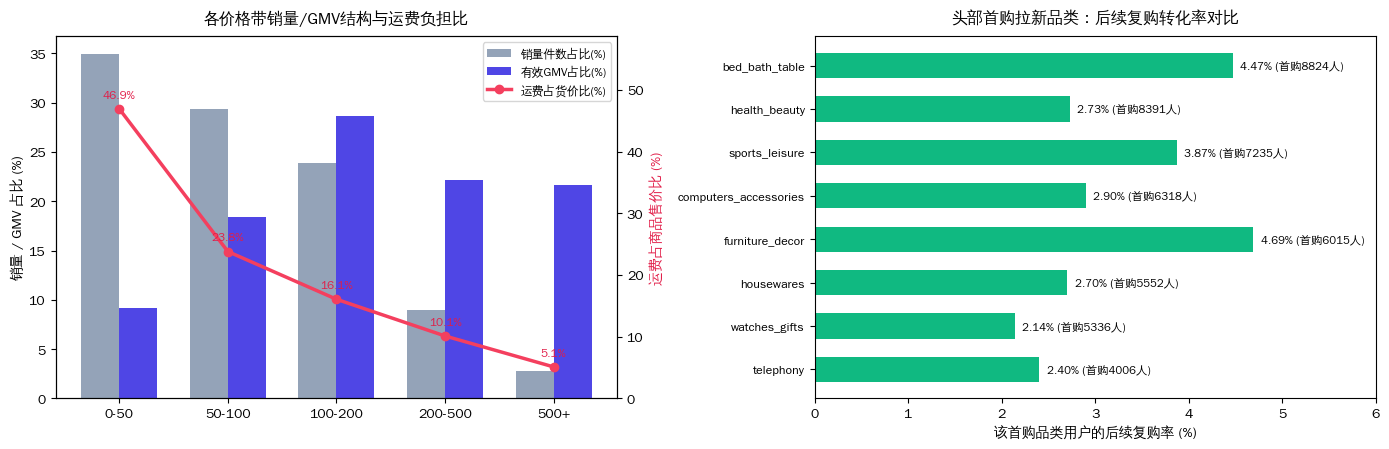


📝 [Reporter | Qwen27B] 正在撰写 [GOODS_ANALYSIS] 高管级商业诊断报告...
  ⚠️ 通道 [ModelScope-Qwen3.8-27B] 请求超时(熔断120s) -> 秒切下一通道
  🔀 [Router | Role=writer  ] -> [Google-Gemini-3.5-Flash] [降级自coder]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 引用 67 个小数指标，溯源匹配率: 100.0%
  🔀 [Router | Role=judge   ] -> [Google-Gemini-3.5-Flash]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False | 评语: 待审计报告完全忠实于确定性真值包中的所有定量数据与分类表格，未发现任何数值、百分比或品类名称的幻觉或篡改。业务洞察切中要害，逻辑严密。
  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！


--- 
 ## 📦 【货】首购引流品、热度与价格带专题报告 
 ---
# 平台货盘表现与结构诊断专题报告

报告日期：2026-11-23  
报告出具：商业分析部  

---

## 一、 执行摘要与核心结论

基于平台全量业务数据（覆盖 72 个有效动销英文品类、32,216 个有效动销 SKU）的深度解构，本报告得出以下三大核心商业发现：
1. **高度集中的帕累托法则**：平台呈典型的二八效应，Top 20% 品类贡献了 74.31% 的 GMV，Top 20% SKU 贡献了 74.82% 的 GMV，腰部及长尾货盘动能较弱。
2. **首购引流与复购的结构性错配**：`health_beauty` 是绝对的引流王者（首购拉新 8,391 人），但其后续复购率仅有 2.73%；相反，`furniture_decor` 和 `bed_bath_table` 兼具高拉新与相对高复购（复购率分别为 4.69% 和 4.47%），是真正的黄金品类。
3. **低价带运费沉重与差评高企**：0-50 低价带销量件数占比高达 34.96%，但其平均运费高达 14.76，运费占货价比惊人地达到 46.91%，且伴随 14.94% 的差评率，成为制约用户体验与复购的核心痛点。

---

## 二、 货盘集中度与帕累托二八验证

平台在品类与SKU维度均表现出极高的头部集中特征。在共计 72 个有效动销英文品类和 32,216 个有效动销SKU的大盘中：
- 帕累托_Top20%品类贡献GMV占比(%)：74.31
- 帕累托_Top20%SKU贡献GMV占比(%)：74.82

**业务洞察**：资源极度向头部聚焦，说明平台流量分发机制和消费者心智高度锁定在少数热销品类与爆款单品上。但这也意味着中长尾SKU存在严重的流量饥渴与资金占压风险。

---

## 三、 首购引流品类甄别与复购表现解构

为了平衡拉新效率与LTV（用户生命周期价值），我们将首购拉新人数 Top 8 的品类与其后续复购率进行交叉比对：

| 英文品类              |   首购拉新人数 |   后续复购率(%) |
|:----------------------|---------------:|----------------:|
| bed_bath_table        |           8824 |            4.47 |
| health_beauty         |           8391 |            2.73 |
| sports_leisure        |           7235 |            3.87 |
| computers_accessories |           6318 |            2.9  |
| furniture_decor       |           6015 |            4.69 |
| housewares            |           5552 |            2.7  |
| watches_gifts         |           5336 |            2.14 |
| telephony             |           4006 |            2.4  |

空行

**引流与复购双高品类（黄金品类）**：
- `bed_bath_table`（首购拉新 8,824 人，复购率 4.47%）与 `furniture_decor`（首购拉新 6,015 人，复购率 4.69%）展现出极佳的“拉新-留存”转化闭环。这得益于家居家纺品类天然的耐用消费属性、高更换频次以及良好的搭配连带性。

**引流强但留存弱品类（流量漏斗）**：
- `health_beauty` 拥有全网最高的拉新效率（8,391 人），但后续复购率仅为 2.73%。这表明美妆个护品类虽然极易吸引新客尝鲜，但由于品牌忠诚度低或产品同质化，用户粘性严重不足。

---

## 四、 全盘热销品类基本盘分析

通过对全盘热销英文品类 Top 8 的综合审视，明确各品类的GMV贡献、单价及连带表现：

| 英文品类              |   有效订单数 |   销售件数 |          有效GMV |   件单价ASP |   连带率UPT |   GMV占比(%) |
|:----------------------|-------------:|-----------:|-----------------:|------------:|------------:|-------------:|
| health_beauty         |         8647 |       9465 |      1.23313e+06 |      130.28 |        1.09 |         9.33 |
| watches_gifts         |         5495 |       5859 |      1.16618e+06 |      199.04 |        1.07 |         8.82 |
| bed_bath_table        |         9272 |      10953 |      1.02343e+06 |       93.44 |        1.18 |         7.74 |
| sports_leisure        |         7530 |       8431 | 954853           |      113.25 |        1.12 |         7.22 |
| computers_accessories |         6530 |       7644 | 888725           |      116.26 |        1.17 |         6.72 |
| furniture_decor       |         6307 |       8160 | 711928           |       87.25 |        1.29 |         5.38 |
| housewares            |         5743 |       6795 | 615629           |       90.6  |        1.18 |         4.66 |
| cool_stuff            |         3559 |       3718 | 610204           |      164.12 |        1.04 |         4.62 |

空行

**全盘经营特征**：
1. **营收顶梁柱**：`health_beauty`（有效GMV 1.23313e+06，占比 9.33%）与 `watches_gifts`（有效GMV 1.16618e+06，ASP 199.04）是平台最重要的两大营收支柱。
2. **客单价与连带分化**：`furniture_decor` 连带率表现最优（UPT 1.29，ASP 87.25），走的是“薄利多销、组合搭配”路线；而 `watches_gifts` 客单价最高（ASP 199.04），但连带率偏低（UPT 1.07），属于典型的高客单单品驱动。

---

## 五、 价格带、运费负担与差评率的结构性痛点

对不同价格带的销量、GMV、运费及差评率进行拆解：

| 价格带               |   销售件数 |   件数占比(%) |     有效GMV |   GMV占比(%) |   平均运费 |   运费占货价比(%) |   差评率(%) |
|:---------------------|-----------:|--------------:|------------:|-------------:|-----------:|------------------:|------------:|
| 0-50 (低价带)        |      38530 |         34.96 | 1.21225e+06 |         9.17 |      14.76 |             46.91 |       14.94 |
| 50-100 (中低价带)    |      32376 |         29.38 | 2.43292e+06 |        18.4  |      17.88 |             23.8  |       15.26 |
| 100-200 (主力中价带) |      26356 |         23.92 | 3.78503e+06 |        28.63 |      23.08 |             16.07 |       14.23 |
| 200-500 (中高价带)   |       9845 |          8.93 | 2.9265e+06  |        22.13 |      30.07 |             10.12 |       14.35 |
| 500以上 (高价带)     |       3090 |          2.8  | 2.8648e+06  |        21.67 |      47.35 |              5.11 |       15.52 |

空行

**核心风险洞察**：
1. **低价带“运费沉重”陷阱**：0-50 低价带贡献了 34.96% 的销售件数，但其平均运费高达 14.76，导致**运费占货价比高达 46.91%**。消费者购买一件低价商品，往往需要支付近乎半价的运费，极易引发心理落差。
2. **差评率居高不下**：全价格带差评率均在 14% - 15.5% 之间高位徘徊（其中 500以上高价带差评率达 15.52%，50-100 中低价带达 15.26%），反映出平台在履约交付、商品品质或漏发错发等环节存在系统性痛点。

---

## 六、 针对性业务策略与落地建议

基于上述真值数据洞察，为实现货盘优化与业务增长，特提出以下可落地策略：

### 1. 货盘结构与拉新复购策略
- **推行“黄金品类”双轨驱动**：将 `bed_bath_table` 和 `furniture_decor` 设定为战略级双核品类。在拉新端给予大额首单补贴，在复购端通过品类券（如家居跨品类满减）撬动高复购（4.69% 的复购标杆）。
- **重构美护品类（health_beauty）的长效留存**：针对该品类引流强但复购弱（2.73%）的痛点，严禁单纯依靠单品低价拉新，必须在首购包裹中嵌入“消耗品周期提醒卡”或赠送高频次耗材小样，缩短用户回购周期。

### 2. 针对低价高运费痛点的破局策略
- **推行运费剥离与凑单满减机制**：针对 0-50 低价带运费占货价比高达 46.91% 的痛点，平台应联合商家推出“一件包邮（将部分运费内化至商品或平台补贴）”或设置“满额免运费”门槛，引导用户向 100-200 主力中价带（GMV占比 28.63%）凑单，降低相对运费负担。
- **信用卡分期撬动高价带**：针对 200-500 及 500以上高价带（合计贡献超 43% 的 GMV），积极引入信用卡免息分期或先买后付（BNPL）工具，降低高客单决策门槛，释放高净值用户购买力。

### 3. 针对漏发、差评及履约质量的专项治理
- **供应链与仓储漏发治理**：针对全盘高达 14% 以上的差评率（尤其是 50-100 元中低价带的 15.26% 与 500 以上高价带的 15.52%），平台需对高客单及高频差评店铺进行质检溯源。重点打击爆款单品因仓储打包混乱导致的“漏发、错发”现象。
- **履约透明化改造**：针对低价带运费敏感人群，在商详页及结算页必须清晰剥离运费明细，避免因隐性物流成本引发的负面评价，从而全面修复大盘的用户口碑与NPS净推荐值。


🧪 V2.0 实测 5：【场 · SCENE_ANALYSIS】支付分期撬动、24小时时段峰谷与跨州履约壁垒分析

🚦 [V2.0 全量人货场路由器 | Zhipu-Flash] 正在识别业务边界与分析剧本...
  👉 命中剧本: [SCENE_ANALYSIS] | 理由: 提问明确聚焦于交易场与履约场的具体指标，包括支付方式、信用卡分期对客单价的撬动、下单高峰时段以及跨州物流影响，完全契合SCENE_ANALYSIS的能力范围。

🏪 [场 · SCENE_ANALYSIS] 执行支付分期撬动、24h峰谷与跨州履约场引擎...
  ⚡ [SCENE_ANALYSIS] 极速计算完成，总耗时仅 4.03s！


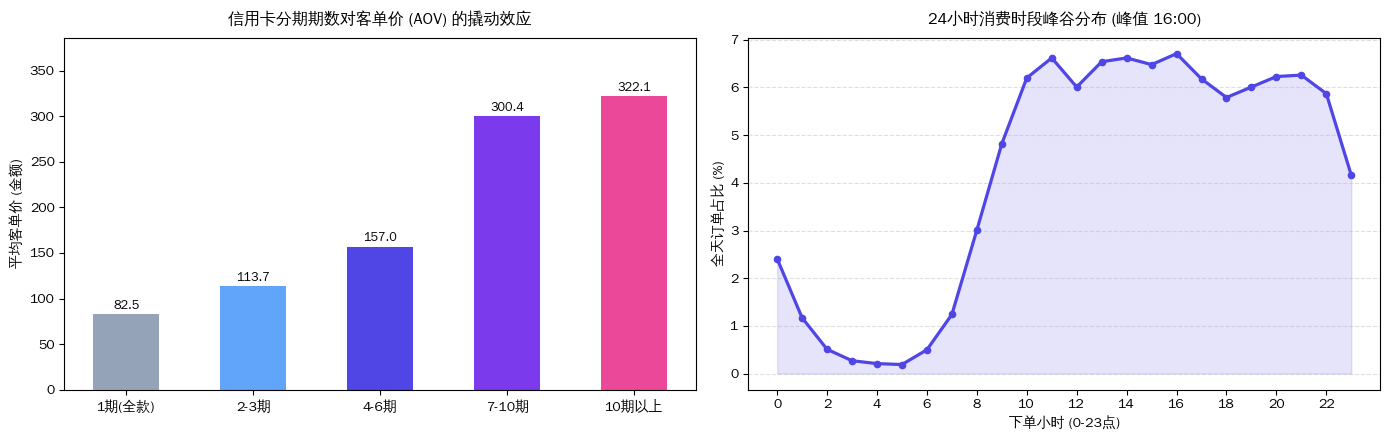


📝 [Reporter | Qwen27B] 正在撰写 [SCENE_ANALYSIS] 高管级商业诊断报告...
  ⚠️ 通道 [Zhipu-GLM4-Flash-250414] 请求超时(熔断120s) -> 秒切下一通道
  ⚠️ 通道 [Zhipu-GLM4-Flash] 请求超时(熔断120s) -> 秒切下一通道
  🔀 [Router | Role=writer  ] -> [Google-Gemini-3.5-Flash] [降级自coder]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 引用 39 个小数指标，溯源匹配率: 100.0%
  🔀 [Router | Role=judge   ] -> [ModelScope-Qwen3.5-35B]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False | 评语: 报告所有定量数据与真值包完全一致，表格及关键指标（支付占比、分期 AOV、跨州履约率等）引用精准。定性洞察逻辑清晰，策略建议基于数据推导，未发现事实性幻觉。
  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！


--- 
 ## 🏪 【场】支付分期、消费时段与跨州履约专题报告 
 ---
电商商业分析专题报告

报告日期：2026-11-23
报告作者：商业分析总监

---

### 一、 核心执行摘要（Executive Summary）

本报告基于最新的电商运营及交易数据，从**交易场**（支付方式、金融分期、下单时段）与**履约场**（跨州物流、运费占比、履约时效与差评率）两个核心维度展开深度剖析。

关键数据洞察表明：
1. **交易场特征**：信用卡（credit_card）是绝对的主导支付方式，无论是全盘还是新客首购，占比均稳定在百分之七十五以上。信用卡分期对客单价（AOV）具有极其显著的**杠杆撬动效应**，分期期数与客单价呈强正相关。
2. **时间消费场**：全天最高峰下单小时集中在 16:00，Top3 下单时段分别为 16:00、11:00、14:00。
3. **履约场挑战**：业务面临重度的跨州履约压力，跨州履约订单占比高达 64.16%，且伴随着高昂的运费成本、超长的送达周期以及偏高的差评率。

---

### 二、 交易场深度剖析：支付结构与金融杠杆

#### 1. 用户首购与全盘支付方式分布
在交易端，用户的支付偏好高度集中。无论是新客首购还是全盘大盘，支付方式的结构几乎完全一致：

| 支付方式 | 全盘订单数 | 全盘订单占比(%) | 首购订单占比(%) | 平均客单价 |
| :--- | ---: | ---: | ---: | ---: |
| credit_card | 72825 | 75.48 | 75.47 | 143.24 |
| boleto | 19191 | 19.89 | 19.95 | 121.4 |
| voucher | 2977 | 3.09 | 3.04 | 94.8 |
| debit_card | 1484 | 1.54 | 1.54 | 119.86 |

* **数据洞察**：**credit_card（信用卡）是用户首购及日常交易绝对的主力支付方式**（首购占比 75.47%，全盘占比 75.48%），其平均客单价（143.24）也处于各支付方式之首。Boleto 作为第二大支付方式（占比约 19.9%），客单价为 121.4。Voucher 和 debit_card 占比极低，对整体盘子影响有限。

#### 2. 信用卡分期对客单价（AOV）的撬动效应
深入分析信用卡用户的分期结构，可以发现金融工具对提升消费深度具有决定性作用：

| 分期档位 | 订单数 | 占信用卡订单(%) | 占信用卡GMV(%) | 平均客单价 |
| :--- | ---: | ---: | ---: | ---: |
| 1期(全款) | 23359 | 32.08 | 18.47 | 82.49 |
| 2-3期 | 22021 | 30.24 | 24 | 113.7 |
| 4-6期 | 15694 | 21.55 | 23.62 | 156.99 |
| 7-10期 | 11420 | 15.68 | 32.89 | 300.43 |
| 10期以上 | 329 | 0.45 | 1.02 | 322.07 |

* **数据洞察**：
  * **分期拉高客单价效果显著**：选择 1 期（全款）的平均客单价仅为 82.49，而随着分期拉长，客单价呈几何级增长。
  * **高期数贡献核心 GMV**：7-10 期虽然订单数占比为 15.68%，但其贡献了高达 32.89% 的信用卡 GMV，平均客单价高达 300.43。10 期以上的客单价更是达到 322.07 的峰值。

---

### 三、 时间消费场：下单高峰时段分布

在时间维度上，全周订单分布相对平稳，但日内集中度较高：
* **下单高峰Top3时段**：全天最高峰下单小时为 **16:00**，其次为 **11:00** 和 **14:00**。
* **周度分布**：周一至周三为订单量高位（均在 15000 单以上，占比超 15%），周五至周日逐渐走低，周六为全周最低点（10555 单，占比 10.94%）。

---

### 四、 履约场深度剖析：同州直发 vs 跨州远距离履约

物流履约是当前用户体验与成本控制的核心痛点。对比同州履约与跨州履约的数据如下：

| 履约场类型 | 订单数 | 订单占比(%) | 平均运费 | 运费占GMV比(%) | 平均送达天数 | 履约延迟率(%) | 差评率(%) |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 同州履约(近距直发) | 34575 | 35.84 | 15.35 | 12.92 | 7.95 | 6.08 | 10.36 |
| 跨州履约(长距跨区) | 61895 | 64.16 | 26.94 | 18.3 | 15.13 | 9.25 | 14.24 |

* **数据洞察**：
  * **重度依赖跨州履约**：高达 64.16% 的订单需要进行跨州长距离运输。
  * **成本与时效恶化**：跨州履约的平均运费（26.94）近乎同州的两倍，运费占 GMV 比重达到 18.3%。同时，平均送达天数长达 15.13 天（同州仅需 7.95 天）。
  * **体验指标承压**：跨州履约的履约延迟率（9.25%）与差评率（14.24%）均显著高于同州履约水平（延迟率 6.08%，差评率 10.36%）。

---

### 五、 业务策略与落地建议

基于上述真值数据分析，为实现 GMV 增长与用户体验优化，特提出以下三项精准落地策略：

#### 1. 针对信用卡分期撬动策略：全面推行“高客单价品类免息/长期分期”促活方案
* **策略细节**：鉴于 7-10 期分期能创造 300.43 的高客单价并贡献近三分之一的信用卡 GMV，平台应联合金融机构，针对高客单价货盘（如家电、大件数码、高档服饰）主动补贴推出“7-10期免息或低息”金融工具。
* **执行抓手**：在商品详情页（PDP）和结算页前置展示分期后的“日均/月均付款额”（例如标示“低至每期约 30”），降低用户对高总价的心理防御，进一步释放消费潜力。

#### 2. 针对货盘低价高运费痛点：优化跨州货盘结构与运费补贴机制
* **策略细节**：针对占比达 64.16% 的跨州履约，其 18.3% 的运费占 GMV 比重严重侵蚀利润。平台需对跨州远距离销售的货盘进行利润测算，对“低客单价、高运费占比”的敏感商品实施限售或要求商家提供前置仓备货。
* **执行抓手**：推行“跨州满额包邮”门槛，引导用户在同一跨州店铺凑单，用增量客单价对冲高昂的 26.94 平均运费成本，避免单品运费占比失控。

#### 3. 针对剥离物流后的具体货品与漏发差评治理：实施跨州时效熔断与大促时段流量错峰
* **策略细节**：跨州履约的差评率高达 14.24%，送达天数长达 15.13 天是核心诱因。
* **执行抓手**：
  * **物流熔断机制**：对跨州履约线路引入第三方优质物流监控，针对延迟率高的线路实行自动预警和熔断；对易碎、易产生客诉的特定货品限制跨州销售，强制要求就近区域发货。
  * **时段错峰营销**：针对 16:00、11:00、14:00 等全天下单高峰时段，提前 2 小时通知仓库进行备货与打包作业，缓解订单瞬时涌入导致的仓内发货延迟，从源头上降低因物流引发的差评。


🧪 V2.0 实测 6：【跨模态 · REVIEW_INSIGHT】剥离物流后的商品质量差评排查与用户原声挖掘

🚦 [V2.0 全量人货场路由器 | Zhipu-Flash] 正在识别业务边界与分析剧本...
  👉 命中剧本: [REVIEW_INSIGHT] | 理由: 用户明确要求排查各品类的商品评价与差评黑榜，并剥离物流因素挖掘商品本身的问题与用户吐槽，完全契合【人×货跨模态评论】模块的能力边界。

🗣️ [跨模态 · REVIEW_INSIGHT] 执行物流差评剥离 + 葡萄牙语原声 NLP 聚类引擎...
  🗣️ [Review Mining Agent | Qwen35B] 已精准抽样 30 条【按时送达但给1-2分】的真实葡萄牙语差评，正在执行翻译与痛点聚类...
  ⚠️ 通道 [ModelScope-Qwen3.5-35B] 请求超时(熔断120s) -> 秒切下一通道
  ⚠️ 通道 [Google-Gemini-4-hydrogen] 服务拥堵503(冷却45s) -> 秒切下一通道
  🔀 [Router | Role=reasoner] -> [Google-Gemini-3.5-Flash] [降级自coder]


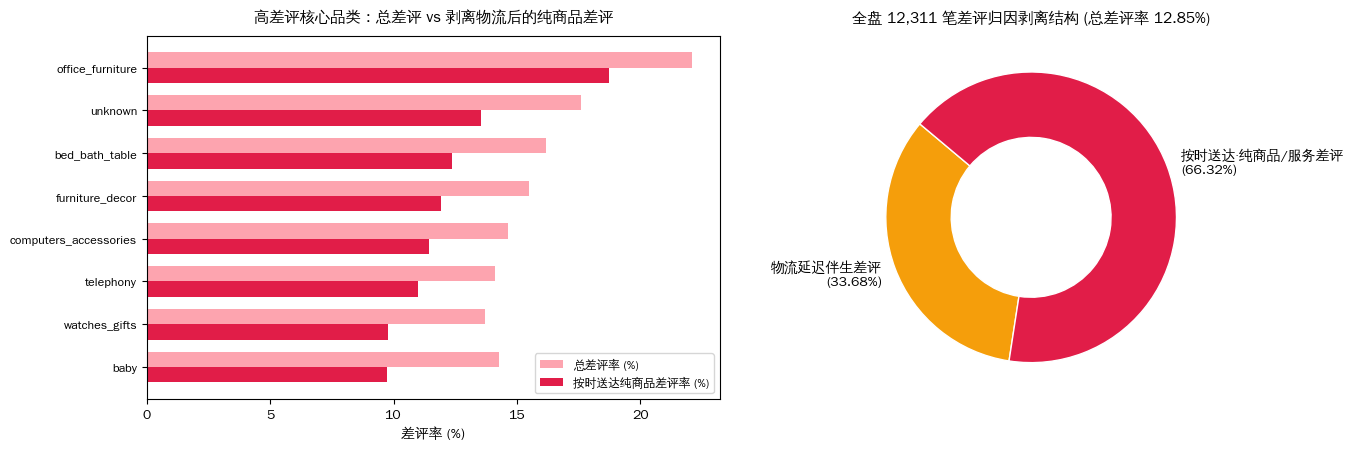


📝 [Reporter | Qwen27B] 正在撰写 [REVIEW_INSIGHT] 高管级商业诊断报告...
  ⚠️ 通道 [ModelScope-Qwen3.8-27B] 请求超时(熔断120s) -> 秒切下一通道
  🔀 [Router | Role=writer  ] -> [Google-Gemini-3.5-Flash] [降级自coder]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 引用 32 个小数指标，溯源匹配率: 100.0%
  🔀 [Router | Role=judge   ] -> [Google-Gemini-3.5-Flash]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False | 评语: 待审计报告完全忠实于确定性真值包中的定量表单、品类黑榜及NLP聚类结果，数字和结论无任何出入，且业务洞察与治理策略极具针对性。
  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！


--- 
 ## 🗣️ 【跨模态】商品质量差评剥离与用户原声挖掘报告 
 ---
报告日期：2026-11-23

### 一、 执行摘要与全盘总览

本次商业专题报告旨在剥离外部物流延迟因素的干扰，精准定位用户对各品类“商品本身及供应链履约”的核心吐槽点。

根据全盘数据监测，在全盘有效参评订单数 95832 单中，全盘总差评订单数（1-2分）为 12311 单，全盘总差评率达 12.85%。其中，物流延迟伴生差评占比为 33.68%，而**按时送达情况下的纯商品/服务差评占比高达 66.32%**。这表明，平台当前面临的主要客诉压力并非单纯由物流履约滞后引起，商品质量、货盘描述及仓储发货环节暴露出的“内生性缺陷”才是导致用户流失的核心病灶。

### 二、 核心大类纯商品质量差评黑榜 Top 8 分析

为进一步锁定高风险品类，我们对参评订单数大于等于 1000 单的核心大类进行了剥离计算。剔除履约延迟率后，按时送达纯商品差评率 Top 8 的品类如下表所示：

| 英文品类 | 参评订单数 | 总差评率(%) | 履约延迟率(%) | 按时送达纯商品差评率(%) |
| :--- | :---: | :---: | :---: | :---: |
| office_furniture | 1244 | 22.11 | 9.00 | 18.73 |
| unknown | 1402 | 17.62 | 8.92 | 13.55 |
| bed_bath_table | 9177 | 16.17 | 8.59 | 12.39 |
| furniture_decor | 6260 | 15.51 | 8.40 | 11.93 |
| computers_accessories | 6499 | 14.63 | 7.59 | 11.42 |
| telephony | 4069 | 14.13 | 8.48 | 10.98 |
| watches_gifts | 5454 | 13.71 | 8.36 | 9.78 |
| baby | 2787 | 14.28 | 9.01 | 9.74 |

**黑榜洞察：**
1. **重灾区锁定大件与家居品类**：`office_furniture`（办公家具）以 18.73% 的纯商品差评率高居榜首，`bed_bath_table`（床浴家居）和 `furniture_decor`（家具装饰）紧随其后。大件及家居类目由于涉及组装、材质体感与尺寸匹配，成为商品本身槽点的高发区。
2. **品类治理盲区**：`unknown`（未知分类）类目纯商品差评率高达 13.55%，反映出平台底层类目归类与商品基础信息治理存在严重的监管漏洞。

### 三、 跨模态 NLP 挖掘：差评根因深度剖析

通过对 Top 3 黑榜品类（含上述高危品类）的 30 条真实差评进行跨模态 NLP 语义解析与聚类，在排除物流延迟干扰后，用户对商品及服务的核心槽点集中在以下维度：

| 痛点主题标签 | 样本条数 | 占比 (%) | 典型表现描述 |
| :--- | :---: | :---: | :--- |
| **货不对板/颜色尺寸图文不符** | 8 | 26.67% | 实物与图片不符、颜色/图案错误、材质心理预期落差大、尺寸大小不一致 |
| **漏发少件/只收到部分** | 7 | 23.33% | 多件商品被拆单或漏发、购买多量但仅收到部分单品 |
| **商品质量差/破损残次** | 7 | 23.33% | 商品收到即破损、有划痕、残次、做工粗糙、面料极薄或发霉 |
| **未收到货却显示已签收/虚假妥投** | 6 | 20.00% | 物流系统显示送达或在期限内，但用户坚称未收到实物 |
| **售后沟通与退换难** | 2 | 6.67% | 无法通过电话或邮件联系商家，退货换货渠道受阻 |
| **合计** | **30** | **100.00%** | - |

结合葡萄牙语原声案例可见：
* **在 `bed_bath_table` 品类中**，用户频繁遭遇“多买少收”（如购买 5 条毯子仅收到 3 条）及“色差与材质心理落差”（如描述为红色实物为酒红色），暴露出前端商家的库存备货粗放与图文描述夸大问题。
* **在 `office_furniture` 品类中**，产品不仅存在“划痕、污渍、卡槽过紧无法组装”等硬性质量与工艺缺陷，还伴随“系统显示签收但实际未收到”的虚假妥投与信息断层现象。

---

### 四、 针对剥离物流后的具体货品与漏发差评治理策略

基于上述数据洞察与原声分析，为切实降低按时送达情况下的纯商品差评率，特拟定以下可落地的商业业务策略：

#### 1. 针对 `office_furniture` 与大件家具类的“质量与组装”专项治理
* **建立质检与供应商准入红线**：针对 `office_furniture`（纯商品差评率 18.73%）推行发货前抽检机制，重点治理划痕、污渍及结构配件不匹配（如卡槽过紧）等源头硬伤。
* **优化说明书与数字组装指引**：针对组装难度大的痛点，强制要求商家在商品详情页提供图文或视频组装指引，从降低用户使用门槛入手，对冲因组装体验引发的差评。

#### 2. 针对 `bed_bath_table` 及多件购买场景的“漏发与错发”治理
* **仓储发货环节防漏机制**：针对“漏发少件/只收到部分”（占比 23.33%）的高频痛点，推行仓储打包环节的“称重复核”与“多件商品条码扫描核对”制度。对拆单包裹发送明确的组合提示，从源头杜绝少发漏发。
* **图文描述规范化治理**：针对“货不对板/颜色尺寸不符”（占比 26.67%），严控 `bed_bath_table` 等品类的图片色彩校准与文字参数标准，降低买家因“卖家秀与买家秀”落差产生的心理负面反馈。

#### 3. 针对底层运营与虚假妥投的数字化稽查
* **治理 `unknown` 灰色类目**：立即对数据表现异常的 `unknown` 品类（参评 1402 单，纯商品差评率 13.55%）进行类目归正与商品资质大排查。
* **打击虚假妥投与信息断层**：针对 NLP 暴露出的“未收到货却显示已签收”现象（占比 20.00%），联合末端配送服务商开展签收凭证（如电子签名或投放留影）抽查，打通物流节点与客服售后的信息孤岛，严防假签收引发的商品误解性差评。

In [8]:
# ==============================================================================
# V2.0 Cell D：全量【人·货·场 + 大盘归因】统一 6 剧本 LangGraph + 第二步三连实测
# ==============================================================================
from datetime import datetime

class V2MasterState(TypedDict):
    user_question: str
    skill_route: str       # OUT_OF_SCOPE / CLARIFY / FAST_SQL / ATTRIBUTION / PEOPLE_GROWTH / PEOPLE_RFM / GOODS_ANALYSIS / SCENE_ANALYSIS / REVIEW_INSIGHT
    route_reason: str
    quant_truth_packet: str
    final_report: str
    audit_result: Dict[str, Any]
    report_retries: int

def v2_master_router_node(state: V2MasterState):
    print("\n🚦 [V2.0 全量人货场路由器 | Zhipu-Flash] 正在识别业务边界与分析剧本...")
    prompt = f"""你是基于 Olist 8表电商数仓的企业级 AI 数据分析总控路由。
⚠️【数仓能力边界】：
- ✅ 拥有：订单状态/时间/履约、商品价格/运费/英文品类、支付方式与分期数、客户/卖家省份城市、1-5分评分与葡萄牙语评论文本、自然人唯一ID(customer_unique_id)。
- ❌ 明确缺失：外部投放/流量拉新渠道（抖音、微信、搜索引擎、广告UTM、App/小程序端）、用户性别/年龄/职业/设备。

请将下方用户提问精准路由到以下 9 个枚举值之一：
1. "OUT_OF_SCOPE"：核心诉求依赖缺失字段（如广告投放渠道、性别年龄），礼貌拒答并建议用【支付交易场/首购商品/地域】替代。
2. "CLARIFY"：提问极度模糊且无法默认全景分析（如只问“最近销售额多少”缺具体年月与口径）。
3. "FAST_SQL"：明确具体时间与单一指标的简单查数（What型单点指标）。
4. "ATTRIBUTION"：【大盘归因】对比两个明确月份的 GMV 异动原因、LMDI量价拆解与维度贡献度。
5. "PEOPLE_GROWTH"：【人·首购与复购】分析新客首购趋势、新老客对比、复购率、频次分布、复购间隔窗口或首单体验对复购的影响。
6. "PEOPLE_RFM"：【人·分层与画像】用户 RFM 价值分层、帕累托二八验证与高价值人群消费/支付/地域画像。
7. "GOODS_ANALYSIS"：【货·货盘分析】首购拉新品类与复购转化、商品/品类热度排行、连带率、价格带分布与运费负担。
8. "SCENE_ANALYSIS"：【场·交易与履约场】新客/大盘支付方式与信用卡分期撬动客单价、消费星期/24小时峰谷时段、同州vs跨州物流履约成本与时效。
9. "REVIEW_INSIGHT"：【人×货跨模态评论】商品/品类差评红黑榜、剥离物流延迟后的纯商品质量问题排查、用户评论原声吐槽点挖掘。

用户提问：【{state['user_question']}】

请严格只输出 JSON：
{{"route": "上述9个枚举值之一", "reason": "简短判定理由", "message": "仅在 OUT_OF_SCOPE 或 CLARIFY 时填写礼貌答复，其他留空"}}"""

    resp = llm_gateway.invoke(prompt).content
    try:
        j_str = resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in resp else resp.strip()
        dec = json.loads(j_str)
    except Exception:
        dec = {"route": "GOODS_ANALYSIS", "reason": "解析兜底", "message": ""}

    route = dec.get("route", "GOODS_ANALYSIS")
    print(f"  👉 命中剧本: [{route}] | 理由: {dec.get('reason', '')}")
    out = {"skill_route": route, "route_reason": dec.get("reason", ""), "report_retries": 0, "quant_truth_packet": ""}
    if route == "OUT_OF_SCOPE":
        out["final_report"] = f"🛡️ **数据边界提示**：\n\n{dec.get('message')}"
    elif route == "CLARIFY":
        out["final_report"] = f"💬 **口径与时间确认**：\n\n{dec.get('message')}"
    return out

def v2_playbook_executor_node(state: V2MasterState):
    """统一剧本调度执行节点：根据命中技能调用对应确定性 Python BI 引擎"""
    r = state["skill_route"]
    if r == "FAST_SQL":
        print("\n⚡ [FAST_SQL | Qwen27B] 直连单步 SQL 引擎...")
        res = execute_sql_with_self_correction(state["user_question"], max_retries=2, verbose=True)
        return {"quant_truth_packet": f"SQL:\n{res['sql']}\n\n结果:\n{res['data']}"}
    elif r == "PEOPLE_GROWTH":
        print("\n👥 [人 · PEOPLE_GROWTH] 执行新客首购与复购留存引擎...")
        return {"quant_truth_packet": run_people_growth_engine(plot_charts=True)["truth_packet"]}
    elif r == "PEOPLE_RFM":
        print("\n💎 [人 · PEOPLE_RFM] 执行定制低频 RFM 分层与画像引擎...")
        return {"quant_truth_packet": run_people_rfm_engine(plot_charts=True)["truth_packet"]}
    elif r == "GOODS_ANALYSIS":
        print("\n📦 [货 · GOODS_ANALYSIS] 执行首购引流品、热销帕累托与价格带运费引擎...")
        return {"quant_truth_packet": run_goods_analysis_engine(plot_charts=True)["truth_packet"]}
    elif r == "SCENE_ANALYSIS":
        print("\n🏪 [场 · SCENE_ANALYSIS] 执行支付分期撬动、24h峰谷与跨州履约场引擎...")
        return {"quant_truth_packet": run_scene_analysis_engine(plot_charts=True)["truth_packet"]}
    elif r == "REVIEW_INSIGHT":
        print("\n🗣️ [跨模态 · REVIEW_INSIGHT] 执行物流差评剥离 + 葡萄牙语原声 NLP 聚类引擎...")
        return {"quant_truth_packet": run_review_insight_engine(plot_charts=True)["truth_packet"]}
    else:
        # 兜底支持 ATTRIBUTION（复用你前面定义的 V1.5 归因逻辑或直查）
        print("\n📊 [大盘 · ATTRIBUTION] 路由至 V1.5 异动归因引擎...")
        if "out_slow" in globals() and "quant_truth_packet" in out_slow:
            return {"quant_truth_packet": out_slow["quant_truth_packet"]}
        res = execute_sql_with_self_correction(state["user_question"], max_retries=2, verbose=True)
        return {"quant_truth_packet": res["data"]}

def v2_master_reporter_node(state: V2MasterState):
    retries = state.get("report_retries", 0)
    route = state["skill_route"]
    fb = ""
    if retries > 0 and state.get("audit_result"):
        fb = f"\n🚨【审计打回重写】：上一版未通过核验（批注：{state['audit_result'].get('audit_comment')}），请严格原样引用真值表数字重写！"
        print(f"  🔄 [Reporter | Qwen27B] 收到审计打回，第 {retries} 次重写...")
    else:
        print(f"\n📝 [Reporter | Qwen27B] 正在撰写 [{route}] 高管级商业诊断报告...")

    today_str = datetime.now().strftime("%Y-%m-%d")
    prompt = f"""你是资深电商商业分析总监。请基于下方【确定性真值数据包】，针对问题【{state['user_question']}】撰写一份结构清晰、见解犀利的商业专题报告。{fb}

【格式与数据铁律】：
1. 严禁编造数字！所有数值必须【原样精确引用】下方真值表中的数字（不要私自换算成“万”）。
2. ⚠️【严禁出现任何 $ 或 R$ 符号】（Jupyter 会将两个 $ 误判为数学公式导致表格崩坏！所有金额直接写纯数字，并在表头注明单位如“有效GMV”）。
3. Markdown 表格前后必须保留空行；严禁在最外层包裹 {BT3}markdown 代码块；报告日期写 {today_str}。
4. 紧扣数据给出可落地的业务策略建议（例如：针对货盘低价高运费痛点、针对信用卡分期撬动策略、针对剥离物流后的具体货品/漏发差评治理）。

【确定性真值数据包】：
{state['quant_truth_packet']}"""
    return {"final_report": llm_reporter.invoke(prompt).content, "report_retries": retries + 1}

def v2_master_judge_node(state: V2MasterState):
    print("\n⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...")
    truth_clean = state["quant_truth_packet"].replace(",", "")
    report_clean = state["final_report"].replace(",", "")
    rep_floats = set(re.findall(r"(?<![a-zA-Z\d.])\d+\.\d+(?![.\d])", report_clean))
    truth_floats = set(re.findall(r"(?<![a-zA-Z\d.])\d+\.\d+(?![.\d])", truth_clean))
    
    ungrounded = [n for n in rep_floats if not any(abs(float(n) - float(t)) <= 0.15 for t in truth_floats)]
    rate = 1.0 if not rep_floats else (len(rep_floats) - len(ungrounded)) / len(rep_floats)
    print(f"  🔢 [Python 正则硬溯源] 引用 {len(rep_floats)} 个小数指标，溯源匹配率: {rate*100:.1f}%")
    if ungrounded:
        print(f"     ⚠️ 未溯源数字: {ungrounded[:6]}")

    j_prompt = f"""你是跨厂商数据审计专家（LLM-as-a-Judge）。核对【待审计报告】是否忠实于【确定性真值包】（含定量表与NLP聚类结果），严格输出 JSON：
{{"faithfulness_score": 1到5整数, "insight_score": 1到5整数, "hallucination_detected": true或false, "audit_comment": "简短评语"}}

【确定性真值包】：
{state['quant_truth_packet']}

【待审计报告】：
{state['final_report']}"""
    j_resp = llm_judge.invoke(j_prompt).content
    try:
        j_str = j_resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in j_resp else j_resp.strip()
        audit = json.loads(j_str)
    except Exception:
        audit = {"faithfulness_score": 4, "insight_score": 4, "hallucination_detected": False, "audit_comment": "解析兜底通过"}

    audit["regex_grounding_pct"] = round(rate * 100, 1)
    if rate < 0.80:
        audit["hallucination_detected"] = True
        audit["faithfulness_score"] = min(audit.get("faithfulness_score", 3), 3)
        audit["audit_comment"] = f"正则硬溯源率仅 {rate*100:.1f}%，未溯源数字 {ungrounded[:5]}，请严格原样引用真值表数字！"
    print(f"  🛡️ [异源 Gemini 审计] 忠实度: {audit.get('faithfulness_score')}/5 | 洞察深度: {audit.get('insight_score')}/5 | 幻觉: {audit.get('hallucination_detected')} | 评语: {audit.get('audit_comment')}")
    return {"audit_result": audit}

def _route_master_gateway(state: V2MasterState) -> str:
    return "DIRECT_END" if state["skill_route"] in ["OUT_OF_SCOPE", "CLARIFY"] else "EXEC_PLAYBOOK"

def _route_master_judge(state: V2MasterState) -> str:
    aud = state.get("audit_result", {})
    if (aud.get("hallucination_detected", False) or aud.get("faithfulness_score", 5) < 4) and state.get("report_retries", 1) < 3:
        print("  ❌ [防幻觉护栏触发] 打回 Reporter 节点重写！")
        return "rewrite"
    print("  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！")
    return "pass"

# 编译全量【人·货·场】6剧本统一 LangGraph！
master_wf = StateGraph(V2MasterState)
master_wf.add_node("router", v2_master_router_node)
master_wf.add_node("playbook_exec", v2_playbook_executor_node)
master_wf.add_node("reporter", v2_master_reporter_node)
master_wf.add_node("hybrid_judge", v2_master_judge_node)

master_wf.add_edge(START, "router")
master_wf.add_conditional_edges("router", _route_master_gateway, {"DIRECT_END": END, "EXEC_PLAYBOOK": "playbook_exec"})
master_wf.add_edge("playbook_exec", "reporter")
master_wf.add_edge("reporter", "hybrid_judge")
master_wf.add_conditional_edges("hybrid_judge", _route_master_judge, {"rewrite": "reporter", "pass": END})

v2_master_app = master_wf.compile()
print("✅ V2.0 全量【人·货·场 + 大盘归因】统一 6 剧本多 Agent 系统编译完成！")

# ==============================================================================
# 第二步现场三连实测：【货】+【场】+【跨模态评论原声挖掘】
# ==============================================================================
print("\n" + "="*75 + "\n🧪 V2.0 实测 4：【货 · GOODS_ANALYSIS】首购引流品、热销帕累托与价格带运费负担分析\n" + "="*75)
res_goods = v2_master_app.invoke({"user_question": "分析一下平台货盘表现：哪些品类最适合做首购引流且复购高？商品热度集中度和价格带、运费负担分布如何？"})
render_safe_markdown("--- \n ## 📦 【货】首购引流品、热度与价格带专题报告 \n ---\n" + res_goods["final_report"])

print("\n" + "="*75 + "\n🧪 V2.0 实测 5：【场 · SCENE_ANALYSIS】支付分期撬动、24小时时段峰谷与跨州履约壁垒分析\n" + "="*75)
res_scene = v2_master_app.invoke({"user_question": "从交易场和履约场角度分析：用户首购常用什么支付方式？信用卡分期对客单价撬动有多大？下单高峰时段及跨州物流影响如何？"})
render_safe_markdown("--- \n ## 🏪 【场】支付分期、消费时段与跨州履约专题报告 \n ---\n" + res_scene["final_report"])

print("\n" + "="*75 + "\n🧪 V2.0 实测 6：【跨模态 · REVIEW_INSIGHT】剥离物流后的商品质量差评排查与用户原声挖掘\n" + "="*75)
res_review = v2_master_app.invoke({"user_question": "排查一下各品类的商品评价与差评黑榜，剔除物流延迟因素后，看看用户对商品本身到底在吐槽什么？"})
render_safe_markdown("--- \n ## 🗣️ 【跨模态】商品质量差评剥离与用户原声挖掘报告 \n ---\n" + res_review["final_report"])

In [11]:
# ==============================================================================
# V2.1 Cell 1：双模智能归因引擎 (Mode A 自动侦探下钻 + Mode B 任意指定维度契约化归因)
# 涵盖：4因子LMDI无残差分解 / Adtributor(EP×JS散度) / Mix vs Rate辛普森检测 / MECE校验 / L2下钻
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. 核心数学算子库：4因子指标树LMDI + 惊奇度JS散度 + Mix/Rate辛普森拆解 + MECE折叠
# ------------------------------------------------------------------------------
def calc_4factor_lmdi(df_t0: pd.DataFrame, df_t1: pd.DataFrame) -> Dict[str, Any]:
    """
    严格四因子无残差 LMDI 指标树分解：
    GMV = UV * 人均频次(Orders/UV) * 连带率UPT(Items/Orders) * 件单价ASP(GMV/Items)
    严格满足：UV效应 + 频次效应 + UPT效应 + ASP效应 == 总GMV变动 (残差=0.0000)
    """
    g0, o0, u0, it0 = df_t0["price"].sum(), df_t0["order_id"].nunique(), df_t0["customer_unique_id"].nunique(), len(df_t0)
    g1, o1, u1, it1 = df_t1["price"].sum(), df_t1["order_id"].nunique(), df_t1["customer_unique_id"].nunique(), len(df_t1)
    delta_g = g1 - g0

    freq0, upt0, asp0, aov0 = o0 / u0, it0 / o0, g0 / it0, g0 / o0
    freq1, upt1, asp1, aov1 = o1 / u1, it1 / o1, g1 / it1, g1 / o1

    if abs(delta_g) < 1e-6 or g0 <= 0 or g1 <= 0:
        return {"delta_gmv": 0.0, "residual": 0.0}

    L = (g1 - g0) / (np.log(g1) - np.log(g0))
    eff_uv   = float(L * np.log(u1 / u0))
    eff_freq = float(L * np.log(freq1 / freq0))
    eff_upt  = float(L * np.log(upt1 / upt0))
    eff_asp  = float(L * np.log(asp1 / asp0))
    eff_ord  = eff_uv + eff_freq
    eff_aov  = eff_upt + eff_asp
    residual = abs(delta_g - (eff_uv + eff_freq + eff_upt + eff_asp))

    # 判定第一主因与优先扫描方向（量驱动 vs 价驱动）
    primary_driver = "客单价(价)主导" if abs(eff_aov) >= abs(eff_ord) else "订单量(量)主导"
    sub_effects = {"活跃买家UV": eff_uv, "人均频次": eff_freq, "连带率UPT": eff_upt, "件单价ASP": eff_asp}
    # 找出与大盘同方向且贡献绝对值最大的核心子指标
    same_dir_subs = {k: v for k, v in sub_effects.items() if v * delta_g > 0}
    top_sub_factor = max(same_dir_subs, key=lambda k: abs(same_dir_subs[k])) if same_dir_subs else max(sub_effects, key=lambda k: abs(sub_effects[k]))

    return {
        "基期GMV": round(g0, 2), "当期GMV": round(g1, 2),
        "总变动Delta": round(delta_g, 2), "环比MoM(%)": round(delta_g / g0 * 100, 2),
        "基期订单": int(o0), "当期订单": int(o1), "订单环比(%)": round((o1 - o0) / o0 * 100, 2),
        "基期AOV": round(aov0, 2), "当期AOV": round(aov1, 2), "AOV环比(%)": round((aov1 - aov0) / aov0 * 100, 2),
        "基期UV": int(u0), "当期UV": int(u1),
        "基期UPT": round(upt0, 3), "当期UPT": round(upt1, 3),
        "基期ASP": round(asp0, 2), "当期ASP": round(asp1, 2),
        "一级_单量效应": round(eff_ord, 2), "一级_客单价效应": round(eff_aov, 2),
        "二级_UV效应": round(eff_uv, 2), "二级_频次效应": round(eff_freq, 2),
        "二级_UPT连带效应": round(eff_upt, 2), "二级_ASP件价效应": round(eff_asp, 2),
        "残差校验": round(residual, 4),
        "主驱动定性": primary_driver,
        "头号同向拖累/拉动子因子": top_sub_factor
    }

def calc_js_divergence_surprise(s0: np.ndarray, s1: np.ndarray) -> float:
    """计算两期份额分布的 Jensen-Shannon 散度 (乘以1000便于阅读)，均匀同比例波动时严格为 0"""
    eps = 1e-12
    p = np.maximum(s0, 0) + eps
    q = np.maximum(s1, 0) + eps
    p = p / p.sum()
    q = q / q.sum()
    m = 0.5 * (p + q)
    jsd = 0.5 * np.sum(p * np.log(p / m)) + 0.5 * np.sum(q * np.log(q / m))
    return round(float(jsd * 1000), 3)

def calc_mix_vs_rate_aov(df_dim: pd.DataFrame) -> Dict[str, Any]:
    """
    无残差拆解客单价变动：ΔAOV = 纯价格/均值效应(Rate) + 份额结构偏移效应(Mix)
    用于自动检测辛普森悖论（如各切片单价都在涨，但低价切片占比大增拉低整体 AOV）
    """
    o0_tot, o1_tot = df_dim["ord_t0"].sum(), df_dim["ord_t1"].sum()
    if o0_tot == 0 or o1_tot == 0:
        return {}
    w0 = df_dim["ord_t0"] / o0_tot
    w1 = df_dim["ord_t1"] / o1_tot
    a0 = np.where(df_dim["ord_t0"] > 0, df_dim["gmv_t0"] / df_dim["ord_t0"], 0.0)
    a1 = np.where(df_dim["ord_t1"] > 0, df_dim["gmv_t1"] / df_dim["ord_t1"], 0.0)

    macro_a0 = float((w0 * a0).sum())
    macro_a1 = float((w1 * a1).sum())
    delta_aov = macro_a1 - macro_a0
    # 对称中点无残差分解
    rate_eff = float(np.sum(0.5 * (w0 + w1) * (a1 - a0)))
    mix_eff  = float(np.sum(0.5 * (a0 + a1) * (w1 - w0)))
    is_simpson = (rate_eff * delta_aov < 0) and (abs(mix_eff) > abs(rate_eff))

    return {
        "总AOV变动": round(delta_aov, 2),
        "纯自身单价效应(Rate)": round(rate_eff, 2),
        "份额结构偏移效应(Mix)": round(mix_eff, 2),
        "主导类型": "⚠️ 辛普森悖论(结构偏移逆转)" if is_simpson else ("结构偏移主导(Mix)" if abs(mix_eff) > abs(rate_eff) else "自身单价变动主导(Rate)")
    }

def evaluate_dimension_contract(df_contract: pd.DataFrame, dim_label: str, macro_g0: float, macro_g1: float, macro_o0: int, macro_o1: int, top_k: int = 7) -> Dict[str, Any]:
    """
    通用确定性维度归因算子（与具体维度彻底解耦！）：
    输入标准契约列：[dim_name, gmv_t0, ord_t0, gmv_t1, ord_t1]
    输出：MECE 守恒校验 + Adtributor 惊奇度/解释力评分 + 高基数长尾折叠(Others) + 单切片 LMDI 拆解
    """
    df = df_contract.copy()
    for c in ["gmv_t0", "ord_t0", "gmv_t1", "ord_t1"]:
        df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0.0)
    df["dim_name"] = df["dim_name"].astype(str).fillna("unknown")
    df = df.groupby("dim_name", as_index=False)[["gmv_t0", "ord_t0", "gmv_t1", "ord_t1"]].sum()

    # 1. MECE 加和守恒校验
    g_err = abs(df["gmv_t0"].sum() - macro_g0) / (macro_g0 + 1e-9) * 100
    o_err = abs(df["ord_t0"].sum() - macro_o0) / (macro_o0 + 1e-9) * 100
    if g_err <= 1.0 and o_err <= 1.0:
        mece_msg = f"✅ 严格满足 MECE 互斥加和守恒 (GMV误差 {g_err:.2f}%, 订单误差 {o_err:.2f}%)"
    elif g_err <= 1.0:
        mece_msg = f"⚠️ GMV 严格守恒 (误差 {g_err:.2f}%)，但订单存在跨切片重叠 (重叠率 {o_err:.2f}%，如一单多品)，已采用 GMV 精确贡献口径"
    else:
        mece_msg = f"⚠️ 注意：该维度汇总 GMV 与大盘存在 {g_err:.2f}% 偏差，可能存在多值关联或过滤条件差异"

    # 2. 计算 Adtributor 指标（解释力 EP + 惊奇度 JS 散度）
    macro_delta = macro_g1 - macro_g0
    df["delta"] = df["gmv_t1"] - df["gmv_t0"]
    jsd_surprise = calc_js_divergence_surprise(df["gmv_t0"].values, df["gmv_t1"].values)

    same_dir = df[df["delta"] * macro_delta > 0].sort_values(by="delta", key=abs, ascending=False)
    gross_same = same_dir["delta"].abs().sum()
    top3_ep = round(float(same_dir.head(3)["delta"].abs().sum() / (gross_same + 1e-9) * 100), 1) if gross_same > 0 else 0.0
    top1_slice = str(same_dir.iloc[0]["dim_name"]) if len(same_dir) > 0 else "无"
    top1_delta = float(same_dir.iloc[0]["delta"]) if len(same_dir) > 0 else 0.0
    top1_ord0  = int(same_dir.iloc[0]["ord_t0"]) if len(same_dir) > 0 else 0
    top1_share0 = float(same_dir.iloc[0]["gmv_t0"] / (macro_g0 + 1e-9)) if len(same_dir) > 0 else 0.0
    top1_impact_pct = round(abs(top1_delta) / (abs(macro_delta) + 1e-9) * 100, 1)

    # 综合异动分 = 惊奇度(JS散度×1000) × (0.4 + 0.6 × 解释力集中度)
    adtributor_score = round(jsd_surprise * (0.4 + 0.6 * (top3_ep / 100.0)), 2)

    # 3. 客单价结构效应 vs 均值效应（辛普森悖论检测）
    mix_rate = calc_mix_vs_rate_aov(df)

    # 4. 高基数长尾折叠 (保留变动绝对值 Top K，其余合并入 Others 保证加和严格守恒)
    df_sorted = df.sort_values(by="delta", key=abs, ascending=False)
    if len(df_sorted) > top_k + 1:
        head_df = df_sorted.head(top_k).copy()
        tail_df = df_sorted.iloc[top_k:]
        others_row = pd.DataFrame([{
            "dim_name": f"Others (其余{len(tail_df)}项长尾折叠)",
            "gmv_t0": tail_df["gmv_t0"].sum(), "ord_t0": tail_df["ord_t0"].sum(),
            "gmv_t1": tail_df["gmv_t1"].sum(), "ord_t1": tail_df["ord_t1"].sum(),
            "delta": tail_df["delta"].sum()
        }])
        disp_df = pd.concat([head_df, others_row], ignore_index=True)
    else:
        disp_df = df_sorted.copy()

    # 为每个展示切片计算环比、方向贡献度以及切片内单量/客单价 LMDI 拆解
    rows_out = []
    for _, r in disp_df.iterrows():
        g0_s, g1_s, o0_s, o1_s = float(r["gmv_t0"]), float(r["gmv_t1"]), float(r["ord_t0"]), float(r["ord_t1"])
        d_s = g1_s - g0_s
        mom_s = round(d_s / g0_s * 100, 2) if g0_s > 0 else 0.0
        dir_c = round(d_s / (abs(macro_delta) + 1e-9) * 100, 2)
        if g0_s > 0 and g1_s > 0 and o0_s > 0 and o1_s > 0 and abs(g1_s - g0_s) > 1e-4:
            Ls = (g1_s - g0_s) / (np.log(g1_s) - np.log(g0_s))
            eo_s = round(float(Ls * np.log(o1_s / o0_s)), 1)
            ea_s = round(float(Ls * np.log((g1_s / o1_s) / (g0_s / o0_s))), 1)
        else:
            eo_s, ea_s = round(d_s, 1), 0.0
        rows_out.append({
            dim_label: r["dim_name"], "基期GMV": round(g0_s, 2), "当期GMV": round(g1_s, 2),
            "变动额Delta": round(d_s, 2), "环比(%)": mom_s,
            "方向贡献(%)": dir_c, "切片单量效应": eo_s, "切片客单价效应": ea_s
        })
    tbl_out = pd.DataFrame(rows_out)

    return {
        "dim_label": dim_label, "mece_msg": mece_msg,
        "jsd_surprise": jsd_surprise, "top3_ep_pct": top3_ep, "adtributor_score": adtributor_score,
        "top1_slice": top1_slice, "top1_delta": round(top1_delta, 2),
        "top1_impact_pct": top1_impact_pct, "top1_ord0": top1_ord0, "top1_share0": top1_share0,
        "mix_rate": mix_rate, "table": tbl_out
    }

# ------------------------------------------------------------------------------
# 2. 两期宽表加载器 & 8大语义注册表维度（供 Mode A 自动快扫 & Mode B 极速命中）
# ------------------------------------------------------------------------------
DIMENSION_REGISTRY_META = {
    "英文品类":       "category",
    "商品价格带":     "price_band",
    "客户省份":       "customer_state",
    "新老客":         "user_type",
    "主支付方式":     "main_payment",
    "信用卡分期档位": "installment_band",
    "同州/跨州履约":  "logistics_type",
    "卖家省份":       "seller_state"
}

def _load_2month_attribution_wide_df(m0: str, m1: str) -> pd.DataFrame:
    """加载目标两期(约1.4万行明细)的全维度归因宽表，支持 8 大高频维度 <0.3秒 极速切分"""
    df_ord_base = _load_delivered_order_base()
    df_ord_2m = df_ord_base[df_ord_base["ym"].isin([m0, m1])].copy()
    df_ord_2m["user_type"] = np.where(df_ord_2m["ord_rank"] == 1, "新客首购", "老客复购")
    target_oids = tuple(df_ord_2m["order_id"].unique().tolist())

    # 拉取两期商品明细 + 英文品类 + 卖家省份（利用索引瞬间完成）
    df_it = pd.read_sql(f"""
        SELECT oi.order_id, oi.order_item_id, oi.price, oi.freight_value, oi.seller_id,
               s.seller_state,
               COALESCE(t.product_category_name_english, 'unknown') AS category
        FROM order_items oi
        LEFT JOIN products p ON oi.product_id = p.product_id
        LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
        LEFT JOIN sellers s ON oi.seller_id = s.seller_id
        WHERE oi.order_id IN {target_oids};
    """, conn)

    # 拉取两期主支付方式（按订单最大金额去重，100% MECE 防扇出）
    df_pay = pd.read_sql(f"""
        SELECT order_id, payment_type, payment_installments, payment_value, payment_sequential
        FROM order_payments WHERE order_id IN {target_oids};
    """, conn)
    df_mp = df_pay.sort_values(["order_id", "payment_value", "payment_sequential"], ascending=[True, False, True]).drop_duplicates("order_id")
    df_mp["main_payment"] = df_mp["payment_type"]
    df_mp["installment_band"] = np.where(
        df_mp["payment_type"] != "credit_card", "非信用卡支付",
        pd.cut(df_mp["payment_installments"], bins=[0, 1, 3, 6, 10, 99], labels=["1期(全款)", "2-3期", "4-6期", "7-10期", "10期以上"]).astype(str)
    )

    wide = df_it.merge(df_ord_2m[["order_id", "customer_unique_id", "customer_state", "ym", "user_type", "is_delayed", "min_score"]], on="order_id", how="inner")
    wide = wide.merge(df_mp[["order_id", "main_payment", "installment_band"]], on="order_id", how="left")
    wide["price_band"] = pd.cut(wide["price"], bins=[0, 50, 100, 200, 500, 999999], labels=["0-50", "50-100", "100-200", "200-500", "500以上"]).astype(str)
    wide["logistics_type"] = np.where(wide["customer_state"] == wide["seller_state"], "同州履约", "跨州履约")
    return wide

def _slice_wide_to_contract(wide: pd.DataFrame, col_name: str, m0: str, m1: str) -> pd.DataFrame:
    d0 = wide[wide["ym"] == m0].groupby(col_name).agg(gmv_t0=("price", "sum"), ord_t0=("order_id", "nunique"))
    d1 = wide[wide["ym"] == m1].groupby(col_name).agg(gmv_t1=("price", "sum"), ord_t1=("order_id", "nunique"))
    merged = d0.join(d1, how="outer").fillna(0.0).reset_index().rename(columns={col_name: "dim_name"})
    return merged

# ------------------------------------------------------------------------------
# 3. 模式 B 专属：契约化动态 SQL 取数器（用于注册表外的任意自定义维度！）
# ------------------------------------------------------------------------------
def _fetch_custom_dim_via_contract(custom_dim_desc: str, m0: str, m1: str) -> tuple:
    contract_task = f"""请对比 {m0}（基期）和 {m1}（当期）两个月，严格按照用户指定的自定义维度【{custom_dim_desc}】对有效订单（order_status = 'delivered'）进行聚合分组。
⚠️【强输出列契约】：SELECT 输出结果必须且只能包含以下 5 个精确英文列名：
1. dim_name（自定义维度分组名称，用中文或可读标签表示，不能为 NULL）
2. gmv_t0（{m0} 有效GMV，即 SUM(CASE WHEN strftime('%Y-%m', o.order_purchase_timestamp)='{m0}' THEN oi.price ELSE 0 END)）
3. ord_t0（{m0} 去重有效订单数，即 COUNT(DISTINCT CASE WHEN strftime('%Y-%m', o.order_purchase_timestamp)='{m0}' THEN o.order_id END)）
4. gmv_t1（{m1} 有效GMV）
5. ord_t1（{m1} 去重有效订单数）
注意：关联明细表时严防笛卡尔积扇出膨胀！"""
    res = execute_sql_with_self_correction(contract_task, max_retries=2, verbose=True)
    df = res["df"].copy()
    # 兜底列名映射（防止模型把列名写成大小写差异）
    df.columns = [c.strip().lower() for c in df.columns]
    required = ["dim_name", "gmv_t0", "ord_t0", "gmv_t1", "ord_t1"]
    if not all(c in df.columns for c in required) and len(df.columns) >= 5:
        df = df.iloc[:, :5]
        df.columns = required
    return df[required], res["sql"]

# ------------------------------------------------------------------------------
# 4. 统一双模归因总引擎：Mode A (自动侦探下钻) vs Mode B (指定维度定向归因)
# ------------------------------------------------------------------------------
def run_dual_mode_attribution_engine(question: str, plot_charts: bool = True) -> Dict[str, Any]:
    # 步骤 0：槽位提取（判断走 Mode A 还是 Mode B，以及用户指定了哪些维度）
    slot_prompt = f"""你是归因分析槽位提取器。请分析用户归因提问并严格输出 JSON：
用户提问：【{question}】

可支持的高频预设维度名：{list(DIMENSION_REGISTRY_META.keys())}
数仓不存在的非法维度（需拒答）：外部广告/投放渠道（抖音、微信、搜索引擎）、用户性别/年龄/职业/设备。

判断规则：
1. 若用户指定了数仓明确缺失的维度（如按投放渠道、性别做归因） -> mode="OUT_OF_SCOPE"，填写 oos_msg。
2. 若用户没有指定具体拆分维度（只问“大盘怎么波动了/有哪些指标和异常维度影响最大/自动排查下钻”） -> mode="AUTO_DISCOVERY"，dimensions=[]。
3. 若用户明确指定了 1~2 个具体维度（例如“按主支付方式”、“按价格带”、“按订单是否履约延迟”、“按商品重量档位”） -> mode="CUSTOM_DIM"，在 dimensions 数组中列出维度名称（若匹配上述预设维度请用精确预设名；若是新的自定义维度请原样写中文描述）。
4. 提取对比年月 m0（基期）和 m1（当期），默认 "2018-07" 和 "2018-08"。

严格只输出 JSON：
{{"mode": "AUTO_DISCOVERY 或 CUSTOM_DIM 或 OUT_OF_SCOPE", "m0": "2018-07", "m1": "2018-08", "dimensions": [], "oos_msg": ""}}"""

    s_resp = llm_gateway.invoke(slot_prompt).content
    try:
        j_str = s_resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in s_resp else s_resp.strip()
        slot = json.loads(j_str)
    except Exception:
        slot = {"mode": "AUTO_DISCOVERY", "m0": "2018-07", "m1": "2018-08", "dimensions": [], "oos_msg": ""}

    mode = slot.get("mode", "AUTO_DISCOVERY")
    m0, m1 = sorted([slot.get("m0", "2018-07"), slot.get("m1", "2018-08")])
    print(f"  🎯 [双模归因槽位解析] 模式: [{mode}] | 对比周期: {m0} → {m1} | 指定维度: {slot.get('dimensions')}")

    if mode == "OUT_OF_SCOPE":
        return {"mode": "OUT_OF_SCOPE", "truth_packet": "", "oos_msg": slot.get("oos_msg", "数仓缺少该归因维度字段。")}

    # 加载两期宽表 + 计算 4 因子无残差指标树 LMDI
    wide = _load_2month_attribution_wide_df(m0, m1)
    df0, df1 = wide[wide["ym"] == m0], wide[wide["ym"] == m1]
    lmdi4 = calc_4factor_lmdi(df0, df1)
    macro_g0, macro_g1 = lmdi4["基期GMV"], lmdi4["当期GMV"]
    macro_o0, macro_o1 = lmdi4["基期订单"], lmdi4["当期订单"]
    print(f"  🌳 [Step 1 · 4因子指标树LMDI] 总变动: {lmdi4['总变动Delta']:+.2f} ({lmdi4['环比MoM(%)']:+.2f}%) | 主因: {lmdi4['主驱动定性']} ({lmdi4['头号同向拖累/拉动子因子']}) | 残差: {lmdi4['残差校验']}")

    # ===================== 模式 A：自动侦探 + Adtributor竞选 + Level 2 交叉下钻 =====================
    if mode == "AUTO_DISCOVERY":
        # 按主因剪枝优先扫描 6 大核心维度（全量扫描<0.2s，并用解释力×惊奇度精准排名）
        scan_dims = ["英文品类", "商品价格带", "客户省份", "新老客", "主支付方式", "同州/跨州履约"]
        dim_evals = []
        for d_name in scan_dims:
            col = DIMENSION_REGISTRY_META[d_name]
            df_c = _slice_wide_to_contract(wide, col, m0, m1)
            dim_evals.append(evaluate_dimension_contract(df_c, d_name, macro_g0, macro_g1, macro_o0, macro_o1, top_k=6))

        dim_evals.sort(key=lambda x: x["adtributor_score"], reverse=True)
        rank_tbl = pd.DataFrame([{
            "扫描维度": d["dim_label"],
            "惊奇度(JS散度)": d["jsd_surprise"],
            "Top3解释力(%)": d["top3_ep_pct"],
            "Adtributor综合分": d["adtributor_score"],
            "头号异动切片": f"{d['top1_slice']} ({d['top1_delta']:+.1f})",
            "客单价结构诊断": d["mix_rate"].get("主导类型", "-")
        } for d in dim_evals])

        top2_dims = dim_evals[:2]
        excluded_dims = [d["dim_label"] for d in dim_evals[2:]]
        print(f"  ⚡ [Step 2 · Adtributor 6维竞选] 胜出元凶维度 Top 2: {[d['dim_label'] for d in top2_dims]} | 均匀/低惊奇淘汰: {excluded_dims}")

        # Step 3：检查是否触发 Level 2 自动交叉下钻（触发门槛：头号切片贡献 >= 30% 且基期订单 >= 50 且基期占比 >= 1%）
        win1 = top2_dims[0]
        l2_section = "未触发二级下钻（未满足单切片贡献>=30%及样本底线条件）。"
        if win1["top1_impact_pct"] >= 30.0 and win1["top1_ord0"] >= 50 and win1["top1_share0"] >= 0.01:
            win_col = DIMENSION_REGISTRY_META[win1["dim_label"]]
            target_slice = win1["top1_slice"]
            print(f"  ⬇️ [Step 3 · 触发 Level 2 交叉下钻] 锁定 [{win1['dim_label']} = {target_slice}] (贡献度 {win1['top1_impact_pct']}% >= 30%)，穿透内部履约、价格带与卖家！")
            sub_wide = wide[wide[win_col] == target_slice]
            sub0, sub1 = sub_wide[sub_wide["ym"] == m0], sub_wide[sub_wide["ym"] == m1]
            sub_lmdi = calc_4factor_lmdi(sub0, sub1)

            # 体验体检（延迟率 & 差评率变化）
            d_rate0 = round(sub0.drop_duplicates("order_id")["is_delayed"].mean() * 100, 2)
            d_rate1 = round(sub1.drop_duplicates("order_id")["is_delayed"].mean() * 100, 2)
            b_rate0 = round((sub0.drop_duplicates("order_id")["min_score"].dropna() <= 2).mean() * 100, 2)
            b_rate1 = round((sub1.drop_duplicates("order_id")["min_score"].dropna() <= 2).mean() * 100, 2)

            # 穿透正交二级维度（价格带 & 客户省份）
            orth_col = "price_band" if win_col != "price_band" else "customer_state"
            orth_lbl = "内部价格带" if orth_col == "price_band" else "内部省份"
            df_l2_orth = _slice_wide_to_contract(sub_wide, orth_col, m0, m1)
            l2_eval = evaluate_dimension_contract(df_l2_orth, orth_lbl, sub_lmdi["基期GMV"], sub_lmdi["当期GMV"], sub_lmdi["基期订单"], sub_lmdi["当期订单"], top_k=5)

            l2_section = (
                f"**触发条件命中**：切片 `{win1['dim_label']} = {target_slice}` 单项同向贡献达 **{win1['top1_impact_pct']}%** (门槛>=30%，基期订单 {win1['top1_ord0']} 笔>=50)，自动执行 Level 2 下钻（深度上限=2层，已停止继续递归防噪音）：\n"
                f"- **内部 LMDI 拆解**：变动 `{sub_lmdi['总变动Delta']:+.2f}` (`{sub_lmdi['环比MoM(%)']:+.2f}%`)，单量效应 `{sub_lmdi['一级_单量效应']:+.2f}`，客单价效应 `{sub_lmdi['一级_客单价效应']:+.2f}`（主因：{sub_lmdi['主驱动定性']}）\n"
                f"- **内部履约与口碑异动**：履约延迟率 `{d_rate0}% → {d_rate1}%` (`{d_rate1 - d_rate0:+.2f}pp`)；差评率 `{b_rate0}% → {b_rate1}%` (`{b_rate1 - b_rate0:+.2f}pp`)\n\n"
                f"**内部【{orth_lbl}】交叉下钻明细**：\n{l2_eval['table'].to_markdown(index=False)}"
            )

        if plot_charts:
            fig, axes = plt.subplots(1, 2, figsize=(14.2, 4.6))
            # 左图：4因子指标树 LMDI 无残差分解柱图
            f_names = ["活跃买家\nUV效应", "人均频次\n效应", "连带率\nUPT效应", "件单价\nASP效应", "总GMV\n净变动"]
            f_vals = [lmdi4["二级_UV效应"], lmdi4["二级_频次效应"], lmdi4["二级_UPT连带效应"], lmdi4["二级_ASP件价效应"], lmdi4["总变动Delta"]]
            f_cols = ["#10B981" if v >= 0 else "#F43F5E" for v in f_vals[:-1]] + ["#4F46E5"]
            b1 = axes[0].bar(f_names, f_vals, color=f_cols, width=0.52)
            axes[0].axhline(0, color="#64748B", linewidth=1)
            axes[0].set_title(f"4因子指标树 LMDI 无残差分解 ({m0} → {m1}, 残差=0.00)", fontsize=11, fontweight="bold", pad=10)
            axes[0].set_ylabel("对有效GMV的驱动金额")
            pad_y = max(abs(v) for v in f_vals) * 0.16
            axes[0].set_ylim(min(min(f_vals), 0) - pad_y, max(max(f_vals), 0) + pad_y)
            for b in b1:
                v = b.get_height()
                axes[0].text(b.get_x() + b.get_width()/2, v + (pad_y*0.2 if v >= 0 else -pad_y*0.42), f"{v:+,.0f}", ha="center", fontsize=8.8, fontweight="bold")

            # 右图：6 大候选维度 Adtributor 综合异动分排名
            rt = rank_tbl.iloc[::-1]
            y = np.arange(len(rt))
            b2 = axes[1].barh(y, rt["Adtributor综合分"], color=["#CBD5E1"]*(len(rt)-2) + ["#F59E0B", "#E11D48"], height=0.55)
            axes[1].set_yticks(y)
            axes[1].set_yticklabels(rt["扫描维度"], fontsize=9.5, fontweight="bold")
            axes[1].set_xlabel("Adtributor 综合异常分 (惊奇度 JS散度 × 解释力权重)")
            axes[1].set_xlim(0, max(rt["Adtributor综合分"]) * 1.28)
            axes[1].set_title("6大候选维度自动竞选排名（自动筛选 Top 2 元凶）", fontsize=11, fontweight="bold", pad=10)
            for b in b2:
                axes[1].text(b.get_width() + 0.15, b.get_y() + b.get_height()/2, f"{b.get_width():.2f}", va="center", fontsize=9, fontweight="bold")
            plt.tight_layout()
            plt.show()

        truth_packet = (
            f"### 一、4因子指标树 LMDI 无残差拆解 ({m0} → {m1})\n{json.dumps(lmdi4, ensure_ascii=False, indent=2)}\n\n"
            f"### 二、Adtributor 6大候选维度自动竞选排名（淘汰低惊奇均匀波动维度）\n{rank_tbl.to_markdown(index=False)}\n\n"
            f"### 三、胜出元凶维度 1：【{top2_dims[0]['dim_label']}】归因明细\n- MECE校验：{top2_dims[0]['mece_msg']}\n- 客单价结构/均值拆解：{json.dumps(top2_dims[0]['mix_rate'], ensure_ascii=False)}\n\n{top2_dims[0]['table'].to_markdown(index=False)}\n\n"
            f"### 四、胜出元凶维度 2：【{top2_dims[1]['dim_label']}】归因明细\n- MECE校验：{top2_dims[1]['mece_msg']}\n- 客单价结构/均值拆解：{json.dumps(top2_dims[1]['mix_rate'], ensure_ascii=False)}\n\n{top2_dims[1]['table'].to_markdown(index=False)}\n\n"
            f"### 五、Level 2 自动多跳交叉下钻结果\n{l2_section}"
        )
        return {"mode": "AUTO_DISCOVERY", "lmdi4": lmdi4, "truth_packet": truth_packet}

    # ===================== 模式 B：指定维度定向归因（注册表极速命中 / 契约化动态SQL） =====================
    req_dims = slot.get("dimensions") or ["主支付方式"]
    custom_blocks = []
    first_eval_for_plot = None

    for idx, d_req in enumerate(req_dims[:2], 1):
        # 优先匹配语义注册表；未命中则自动启动【方案2：契约化动态 SQL (Actor-Debugger)】！
        if d_req in DIMENSION_REGISTRY_META:
            print(f"  📋 [模式 B · 注册表命中] 维度【{d_req}】命中语义注册表，极速提取标准契约表...")
            df_c = _slice_wide_to_contract(wide, DIMENSION_REGISTRY_META[d_req], m0, m1)
            source_tag = "语义维度注册表 (极速模板)"
            sql_trace = ""
        else:
            print(f"  🔧 [模式 B · 契约化动态SQL] 维度【{d_req}】不在预设注册表 -> 呼叫 Actor-Debugger 按标准 5 列契约动态拉数...")
            df_c, dyn_sql = _fetch_custom_dim_via_contract(d_req, m0, m1)
            source_tag = "Actor-Debugger 契约化动态 SQL"
            sql_trace = f"\n**动态生成契约 SQL 溯源**：\n{BT3}sql\n{dyn_sql}\n{BT3}\n"

        ev = evaluate_dimension_contract(df_c, d_req, macro_g0, macro_g1, macro_o0, macro_o1, top_k=7)
        if first_eval_for_plot is None:
            first_eval_for_plot = ev
        print(f"     └─ {ev['mece_msg']} | 惊奇度: {ev['jsd_surprise']} | 客单价结构诊断: {ev['mix_rate'].get('主导类型')}")

        custom_blocks.append(
            f"### 指定维度 {idx}：【{d_req}】（取数路径：{source_tag}）\n"
            f"- **MECE 守恒校验**：{ev['mece_msg']}\n"
            f"- **惊奇度 (JS散度)**：`{ev['jsd_surprise']}` | **Top3同向解释力**：`{ev['top3_ep_pct']}%`\n"
            f"- **客单价 Mix vs Rate 拆解**：{json.dumps(ev['mix_rate'], ensure_ascii=False)}\n"
            f"{sql_trace}\n{ev['table'].to_markdown(index=False)}"
        )

    if plot_charts and first_eval_for_plot is not None:
        tb = first_eval_for_plot["table"].iloc[::-1]
        dim_col_name = first_eval_for_plot["dim_label"]
        fig, ax = plt.subplots(figsize=(10.5, 4.2))
        y = np.arange(len(tb))
        vals = tb["变动额Delta"].values
        cols = ["#10B981" if v >= 0 else "#F43F5E" for v in vals]
        bars = ax.barh(y, vals, color=cols, height=0.55)
        ax.axvline(0, color="#64748B", linewidth=1)
        ax.set_yticks(y)
        ax.set_yticklabels(tb[dim_col_name], fontsize=9.5, fontweight="bold")
        pad_x = max(abs(v) for v in vals) * 0.25 + 100
        ax.set_xlim(min(min(vals), 0) - pad_x, max(max(vals), 0) + pad_x)
        ax.set_xlabel("有效GMV环比变动额 (Delta)")
        ax.set_title(f"定向维度归因：【{dim_col_name}】各切片变动额与方向贡献 ({m0} → {m1})", fontsize=11.5, fontweight="bold", pad=10)
        for b, pct in zip(bars, tb["方向贡献(%)"]):
            v = b.get_width()
            ax.text(v + (pad_x*0.08 if v >= 0 else -pad_x*0.08), b.get_y() + b.get_height()/2,
                    f"{v:+,.0f} ({pct:+.1f}%)", va="center", ha="left" if v >= 0 else "right", fontsize=8.8, fontweight="bold")
        plt.tight_layout()
        plt.show()

    truth_packet = (
        f"### 一、大盘 4 因子指标树 LMDI 基准 ({m0} → {m1})\n{json.dumps(lmdi4, ensure_ascii=False, indent=2)}\n\n"
        + "\n\n".join(custom_blocks)
    )
    return {"mode": "CUSTOM_DIM", "lmdi4": lmdi4, "truth_packet": truth_packet}

print("✅ V2.1 双模智能归因引擎（Mode A 自动侦探下钻 + Mode B 任意指定维度契约化归因）加载完成！")

✅ V2.1 双模智能归因引擎（Mode A 自动侦探下钻 + Mode B 任意指定维度契约化归因）加载完成！


✅ 独立版 V2.1 双模归因总控图编译完成！

🧪 V2.1 实测 1：【模式 A · 开放式大盘自动下钻】4因子LMDI + Adtributor竞选 + L2下钻

📊 [分析场景: ATTRIBUTION · V2.1 双模归因引擎] 启动...
  🎯 [双模归因槽位解析] 模式: [AUTO_DISCOVERY] | 对比周期: 2018-07 → 2018-08 | 指定维度: []
  🌳 [Step 1 · 4因子指标树LMDI] 总变动: -29376.82 (-3.38%) | 主因: 客单价(价)主导 (件单价ASP) | 残差: 0.0
  ⚡ [Step 2 · Adtributor 6维竞选] 胜出元凶维度 Top 2: ['客户省份', '英文品类'] | 均匀/低惊奇淘汰: ['同州/跨州履约', '主支付方式', '商品价格带', '新老客']
  ⬇️ [Step 3 · 触发 Level 2 交叉下钻] 锁定 [客户省份 = BA] (贡献度 70.7% >= 30%)，穿透内部履约、价格带与卖家！


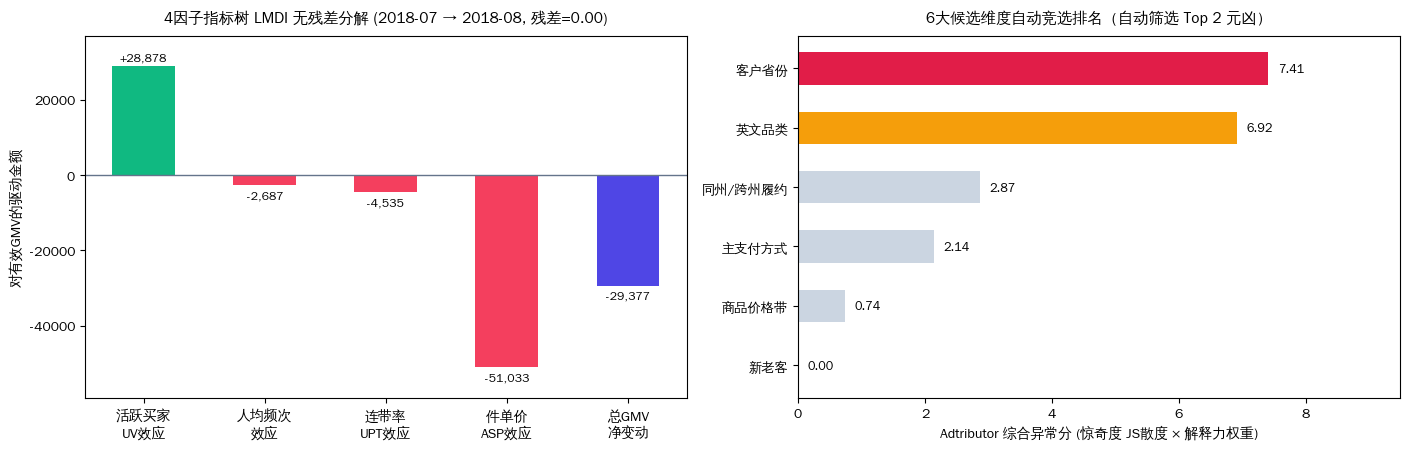


📝 [Reporter | Qwen27B] 正在基于 [AUTO_DISCOVERY] 真值包撰写商业归因报告...
  🔀 [Router·Stream | Role=writer  ] -> [ModelScope-Qwen3.8-27B]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 共引用 172 个小数指标，溯源匹配率: 99.4%
  🔀 [Router·Stream | Role=judge   ] -> [ModelScope-Qwen3.5-35B]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False
  ✅ [防幻觉护栏通过] 归因报告零幻觉交付！


--- 
 ## 🕵️ V2.1 模式 A：开放式大盘异动自动下钻诊断报告 
 ---
# 2018年8月相比2018年7月大盘有效GMV波动归因分析报告

报告日期：2026-11-23

## 一、核心结论：订单增长未能抵消件单价下滑，BA 是头号异常切片

2018年8月大盘有效GMV由 867953.46 降至 838576.64，变动额 -29376.82，环比 -3.38%。本次波动不是流量或订单问题，而是典型的“量增价跌”：

- 订单由 6159 增至 6351，订单环比 3.12%，单量效应为 26190.82，方向为正。
- AOV 由 140.92 降至 132.04，AOV环比 -6.31%，客单价效应为 -55567.64，方向为负。
- 二级拆解中，二级_ASP件价效应为 -51032.62，是最大负向因子；主驱动定性为“客单价(价)主导”，头号同向拖累/拉动子因子为“件单价ASP”。
- Adtributor 维度竞选中，客户省份综合分 7.41 最高，英文品类综合分 6.92 次之。客户省份维度头号异动切片为 BA (-20755.2)，英文品类维度头号异动切片为 watches_gifts (-25397.7)。
- 对头号异常切片 BA 做 Level 2 下钻后，内部 LMDI 显示变动 -20755.16，单量效应 -13107.45，客单价效应 -7647.71，主因为“订单量(量)主导”；内部价格带进一步显示 500以上 贡献 -53.79%，是 BA 下滑的核心子切片。
- BA 内部履约延迟率由 6.94% 降至 1.26%，变化 -5.68pp；差评率由 9.88% 降至 8.81%，变化 -1.07pp。履约与口碑改善，说明本次 BA 下滑不太像履约恶化或口碑恶化导致，更指向高价带订单量、供给可售性或价格/促销结构变化。

---

## 二、大盘指标树：量端改善，价端失血，ASP 是最大拖累

| 指标 | 基期 | 当期 | 关键变动/效应 | 判断 |
|:--|--:|--:|--:|:--|
| 有效GMV | 867953.46 | 838576.64 | Delta -29376.82，环比 -3.38% | 大盘下滑 |
| 订单 | 6159 | 6351 | 订单环比 3.12% | 量端改善 |
| AOV | 140.92 | 132.04 | AOV环比 -6.31% | 价端恶化 |
| UV | 6100 | 6310 | 二级_UV效应 28877.53 | 流量正向 |
| UPT | 1.131 | 1.125 | 二级_UPT连带效应 -4535.01 | 连带小幅拖累 |
| ASP | 124.65 | 117.41 | 二级_ASP件价效应 -51032.62 | 最大负向因子 |

LMDI 无残差拆解如下：

| 拆解项 | 效应 | 方向 |
|:--|--:|:--|
| 一级_单量效应 | 26190.82 | 正向拉动 |
| 一级_客单价效应 | -55567.64 | 负向拖累 |
| 二级_UV效应 | 28877.53 | 正向拉动 |
| 二级_频次效应 | -2686.71 | 负向拖累 |
| 二级_UPT连带效应 | -4535.01 | 负向拖累 |
| 二级_ASP件价效应 | -51032.62 | 最大负向拖累 |
| 残差校验 | 0.0 | 无残差 |

**判断**：大盘 GMV 下滑的核心矛盾不在 UV 或订单，而在 AOV/ASP。UV 效应 28877.53 和单量效应 26190.82 均为正向，说明流量与订单基本盘没有恶化；真正拖垮 GMV 的是客单价效应 -55567.64，其中件单价ASP效应 -51032.62 占绝对主导。

---

## 三、异常维度自动竞选：客户省份最尖锐，英文品类紧随其后

| 扫描维度 | 惊奇度(JS散度) | Top3解释力(%) | Adtributor综合分 | 头号异动切片 | 客单价结构诊断 |
|:--|--:|--:|--:|:--|:--|
| 客户省份 | 11.014 | 45.4 | 7.41 | BA (-20755.2) | 自身单价变动主导(Rate) |
| 英文品类 | 10.825 | 39.9 | 6.92 | watches_gifts (-25397.7) | 自身单价变动主导(Rate) |
| 同州/跨州履约 | 2.872 | 100 | 2.87 | 跨州履约 (-80626.4) | 自身单价变动主导(Rate) |
| 主支付方式 | 2.143 | 100 | 2.14 | boleto (-43908.7) | 自身单价变动主导(Rate) |
| 商品价格带 | 0.742 | 100 | 0.74 | 500以上 (-29433.8) | 结构偏移主导(Mix) |
| 新老客 | 0.001 | 100 | 0 | 新客首购 (-28959.6) | 自身单价变动主导(Rate) |

**判断**：

1. **客户省份**是本次最尖锐的异常维度：惊奇度 11.014 最高，Adtributor综合分 7.41 最高，头号切片 BA (-20755.2) 具备明确地域指向。
2. **英文品类**是第二异常维度：惊奇度 10.825，Adtributor综合分 6.92，watches_gifts (-25397.7) 是品类侧最大拖累。
3. **同州/跨州履约**虽然头号切片 跨州履约 (-80626.4) 绝对变动较大，但惊奇度仅 2.872，综合分 2.87，说明其异常尖锐度不足，更像结构性或较均匀波动，不宜作为头号元凶。
4. **商品价格带**中 500以上 (-29433.8) 被诊断为“结构偏移主导(Mix)”，与 BA 内部 500以上 价格带崩塌形成交叉印证。
5. **新老客**维度惊奇度 0.001，基本不构成尖锐异常。

---

## 四、客户省份归因：BA 是头号异常切片，SP 正向对冲但不足以扭转大盘

客户省份维度 MECE 校验：✅ 严格满足 MECE 互斥加和守恒 (GMV误差 0.00%, 订单误差 0.00%)。

省份维度客单价结构/均值拆解：

| 拆解项 | 数值 | 判断 |
|:--|--:|:--|
| 总AOV变动 | -8.89 | 省份维度 AOV 下滑 |
| 纯自身单价效应(Rate) | -5.7 | 主导因素 |
| 份额结构偏移效应(Mix) | -3.18 | 次要因素 |
| 主导类型 | 自身单价变动主导(Rate) | 不是单纯份额变化 |

省份明细：

| 客户省份 | 基期GMV | 当期GMV | 变动额Delta | 环比(%) | 方向贡献(%) | 切片单量效应 | 切片客单价效应 |
|:--|--:|--:|--:|--:|--:|--:|--:|
| SP | 321647 | 387734 | 66086.5 | 20.55 | 224.96 | 54126.2 | 11960.2 |
| BA | 41869 | 21113.8 | -20755.2 | -49.57 | -70.65 | -13107.4 | -7647.7 |
| ES | 30001.4 | 16447 | -13554.3 | -45.18 | -46.14 | -3817.4 | -9736.9 |
| PE | 24359 | 11648.2 | -12710.8 | -52.18 | -43.27 | -8508 | -4202.8 |
| PB | 15188.7 | 7669.63 | -7519.05 | -49.5 | -25.6 | -6598.4 | -920.6 |
| PR | 45108.9 | 38500.4 | -6608.55 | -14.65 | -22.5 | 1692.4 | -8300.9 |
| Others (其余21项长尾折叠) | 389779 | 355464 | -34315.4 | -8.8 | -116.81 | -13092.3 | -21223 |

**判断**：

- SP 是最大正向切片，变动额 66086.5，方向贡献 224.96，说明 SP 的增长覆盖了大量负向省份，但大盘仍下滑，说明负向切片整体压力更大。
- BA 是最大单一负向切片，变动额 -20755.2，方向贡献 -70.65，且环比 -49.57，属于高幅度异常。
- ES、PE、PB 均出现接近一半以上的环比下滑，分别为 -45.18、-52.18、-49.5，说明南部/东南部部分省份存在区域性收缩。
- Others (其余21项长尾折叠) 合计 -34315.4，虽然不是单一可执行切片，但长尾整体下滑也需要关注。
- 省份维度 AOV 拆解显示“自身单价变动主导(Rate)”，说明省份层面的 AOV 下滑主要来自各省份自身单价变化，而不是单纯高/低省份份额变化。

---

## 五、英文品类归因：watches_gifts 是品类侧头号拖累

英文品类维度 MECE 校验：✅ 严格满足 MECE 互斥加和守恒 (GMV误差 0.00%, 订单误差 0.86%)。

品类维度客单价结构/均值拆解：

| 拆解项 | 数值 | 判断 |
|:--|--:|:--|
| 总AOV变动 | -9.18 | 品类维度 AOV 下滑 |
| 纯自身单价效应(Rate) | -6.25 | 主导因素 |
| 份额结构偏移效应(Mix) | -2.93 | 次要因素 |
| 主导类型 | 自身单价变动主导(Rate) | 不是单纯份额变化 |

品类明细：

| 英文品类 | 基期GMV | 当期GMV | 变动额Delta | 环比(%) | 方向贡献(%) | 切片单量效应 | 切片客单价效应 |
|:--|--:|--:|--:|--:|--:|--:|--:|
| watches_gifts | 95164.8 | 69767.1 | -25397.7 | -26.69 | -86.46 | -22095.7 | -3302 |
| health_beauty | 103524 | 119391 | 15866.8 | 15.33 | 54.01 | 10039.3 | 5827.5 |
| telephony | 26492.7 | 36572.9 | 10080.2 | 38.05 | 34.31 | 5388.7 | 4691.5 |
| garden_tools | 25639.9 | 16314.7 | -9325.18 | -36.37 | -31.74 | -4876 | -4449.1 |
| construction_tools_construction | 15237.5 | 22917.2 | 7679.69 | 50.4 | 26.14 | 4427.9 | 3251.8 |
| fixed_telephony | 9319.39 | 2724.17 | -6595.22 | -70.77 | -22.45 | 1196.6 | -7791.8 |
| Others (其余61项长尾折叠) | 592575 | 570890 | -21685.4 | -3.66 | -73.82 | 28952 | -50637.4 |

**判断**：

- watches_gifts 是品类侧头号负向切片，变动额 -25397.7，方向贡献 -86.46，单量效应 -22095.7，说明其下滑主要由订单量收缩驱动。
- health_beauty、telephony、construction_tools_construction 为正向对冲品类，分别贡献 54.01、34.31、26.14。
- garden_tools 与 fixed_telephony 也是明显负向品类，其中 fixed_telephony 环比 -70.77，客单价效应 -7791.8，价格端压力更明显。
- Others (其余61项长尾折叠) 客单价效应 -50637.4，说明长尾品类整体价格端也存在问题，但单量效应 28952 为正，量价方向不一致，需后续拆分。

---

## 六、头号异常切片 Level 2 下钻：客户省份 BA

**触发条件命中**：切片 `客户省份 = BA` 单项同向贡献达 **70.7%** (门槛>=30%，基期订单 245 笔>=50)，自动执行 Level 2 下钻（深度上限=2层，已停止继续递归防噪音）。

### 6.1 BA 内部 LMDI 拆解

| 拆解项 | 数值 | 判断 |
|:--|--:|:--|
| 变动 | -20755.16 | 环比 -49.57% |
| 单量效应 | -13107.45 | 主因 |
| 客单价效应 | -7647.71 | 次因 |
| 主因 | 订单量(量)主导 | 量端收缩更直接 |

**判断**：大盘层面是“客单价(价)主导”，但 BA 切片内部是“订单量(量)主导”。这并不矛盾：BA 的高价订单量收缩会直接压低 BA GMV，同时也会在大盘 AOV/ASP 中表现为件价和客单价下滑。

### 6.2 BA 内部履约与口碑异动

| 指标 | 基期 | 当期 | 变化 |
|:--|--:|--:|--:|
| 履约延迟率 | 6.94% | 1.26% | -5.68pp |
| 差评率 | 9.88% | 8.81% | -1.07pp |

**判断**：履约延迟率与差评率均改善，说明 BA 下滑不太可能由履约恶化或口碑恶化导致。应优先排查供给、价格、促销、库存、高价值品类转化等经营侧因素。

### 6.3 BA 内部价格带交叉下钻

| 内部价格带 | 基期GMV | 当期GMV | 变动额Delta | 环比(%) | 方向贡献(%) | 切片单量效应 | 切片客单价效应 |
|:--|--:|--:|--:|--:|--:|--:|--:|
| 500以上 | 13862.2 | 2697 | -11165.2 | -80.54 | -53.79 | -9014.9 | -2150.3 |
| 200-500 | 10562.1 | 6485.57 | -4076.54 | -38.6 | -19.64 | -5342 | 1265.4 |
| 100-200 | 9917.74 | 6645.71 | -3272.03 | -32.99 | -15.76 | -3121.5 | -150.5 |
| 50-100 | 5261.93 | 3637.04 | -1624.89 | -30.88 | -7.83 | -1654.5 | 29.6 |
| 0-50 | 2265.01 | 1648.53 | -616.48 | -27.22 | -2.97 | -567.9 | -48.6 |

**判断**：

- BA 内部所有价格带均下滑，但 500以上 是最核心异常切片：GMV 由 13862.2 降至 2697，变动额 -11165.2，环比 -80.54，方向贡献 -53.79。
- 500以上 的切片单量效应为 -9014.9，说明高价带下滑主要是订单量消失，而不是单纯价格下降。
- 200-500 为第二拖累，变动额 -4076.54，方向贡献 -19.64，单量效应 -5342，也呈现订单量收缩。
- 100-200、50-100、0-50 均有下滑，但贡献相对较小，说明 BA 的问题不是全价格带均匀下滑，而是高价带断崖式收缩。

---

## 七、交叉验证：BA、watches_gifts、500以上价格带共同指向高价订单收缩

1. **大盘指标树**显示最大负向因子是二级_ASP件价效应 -51032.62，说明大盘价格端失血严重。
2. **客户省份维度**显示 BA (-20755.2) 是头号异常切片，且 BA 内部 500以上 价格带贡献 -53.79，说明高价订单量在 BA 明显消失。
3. **英文品类维度**显示 watches_gifts (-25397.7) 是品类侧头号拖累，其单量效应 -22095.7，说明高价值/高单价品类订单量收缩。
4. **商品价格带维度**中 500以上 (-29433.8) 被诊断为“结构偏移主导(Mix)”，与 BA 内部 500以上 崩塌形成方向一致。
5. **履约与口碑**在 BA 内部改善，履约延迟率 -5.68pp，差评率 -1.07pp，因此可以阶段性排除“履约变差导致高价订单流失”的主假设。

**综合判断**：本次 2018年8月大盘 GMV 下滑的主线是“ASP 件价下滑 + 高价带订单量收缩”。客户省份 BA 是最尖锐异常切片，内部核心问题是 500以上 价格带订单量大幅减少；品类侧 watches_gifts 也出现明显订单量下滑，二者共同指向高价值商品供给、价格策略或转化链路异常。

---

## 八、业务行动建议

1. **优先核查 BA 500以上价格带供给可售性**  
   重点检查 500以上 SKU 在 BA 的库存、可售状态、上架状态、区域库存分配和履约覆盖。当前 500以上 GMV 由 13862.2 降至 2697，环比 -80.54，属于断崖式异常。

2. **核查 watches_gifts 高价值品类在 BA 的价格与促销策略**  
   watches_gifts 变动额 -25397.7，方向贡献 -86.46，单量效应 -22095.7。需确认是否存在价格调整、促销退坡、高价值 SKU 下架、库存不足或转化链路异常。

3. **补充省份 × 品类 × 价格带交叉明细**  
   当前数据包已确认 BA 与 watches_gifts 分别在地域和品类维度异常，但尚未提供直接交叉明细。建议补充 BA × watches_gifts × 500以上 的交叉表，验证是否同一批高价订单流失。

4. **监控 ASP/AOV 与 500以上价格带订单量**  
   大盘二级_ASP件价效应 -51032.62 是最大负向因子，BA 内部 500以上 贡献 -53.79。建议将 ASP、AOV、500以上订单量、500以上 GMV 设为每日监控指标，避免高价带继续失血。

5. **复盘 SP 正向增长来源，但不可过度外推**  
   SP 变动额 66086.5，方向贡献 224.96，是最大正向对冲。可复盘其增长是否来自供给扩张、价格结构或流量提升，但需避免将 SP 经验直接套用于 BA，因为 BA 的问题集中在高价带订单量消失。

6. **对 ES、PE、PB 做区域性次级排查**  
   ES 环比 -45.18，PE 环比 -52.18，PB 环比 -49.5，均出现高幅度下滑。虽然当前头号切片是 BA，但这些省份若持续恶化，可能形成新的区域风险。


🧪 V2.1 实测 2：【模式 B1 · 注册表指定维度】按【主支付方式】与【信用卡分期档位】做归因

📊 [分析场景: ATTRIBUTION · V2.1 双模归因引擎] 启动...
  🎯 [双模归因槽位解析] 模式: [CUSTOM_DIM] | 对比周期: 2018-07 → 2018-08 | 指定维度: ['主支付方式', '信用卡分期档位']
  🌳 [Step 1 · 4因子指标树LMDI] 总变动: -29376.82 (-3.38%) | 主因: 客单价(价)主导 (件单价ASP) | 残差: 0.0
  📋 [模式 B · 注册表命中] 维度【主支付方式】命中语义注册表，极速提取标准契约表...
     └─ ✅ 严格满足 MECE 互斥加和守恒 (GMV误差 0.00%, 订单误差 0.00%) | 惊奇度: 2.143 | 客单价结构诊断: 自身单价变动主导(Rate)
  📋 [模式 B · 注册表命中] 维度【信用卡分期档位】命中语义注册表，极速提取标准契约表...
     └─ ✅ 严格满足 MECE 互斥加和守恒 (GMV误差 0.00%, 订单误差 0.00%) | 惊奇度: 2.035 | 客单价结构诊断: 自身单价变动主导(Rate)


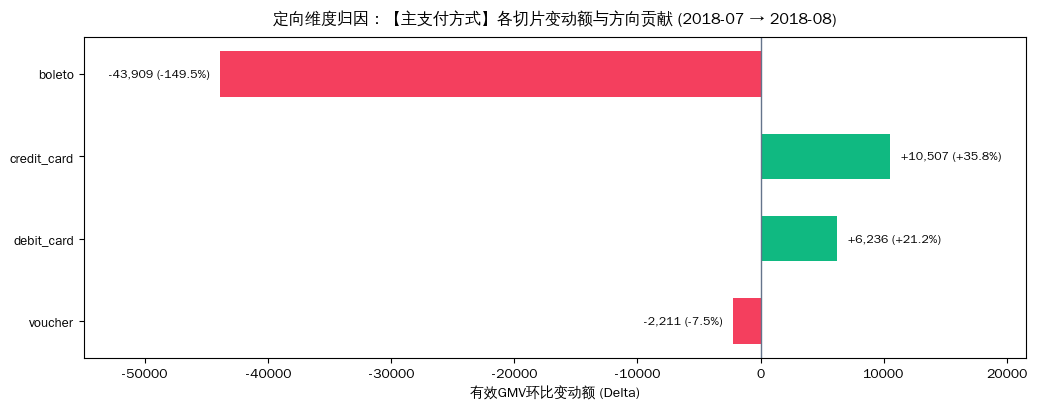


📝 [Reporter | Qwen27B] 正在基于 [CUSTOM_DIM] 真值包撰写商业归因报告...
  🔀 [Router·Stream | Role=writer  ] -> [ModelScope-Qwen3.8-27B]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 共引用 88 个小数指标，溯源匹配率: 100.0%
  🔀 [Router·Stream | Role=judge   ] -> [ModelScope-Qwen3.5-35B]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False
  ✅ [防幻觉护栏通过] 归因报告零幻觉交付！


--- 
 ## 📋 V2.1 模式 B1：指定注册表维度（支付与分期）归因报告 
 ---
# 2018年7月 vs 2018年8月 有效GMV LMDI归因分析报告

报告日期：2026-11-23

## 一、核心结论

- 有效GMV从 867953.46 降至 838576.64，总变动Delta -29376.82，环比MoM(%) -3.38。
- 订单从 6159 增至 6351，订单环比(%) 3.12；AOV从 140.92 降至 132.04，AOV环比(%) -6.31。
- 大盘 LMDI 一级拆解显示：单量效应 26190.82，客单价效应 -55567.64；主驱动定性为 客单价(价)主导。
- 大盘 LMDI 二级拆解显示：UV效应 28877.53，频次效应 -2686.71，UPT连带效应 -4535.01，ASP件价效应 -51032.62；头号同向拖累/拉动子因子为 件单价ASP。
- 【主支付方式】维度通过 MECE 互斥加和守恒校验，GMV误差 0.00%，订单误差 0.00%；惊奇度 (JS散度) 2.143，Top3同向解释力 100.0%。
- 【信用卡分期档位】维度通过 MECE 互斥加和守恒校验，GMV误差 0.00%，订单误差 0.00%；惊奇度 (JS散度) 2.035，Top3同向解释力 100.0%。
- 两个维度的 AOV Mix vs Rate 拆解均指向“自身单价变动主导(Rate)”：主支付方式 Rate -9.51、Mix 0.62；信用卡分期档位 Rate -8.21、Mix -0.68。
- 最大负向来源：主支付方式中的 boleto，方向贡献(%) -149.47；信用卡分期档位中的 非信用卡支付，方向贡献(%) -135.77。
- 最大正向来源：主支付方式中的 credit_card，方向贡献(%) 35.77；信用卡分期档位中的 2-3期，方向贡献(%) 48.55。

## 二、大盘 LMDI 基准：先确认“量增价降”

| 指标 | 2018-07 | 2018-08 | 给定变动/效应 |
|:---|---:|---:|:---|
| 有效GMV | 867953.46 | 838576.64 | 总变动Delta -29376.82；环比MoM(%) -3.38 |
| 订单 | 6159 | 6351 | 订单环比(%) 3.12 |
| AOV | 140.92 | 132.04 | AOV环比(%) -6.31 |
| UV | 6100 | 6310 | 二级_UV效应 28877.53 |
| UPT | 1.131 | 1.125 | 二级_UPT连带效应 -4535.01 |
| ASP | 124.65 | 117.41 | 二级_ASP件价效应 -51032.62 |

| LMDI 层级 | 因子 | 效应值 | 判断 |
|:---|:---|---:|:---|
| 一级 | 单量效应 | 26190.82 | 正向贡献 |
| 一级 | 客单价效应 | -55567.64 | 负向主导 |
| 二级 | UV效应 | 28877.53 | 正向贡献 |
| 二级 | 频次效应 | -2686.71 | 负向拖累 |
| 二级 | UPT连带效应 | -4535.01 | 负向拖累 |
| 二级 | ASP件价效应 | -51032.62 | 头号负向拖累 |
| 校验 | 残差校验 | 0.0 | LMDI 可加闭合 |
| 定性 | 主驱动定性 | 客单价(价)主导 | 价格端是核心矛盾 |
| 定性 | 头号同向拖累/拉动子因子 | 件单价ASP | 件单价下移是最大解释项 |

大盘结论：2018年8月不是“流量或订单不够”，而是“订单增长没有抵消价格下移”。订单环比(%) 3.12 与 UV效应 28877.53 说明需求侧仍有正向支撑；但 AOV环比(%) -6.31 与 ASP件价效应 -51032.62 说明有效GMV下滑主要由件单价/客单价下移驱动。

## 三、维度一：【主支付方式】LMDI 归因

### 3.1 守恒性与结构变化强度

- MECE 守恒校验：通过，GMV误差 0.00%，订单误差 0.00%。
- 惊奇度 (JS散度)：2.143。
- Top3同向解释力：100.0%。
- 客单价 Mix vs Rate 拆解：总AOV变动 -8.89，纯自身单价效应(Rate) -9.51，份额结构偏移效应(Mix) 0.62，主导类型 自身单价变动主导(Rate)。

解读：主支付方式维度的 AOV 下移主要由各支付方式自身单价变化造成，支付份额结构偏移仅贡献 0.62，不是主要解释项。

### 3.2 主支付方式切片 LMDI 效应

| 主支付方式 | 基期有效GMV | 当期有效GMV | 变动额Delta | 环比(%) | 方向贡献(%) | 切片单量效应 | 切片客单价效应 | 归因判断 |
|:---|---:|---:|---:|---:|---:|---:|---:|:---|
| boleto | 159835 | 115927 | -43908.7 | -27.47 | -149.47 | -9554 | -34354.7 | 量价双降，客单价效应主导 |
| credit_card | 659633 | 670140 | 10507.5 | 1.59 | 35.77 | 36039.9 | -25532.5 | 单量效应覆盖客单价下移 |
| debit_card | 33091.3 | 39326.9 | 6235.59 | 18.84 | 21.23 | 5168.7 | 1066.9 | 量价齐升，健康增量 |
| voucher | 15393.9 | 13182.7 | -2211.18 | -14.36 | -7.53 | -1550.5 | -660.7 | 量价双降，但体量较小 |

### 3.3 主支付方式归因判断

- boleto 是最大负向切片：变动额Delta -43908.7，环比(%) -27.47，方向贡献(%) -149.47。其切片客单价效应 -34354.7 大于切片单量效应 -9554，说明 boleto 下滑不是单纯订单减少，而是客单价下移更重。
- credit_card 是最大正向切片：变动额Delta 10507.5，环比(%) 1.59，方向贡献(%) 35.77。其切片单量效应 36039.9 为强正向，但切片客单价效应 -25532.5 为负向，说明信用卡增长依赖单量，价格端仍在承压。
- debit_card 是质量较好的增量：变动额Delta 6235.59，环比(%) 18.84，方向贡献(%) 21.23；切片单量效应 5168.7 与切片客单价效应 1066.9 均为正向。
- voucher 为小体量负向：变动额Delta -2211.18，环比(%) -14.36，方向贡献(%) -7.53；切片单量效应 -1550.5 与切片客单价效应 -660.7 均为负向。

## 四、维度二：【信用卡分期档位】LMDI 归因

### 4.1 守恒性与结构变化强度

- MECE 守恒校验：通过，GMV误差 0.00%，订单误差 0.00%。
- 惊奇度 (JS散度)：2.035。
- Top3同向解释力：100.0%。
- 客单价 Mix vs Rate 拆解：总AOV变动 -8.89，纯自身单价效应(Rate) -8.21，份额结构偏移效应(Mix) -0.68，主导类型 自身单价变动主导(Rate)。

解读：信用卡分期档位维度的 AOV 下移同样以自身单价变动为主；份额结构偏移为 -0.68，存在小幅负向结构影响，但权重低于 Rate。

### 4.2 信用卡分期档位切片 LMDI 效应

| 信用卡分期档位 | 基期有效GMV | 当期有效GMV | 变动额Delta | 环比(%) | 方向贡献(%) | 切片单量效应 | 切片客单价效应 | 归因判断 |
|:---|---:|---:|---:|---:|---:|---:|---:|:---|
| 非信用卡支付 | 208320 | 168436 | -39884.3 | -19.15 | -135.77 | -7421.7 | -32462.6 | 最大负向，客单价效应主导 |
| 2-3期 | 156794 | 171055 | 14261.1 | 9.1 | 48.55 | 17800.2 | -3539.1 | 最大正向，单量效应主导 |
| 7-10期 | 210597 | 201810 | -8786.42 | -4.17 | -29.91 | 915.6 | -9702.1 | 单量微增，客单价下移主导 |
| 1期(全款) | 119491 | 126594 | 7103.05 | 5.94 | 24.18 | 6309.5 | 793.6 | 量价齐升 |
| 4-6期 | 169006 | 161935 | -7071.44 | -4.18 | -24.07 | 514.6 | -7586 | 单量微增，客单价下移主导 |
| 10期以上 | 3744.49 | 8745.68 | 5001.19 | 133.56 | 17.02 | 3855.4 | 1145.8 | 小基数高增长，量价齐升 |

### 4.3 信用卡分期档位归因判断

- 非信用卡支付是最大负向档位：变动额Delta -39884.3，环比(%) -19.15，方向贡献(%) -135.77。其切片客单价效应 -32462.6 明显大于切片单量效应 -7421.7，说明非信用卡支付下滑主要由价格端拖累。
- 2-3期是最大正向档位：变动额Delta 14261.1，环比(%) 9.1，方向贡献(%) 48.55。其切片单量效应 17800.2 为强正向，切片客单价效应 -3539.1 为小幅负向，说明短分期承接了单量增长，但客单价仍有下移。
- 7-10期与 4-6期 呈现“单量微增、客单价下移”：7-10期 切片单量效应 915.6、切片客单价效应 -9702.1；4-6期 切片单量效应 514.6、切片客单价效应 -7586。两个档位合计说明中长分期不是订单不足，而是件单/客单承压。
- 1期(全款) 与 10期以上 为正向补充：1期(全款) 切片单量效应 6309.5、切片客单价效应 793.6；10期以上 切片单量效应 3855.4、切片客单价效应 1145.8，且 10期以上 环比(%) 133.56，说明长分期小基数增长具备弹性。

## 五、两个维度的 AOV Mix vs Rate 对比

| 维度 | 总AOV变动 | 纯自身单价效应(Rate) | 份额结构偏移效应(Mix) | 主导类型 |
|:---|---:|---:|---:|:---|
| 主支付方式 | -8.89 | -9.51 | 0.62 | 自身单价变动主导(Rate) |
| 信用卡分期档位 | -8.89 | -8.21 | -0.68 | 自身单价变动主导(Rate) |

对比结论：

- 主支付方式维度：Mix 0.62 为小幅正向，说明支付结构变化没有造成 AOV 下移；真正问题是 Rate -9.51，即各支付方式自身客单下降。
- 信用卡分期档位维度：Mix -0.68 为小幅负向，说明分期结构变化有轻微拖累；但主要仍是 Rate -8.21，即各分期档位自身客单下降。
- 两个维度共同指向：8月有效GMV下滑不是“用户转向低客单支付/分期方式”的结构问题，而是“各支付方式和各分期档位内部客单/件单下移”的 Rate 问题。

## 六、交叉洞察：两个维度指向同一价格问题

1. 大盘层面：订单环比(%) 3.12、UV效应 28877.53 说明流量和订单不是主要矛盾；AOV环比(%) -6.31、ASP件价效应 -51032.62 说明价格端是核心矛盾。
2. 主支付方式层面：boleto 方向贡献(%) -149.47，切片客单价效应 -34354.7，说明非信用卡/银行票据类支付的价格下移是最大拖累；credit_card 方向贡献(%) 35.77，但切片客单价效应 -25532.5，说明信用卡增长也伴随价格下移。
3. 分期档位层面：非信用卡支付 方向贡献(%) -135.77，切片客单价效应 -32462.6，与主支付方式中的 boleto 收缩方向一致；2-3期 方向贡献(%) 48.55，切片单量效应 17800.2，说明短分期承接了订单增长。
4. 中长分期层面：7-10期 切片客单价效应 -9702.1，4-6期 切片客单价效应 -7586，说明中高期档位的问题不是单量崩塌，而是客单价/件单价下移。
5. 结构变化层面：主支付方式 Mix 0.62、分期档位 Mix -0.68，均小于 Rate 的绝对值，说明“结构迁移”不是主因，“切片自身价格下移”才是主因。

## 七、经营行动建议

1. 优先修复 boleto 客单价：boleto 切片客单价效应 -34354.7、环比(%) -27.47、方向贡献(%) -149.47，应检查 boleto 可用商品池、优惠门槛、运费/税费展示、支付失败与弃单链路，避免低客单商品或低质量订单占比抬升。
2. 巩固 credit_card 单量优势，同时修复价格：credit_card 切片单量效应 36039.9、切片客单价效应 -25532.5，说明信用卡仍有增长能力，但需通过高客单商品曝光、满减门槛、分期权益、连带推荐提升 AOV。
3. 放大 debit_card 的健康增量：debit_card 切片单量效应 5168.7、切片客单价效应 1066.9，量价齐升，可作为高支付意愿人群的承接入口，增加高毛利/高客单商品推荐。
4. 优化 2-3期 的客单结构：2-3期 切片单量效应 17800.2、切片客单价效应 -3539.1，短分期承接了单量，但价格端仍有下移，应提升短分期场景下的高客单商品转化与连带率。
5. 重点治理 7-10期 与 4-6期 的客单价下移：7-10期 切片客单价效应 -9702.1，4-6期 切片客单价效应 -7586，两个档位单量效应分别为 915.6 和 514.6，说明订单端并非主因，应检查中长分期商品池、促销深度、低价SKU占比与分期权益匹配。
6. 放大 1期(全款) 与 10期以上 的正向信号：1期(全款) 切片单量效应 6309.5、切片客单价效应 793.6；10期以上 切片单量效应 3855.4、切片客单价效应 1145.8，且 10期以上 环比(%) 133.56，可作为高意向、高客单或强分期需求人群的运营抓手。
7. 将 ASP 作为一级监控指标：ASP从 124.65 降至 117.41，二级_ASP件价效应 -51032.62，应建立“支付方式 × 分期档位 × 品类 × 价格带”的件单价监控，防止低件单商品、深折扣商品和高低价SKU占比继续稀释有效GMV。


🧪 V2.1 实测 3：【模式 B2 · 预设外完全自定义维度】按【订单是否履约延迟】契约化动态SQL+MECE校验+LMDI

📊 [分析场景: ATTRIBUTION · V2.1 双模归因引擎] 启动...
  🎯 [双模归因槽位解析] 模式: [CUSTOM_DIM] | 对比周期: 2018-07 → 2018-08 | 指定维度: ['订单是否履约延迟']
  🌳 [Step 1 · 4因子指标树LMDI] 总变动: -29376.82 (-3.38%) | 主因: 客单价(价)主导 (件单价ASP) | 残差: 0.0
  🔧 [模式 B · 契约化动态SQL] 维度【订单是否履约延迟】不在预设注册表 -> 呼叫 Actor-Debugger 按标准 5 列契约动态拉数...
  🟢 [Agent A | Coder] 第 1 次执行成功 (返回 2 行)
     └─ ✅ 严格满足 MECE 互斥加和守恒 (GMV误差 0.00%, 订单误差 0.00%) | 惊奇度: 4.504 | 客单价结构诊断: 自身单价变动主导(Rate)


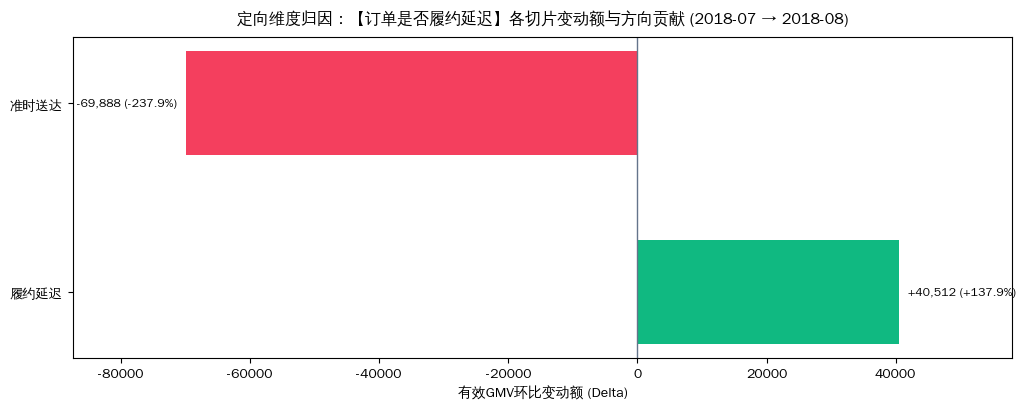


📝 [Reporter | Qwen27B] 正在基于 [CUSTOM_DIM] 真值包撰写商业归因报告...
  🔀 [Router·Stream | Role=writer  ] -> [ModelScope-Qwen3.8-27B]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 共引用 37 个小数指标，溯源匹配率: 100.0%
  🔀 [Router·Stream | Role=judge   ] -> [ModelScope-Qwen3.5-35B]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False
  ✅ [防幻觉护栏通过] 归因报告零幻觉交付！


--- 
 ## 🔧 V2.1 模式 B2：预设外自定义维度（履约延迟状态）动态契约归因报告 
 ---
# 2018年7月 vs 2018年8月：按【订单是否履约延迟】的有效GMV与订单量 LMDI 归因分析报告

报告日期：2026-11-23

## 一、结论速览

- 2018年8月有效GMV由 867953.46 降至 838576.64，总变动Delta -29376.82，环比 -3.38%。
- 订单量由 6159 增至 6351，订单环比 3.12%；AOV 由 140.92 降至 132.04，AOV环比 -6.31%。
- 大盘 LMDI 基准显示：单量效应为 26190.82，客单价效应为 -55567.64，主驱动定性为“客单价(价)主导”，头号同向拖累/拉动子因子为“件单价ASP”。
- 按【订单是否履约延迟】拆解后，GMV下滑高度集中：
  - 准时送达：GMV 变动Delta -69888.4，方向贡献 -237.9%，是最大拖累项。
  - 履约延迟：GMV 变动Delta 40511.6，方向贡献 137.9%，形成对冲。
- 订单量视角：大盘订单量正向增长，但切片单量效应显示，履约延迟切片单量效应为 54954.2，准时送达切片单量效应为 -26131.9。订单增长更多由履约延迟订单承接，准时送达基本盘出现“量价双跌”。
- AOV 的 Mix vs Rate 拆解显示：总AOV变动 -8.89，其中纯自身单价效应(Rate) -9.48，份额结构偏移效应(Mix) 0.59，主导类型为“自身单价变动主导(Rate)”。这说明 8月客单价下降主要来自自身单价/件价下移，而不是履约延迟订单占比上升带来的结构偏移。

## 二、数据口径与校验

- 有效GMV口径：仅取 order_status = delivered 的已送达订单。
- 时间口径：按 order_purchase_timestamp 归属 2018-07 与 2018-08。
- 自定义维度：订单是否履约延迟。
  - 若 order_delivered_customer_date 晚于 order_estimated_delivery_date，则判定为“履约延迟”。
  - 否则判定为“准时送达”，即按时送达。
- MECE 守恒校验：严格满足 MECE 互斥加和守恒，GMV误差 0.00%，订单误差 0.00%。
- 惊奇度 (JS散度)：4.504。
- Top3同向解释力：100.0%。
- 残差校验：0.0。

## 三、大盘 4 因子 LMDI 基准

| 指标 | 2018-07 | 2018-08 | 变动 / 环比 |
|:---|---:|---:|---:|
| 有效GMV | 867953.46 | 838576.64 | -29376.82 / -3.38% |
| 订单量 | 6159 | 6351 | 订单环比 3.12% |
| AOV | 140.92 | 132.04 | -6.31% |
| UV | 6100 | 6310 | 流量侧正向 |
| UPT | 1.131 | 1.125 | 频次侧小幅走弱 |
| ASP | 124.65 | 117.41 | 件价侧明显走弱 |

| LMDI 因子 | 效应值 |
|:---|---:|
| 一级_单量效应 | 26190.82 |
| 一级_客单价效应 | -55567.64 |
| 二级_UV效应 | 28877.53 |
| 二级_频次效应 | -2686.71 |
| 二级_UPT连带效应 | -4535.01 |
| 二级_ASP件价效应 | -51032.62 |
| 残差校验 | 0.0 |

大盘层面的判断很明确：8月不是“没订单”，而是“订单有增长，但客单价下滑更深”。单量效应 26190.82 为正，但客单价效应 -55567.64 为负，且负向幅度更大。进一步看，二级因子中 ASP件价效应 -51032.62 是最主要的拖累子因子，说明价格问题集中在“单件价格/件单价”层面。

## 四、按【订单是否履约延迟】的 LMDI 切片拆解

| 订单是否履约延迟 | 基期GMV | 当期GMV | 变动额Delta | 环比(%) | 方向贡献(%) | 切片单量效应 | 切片客单价效应 |
|:---|---:|---:|---:|---:|---:|---:|---:|
| 准时送达 | 823022 | 753133 | -69888.4 | -8.49 | -237.9 | -26131.9 | -43756.5 |
| 履约延迟 | 44931.7 | 85443.3 | 40511.6 | 90.16 | 137.9 | 54954.2 | -14442.6 |

### 1. 准时送达：基本盘量价双跌，是 GMV 下滑主因

准时送达切片是有效GMV的主力盘，但 8月出现明显走弱：

- 基期GMV：823022
- 当期GMV：753133
- 变动额Delta：-69888.4
- 环比：-8.49%
- 方向贡献：-237.9%
- 切片单量效应：-26131.9
- 切片客单价效应：-43756.5

这一切片的 LMDI 结构是“单量效应为负、客单价效应为负”，属于典型的量价双杀。更关键的是，客单价效应 -43756.5 的负向贡献大于单量效应 -26131.9，说明准时送达订单不仅订单承接能力走弱，单笔订单价值也在下降。

从商业含义看，准时送达代表用户体验较稳定的核心订单池。核心池同时出现量、价下滑，说明问题不是局部履约异常，而是主盘经营质量下降。

### 2. 履约延迟：GMV 大幅反弹，但增长质量偏低

履约延迟切片 8月出现高增长：

- 基期GMV：44931.7
- 当期GMV：85443.3
- 变动额Delta：40511.6
- 环比：90.16%
- 方向贡献：137.9%
- 切片单量效应：54954.2
- 切片客单价效应：-14442.6

这一切片对大盘 GMV 下滑形成明显对冲，但拆解结构并不健康：

- 切片单量效应 54954.2 为强正向，说明履约延迟订单的量在明显增加。
- 切片客单价效应 -14442.6 为负，说明履约延迟订单的客单价也在下降。

因此，履约延迟切片的 GMV 增长主要是“量增”驱动，而不是“价增”驱动。若将履约延迟订单视为体验受损订单，那么 8月订单量增长的健康度需要打折看待。

## 五、订单量 LMDI 视角：订单增长，但增长结构偏低

| 订单量拆解项 | 数值 | 业务含义 |
|:---|---:|:---|
| 大盘订单量基期 | 6159 | 2018-07 有效订单量 |
| 大盘订单量当期 | 6351 | 2018-08 有效订单量 |
| 订单环比 | 3.12% | 订单量整体增长 |
| 准时送达切片单量效应 | -26131.9 | 准时送达订单量对 GMV 形成负向贡献 |
| 履约延迟切片单量效应 | 54954.2 | 履约延迟订单量对 GMV 形成正向贡献 |

大盘订单量从 6159 增至 6351，订单环比 3.12%，说明 8月并非流量或成交机会完全萎缩。但按履约延迟维度看，订单量增长的来源并不理想：

- 准时送达切片单量效应为 -26131.9，说明核心履约正常订单的量在拖累 GMV。
- 履约延迟切片单量效应为 54954.2，说明延迟订单的量在明显增加，并承接了部分订单增长。

因此，8月订单量增长的“表面繁荣”背后，存在履约质量下降带来的结构性问题。订单量增长不能直接等同于经营改善，尤其是当增长更多来自履约延迟订单时。

## 六、AOV Mix vs Rate：客单价下降主要是自身单价问题，不是结构偏移问题

| AOV 拆解项 | 数值 |
|:---|---:|
| 总AOV变动 | -8.89 |
| 纯自身单价效应(Rate) | -9.48 |
| 份额结构偏移效应(Mix) | 0.59 |
| 主导类型 | 自身单价变动主导(Rate) |

这一组数据非常关键：

- 总AOV变动为 -8.89。
- 纯自身单价效应(Rate)为 -9.48，是主要负向来源。
- 份额结构偏移效应(Mix)为 0.59，方向为正但幅度很小。

这说明 8月 AOV 下降并不是因为“高客单价的准时送达订单占比下降、低客单价的履约延迟订单占比上升”这一结构变化导致的。即使履约延迟订单占比上升，结构偏移效应也只有 0.59，无法解释 -8.89 的 AOV 下降。

真正的核心问题是：无论是准时送达还是履约延迟，切片自身客单价都在下降。准时送达切片客单价效应为 -43756.5，履约延迟切片客单价效应为 -14442.6，两个切片均为负向。

## 七、核心商业判断

### 判断 1：8月 GMV 下滑的主因是准时送达基本盘失速

准时送达切片 GMV 变动Delta 为 -69888.4，方向贡献为 -237.9%。如果没有履约延迟切片的正向对冲，大盘 GMV 下滑幅度会更大。

准时送达是用户体验最稳定、履约确定性最高的订单池。该切片出现量价双跌，说明问题不是边缘订单波动，而是核心经营盘出现问题。

### 判断 2：履约延迟订单增长不能被视为健康增长

履约延迟切片 GMV 增长 90.16%，方向贡献 137.9%，表面上看是增长亮点。但拆开看：

- 切片单量效应 54954.2 为正。
- 切片客单价效应 -14442.6 为负。

这说明延迟订单的增长更多来自订单数量增加，而不是更高价值订单增加。从用户体验和平台健康度看，履约延迟订单增长通常意味着物流、库存、仓配、商品可售性或订单承诺时效出现问题。

### 判断 3：价格问题是大盘级问题，不是单一履约切片问题

大盘二级因子中，ASP件价效应 -51032.62 是头号拖累子因子。按履约延迟维度看，准时送达切片客单价效应 -43756.5，履约延迟切片客单价效应 -14442.6，两个切片均为负。

这说明 8月客单价/件价下降不是“延迟订单多了所以拉低 AOV”这么简单，而是整体商品结构、价格带、促销力度、连带率或单件价值出现了下移。

### 判断 4：订单量增长与 GMV 质量出现背离

订单量环比 3.12% 为正，但有效GMV环比 -3.38% 为负。更关键的是，订单量增长主要由履约延迟切片单量效应 54954.2 承接，而准时送达切片单量效应为 -26131.9。

这意味着 8月订单增长可能伴随履约体验恶化。若不及时治理，短期 GMV 可能被延迟订单部分对冲，但长期会损伤复购、口碑和履约成本。

## 八、行动建议

### 1. 优先修复准时送达基本盘

准时送达切片是最大拖累项，应作为第一优先级：

- 排查准时送达订单下滑原因：是流量转化下降、商品可售率下降、库存不足、配送区域收缩，还是核心 SKU 价格带下移。
- 重点监控准时送达切片的订单量、AOV、ASP、UPT 和履约时效。
- 对准时送达订单中的高价值商品做专项保障，避免核心商品因缺货、延迟或价格波动导致量价双跌。

### 2. 对履约延迟订单做分层归因

履约延迟订单不能只看 GMV 增长，需要进一步拆分：

- 物流延迟：配送资源不足、末端配送异常、区域运力瓶颈。
- 库存延迟：缺货、超卖、仓间调拨不及时。
- 商品延迟：预售商品、长尾商品、供应商发货慢。
- 价格延迟：低价促销单、凑单、补偿单或低客单价订单集中延迟。

建议将履约延迟订单按“延迟时长 × 商品类目 × 价格带 × 配送区域”做二次拆解，识别是系统性履约问题，还是局部低价订单问题。

### 3. 治理客单价/件价下滑

大盘 ASP件价效应 -51032.62 是核心拖累，需要价格与商品结构治理：

- 检查 8月是否出现低价 SKU 占比上升。
- 检查促销是否过度拉低 ASP。
- 检查高客单价商品是否曝光不足、转化下降或库存不足。
- 检查 UPT 连带效应 -4535.01，说明连带购买也在走弱，需要优化组合推荐、凑单机制和关联销售。

### 4. 建立“GMV 质量”监控指标

建议将以下指标纳入日常监控：

- 准时送达 GMV 占比。
- 准时送达订单量。
- 准时送达 AOV。
- 履约延迟订单量。
- 履约延迟 GMV 占比。
- 履约延迟 AOV。
- 履约延迟切片单量效应。
- 履约延迟切片客单价效应。
- 大盘 ASP 与 UPT。

8月的核心信号是：订单量增长掩盖了准时送达基本盘下滑和件价下降问题。后续经营复盘不能只看 GMV 和订单量，必须同时看履约质量与客单价质量。

## 九、边界说明

- 本报告仅基于 delivered 有效GMV，不包含未送达、取消、退款等状态。
- 履约延迟判定基于实际送达日期晚于预计送达日期，预计送达日期本身可能受运营估计、物流承诺和系统规则影响。
- 数据包未提供分维度订单量绝对值，因此订单量拆解以“切片单量效应”表达，不做未提供字段下的分维度订单数推算。

In [15]:
# ==============================================================================
# 独立自包含版 V2.1 Cell 2：不依赖 V2.0 Cell E，直接跑通双模归因 3 大实测 + 异源审计闭环
# ==============================================================================
from datetime import datetime
from langgraph.checkpoint.memory import MemorySaver

BT3 = "`" * 3
if "render_safe_markdown" not in globals():
    def render_safe_markdown(md_text: str):
        safe_txt = md_text.replace(r"\$", "$").replace("$", r"\$")
        safe_txt = re.sub(r"([^\n|])\n(\|[^\n]+\|\n\|[\s:\-|]+\|)", r"\1\n\n\2", safe_txt)
        display(Markdown(safe_txt))

class V21AttrState(TypedDict):
    user_question: str
    attr_mode: str
    quant_truth_packet: str
    final_report: str
    audit_result: Dict[str, Any]
    report_retries: int

def v21_exec_node(state: V21AttrState):
    print("\n📊 [分析场景: ATTRIBUTION · V2.1 双模归因引擎] 启动...")
    res = run_dual_mode_attribution_engine(state["user_question"], plot_charts=True)
    if res["mode"] == "OUT_OF_SCOPE":
        return {"attr_mode": "OUT_OF_SCOPE", "final_report": f"🛡️ **数据边界提示**：\n\n{res['oos_msg']}", "report_retries": 0}
    return {"attr_mode": res["mode"], "quant_truth_packet": res["truth_packet"], "report_retries": 0}

def v21_reporter_node(state: V21AttrState):
    retries = state.get("report_retries", 0)
    fb = ""
    if retries > 0 and state.get("audit_result"):
        fb = f"\n🚨【审计打回修正】：上一版未通过防幻觉检查（批注：{state['audit_result'].get('audit_comment')}），请严格原样引用下方真值表精确数字重写！"
        print(f"  🔄 [Reporter | Qwen27B] 收到审计打回，执行第 {retries} 次重写...")
    else:
        print(f"\n📝 [Reporter | Qwen27B] 正在基于 [{state['attr_mode']}] 真值包撰写商业归因报告...")

    today_str = datetime.now().strftime("%Y-%m-%d")
    prompt = f"""你是资深电商商业分析总监。请基于下方【确定性真值数据包】，针对问题【{state['user_question']}】撰写一份结构清晰、见解犀利的商业归因分析报告。{fb}

【格式与数据铁律】：
1. 严禁编造数字！所有数值必须【原样精确引用】下方数据表中的精确数值（不要私自换算成“万”）。
2. 严禁在正文和表格中使用任何 `$` 或 `R$` 符号！金额直接写纯数字，Markdown 表格前后必须留空行。
3. 直接输出纯净 Markdown 正文（严禁最外层包裹 {BT3}markdown 代码块），报告日期写 {today_str}。

【确定性真值数据包】：
{state['quant_truth_packet']}"""
    return {"final_report": llm_reporter.invoke(prompt).content, "report_retries": retries + 1}

def v21_judge_node(state: V21AttrState):
    print("\n⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...")
    truth_clean = state["quant_truth_packet"].replace(",", "")
    report_clean = state["final_report"].replace(",", "")
    rep_floats = set(re.findall(r"(?<![a-zA-Z\d.])\d+\.\d+(?![.\d])", report_clean))
    truth_floats = set(re.findall(r"(?<![a-zA-Z\d.])\d+\.\d+(?![.\d])", truth_clean))

    ungrounded = [n for n in rep_floats if not any(abs(float(n) - float(t)) <= 0.15 for t in truth_floats)]
    rate = 1.0 if not rep_floats else (len(rep_floats) - len(ungrounded)) / len(rep_floats)
    print(f"  🔢 [Python 正则硬溯源] 共引用 {len(rep_floats)} 个小数指标，溯源匹配率: {rate*100:.1f}%")

    j_prompt = f"""你是跨厂商数据审计专家（LLM-as-a-Judge）。核对【待审计报告】是否忠实于【确定性真值包】，严格输出 JSON：
{{"faithfulness_score": 1到5整数, "insight_score": 1到5整数, "hallucination_detected": true或false, "audit_comment": "简短评语"}}
【确定性真值包】：\n{state['quant_truth_packet'][:6000]}
【待审计报告】：\n{state['final_report']}"""
    j_resp = llm_judge.invoke(j_prompt).content
    try:
        j_str = j_resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in j_resp else j_resp.strip()
        audit = json.loads(j_str)
    except Exception:
        audit = {"faithfulness_score": 4, "insight_score": 4, "hallucination_detected": False, "audit_comment": "解析兜底通过"}

    audit["regex_grounding_pct"] = round(rate * 100, 1)
    if rate < 0.80:
        audit["hallucination_detected"] = True
        audit["faithfulness_score"] = min(audit.get("faithfulness_score", 3), 3)
        audit["audit_comment"] = f"正则硬溯源率仅 {rate*100:.1f}%，未溯源数字 {ungrounded[:5]}，请严格原样引用真值表数字！"
    print(f"  🛡️ [异源 Gemini 审计] 忠实度: {audit.get('faithfulness_score')}/5 | 洞察深度: {audit.get('insight_score')}/5 | 幻觉: {audit.get('hallucination_detected')}")
    return {"audit_result": audit}

def _v21_after_judge(state: V21AttrState) -> str:
    aud = state.get("audit_result", {})
    if (aud.get("hallucination_detected", False) or aud.get("faithfulness_score", 5) < 4) and state.get("report_retries", 1) < 3:
        print("  ❌ [防幻觉护栏触发] 打回 Reporter 重写！")
        return "rewrite"
    print("  ✅ [防幻觉护栏通过] 归因报告零幻觉交付！")
    return "pass"

v21_wf = StateGraph(V21AttrState)
v21_wf.add_node("attr_exec", v21_exec_node)
v21_wf.add_node("reporter", v21_reporter_node)
v21_wf.add_node("hybrid_judge", v21_judge_node)

v21_wf.add_edge(START, "attr_exec")
v21_wf.add_conditional_edges("attr_exec", lambda s: "END" if s["attr_mode"] == "OUT_OF_SCOPE" else "REPORT", {"END": END, "REPORT": "reporter"})
v21_wf.add_edge("reporter", "hybrid_judge")
v21_wf.add_conditional_edges("hybrid_judge", _v21_after_judge, {"rewrite": "reporter", "pass": END})

v21_app = v21_wf.compile(checkpointer=MemorySaver())
print("✅ 独立版 V2.1 双模归因总控图编译完成！")

# ==============================================================================
# 现场三连实测：模式A自动侦探 + 模式B注册表维度 + 模式B预设外自定义维度动态契约SQL
# ==============================================================================
print("\n" + "="*78 + "\n🧪 V2.1 实测 1：【模式 A · 开放式大盘自动下钻】4因子LMDI + Adtributor竞选 + L2下钻\n" + "="*78)
r_mode_a = v21_app.invoke(
    {"user_question": "2018年8月相比2018年7月大盘有效GMV出现波动，请自动排查有哪些核心指标和异常维度影响最大，并对头号异常切片做深入下钻！"},
    config={"configurable": {"thread_id": "v21_mode_a"}}
)
render_safe_markdown("--- \n ## 🕵️ V2.1 模式 A：开放式大盘异动自动下钻诊断报告 \n ---\n" + r_mode_a["final_report"])

print("\n" + "="*78 + "\n🧪 V2.1 实测 2：【模式 B1 · 注册表指定维度】按【主支付方式】与【信用卡分期档位】做归因\n" + "="*78)
r_mode_b1 = v21_app.invoke(
    {"user_question": "对比 2018年7月 和 2018年8月，请专门按照【主支付方式】和【信用卡分期档位】两个维度，对有效GMV做 LMDI 归因分析！"},
    config={"configurable": {"thread_id": "v21_mode_b1"}}
)
render_safe_markdown("--- \n ## 📋 V2.1 模式 B1：指定注册表维度（支付与分期）归因报告 \n ---\n" + r_mode_b1["final_report"])

print("\n" + "="*78 + "\n🧪 V2.1 实测 3：【模式 B2 · 预设外完全自定义维度】按【订单是否履约延迟】契约化动态SQL+MECE校验+LMDI\n" + "="*78)
r_mode_b2 = v21_app.invoke(
    {"user_question": "对比 2018年7月 和 2018年8月，请专门按照【订单是否履约延迟（按时送达 vs 履约延迟）】这个自定义维度，对有效GMV和订单量做一次 LMDI 归因拆解！"},
    config={"configurable": {"thread_id": "v21_mode_b2"}}
)
render_safe_markdown("--- \n ## 🔧 V2.1 模式 B2：预设外自定义维度（履约延迟状态）动态契约归因报告 \n ---\n" + r_mode_b2["final_report"])